# First Practical Laboratory: The Lean Network Challenge

**Machine Learning Technologies (MUCEIM)**

**Student Name:** Jesús Inurria

**Date:** 22/11/2026

---

## Instructions

1. **Make a copy** of this notebook to your own Google Drive (`File > Save a copy in Drive`) and select a runtime with a GPU (`Runtime > Change runtime type`)
2. **Train the reference model first** (Section 4) without changing it. It sets your target
3. **Fill in all empty code cells** as instructed
4. **Document your analysis** in the markdown cells provided
5. **Ensure the entire notebook runs** from top to bottom without errors (`Runtime > Restart and run all`)
6. **Share the final notebook** with "Anyone with the link can view" and include the link in your PDF report

---

> **Main run (local CPU).** All analyses and conclusions in this notebook were written from this run, and every number in the text refers to it. When we later ran the same notebook on Google Colab (GPU T4) as a check, the results differed slightly, which surprised us, so I decided to include that run as a second notebook and to discuss the differences in the section *Reproducibility: local CPU vs Colab GPU*. The main ideas and conclusions remain valid: the final model and its result are the same in both runs.

## 1. Import Libraries

Import the libraries for your experiments and fix the random seeds for reproducibility.

In [1]:
# Import necessary libraries
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set random seeds for reproducibility (Python, NumPy and TensorFlow)
keras.utils.set_random_seed(42)

# Check versions and hardware
print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.21.0


GPU available: []


## 2. Dataset Selection and Loading

Choose your dataset from the options provided in the assignment document:
- MNIST
- Fashion-MNIST
- Kuzushiji-MNIST (KMNIST)
- CIFAR-10
- A public dataset of your choice (with justification)

Uncomment the lines of your dataset, then inspect the data.

In [2]:
# Load your chosen dataset (uncomment ONE option)

# Option 1: MNIST
# from tensorflow.keras.datasets import mnist
# (x_train, y_train), (x_test, y_test) = mnist.load_data()

# Option 2: Fashion-MNIST
from tensorflow.keras.datasets import fashion_mnist
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Option 3: Kuzushiji-MNIST (KMNIST), images of shape 28x28x1
# import tensorflow_datasets as tfds
# (x_train, y_train), (x_test, y_test) = tfds.as_numpy(
#     tfds.load('kmnist', split=['train', 'test'], batch_size=-1, as_supervised=True))

# Option 4: CIFAR-10
# from tensorflow.keras.datasets import cifar10
# (x_train, y_train), (x_test, y_test) = cifar10.load_data()

# YOUR CODE HERE (only if you use a dataset of your own choice)


x_train: (60000, 28, 28) uint8, y_train: (60000,) uint8
x_test: (10000, 28, 28), y_test: (10000,)
Pixel range: 0 to 255
Number of classes: 10
Samples per class (train): [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


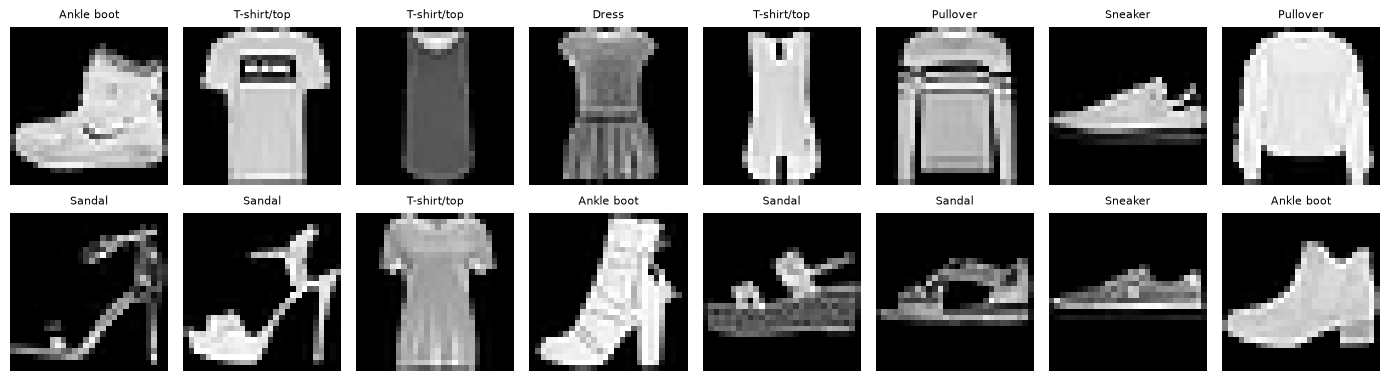

In [3]:
# Inspect the dataset (raw arrays, before preprocessing)
print(f"x_train: {x_train.shape} {x_train.dtype}, y_train: {y_train.shape} {y_train.dtype}")
print(f"x_test: {x_test.shape}, y_test: {y_test.shape}")
print(f"Pixel range: {x_train.min()} to {x_train.max()}")
print(f"Number of classes: {len(np.unique(y_train))}")
print("Samples per class (train):", np.bincount(y_train))

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, i in zip(axes.ravel(), range(16)):
    ax.imshow(x_train[i], cmap='gray')
    ax.set_title(class_names[y_train[i]], fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Dataset Choice Justification

**Dataset Selected:** Fashion-MNIST

**Justification:** Fashion-MNIST has the same format as MNIST (28x28 grayscale images, 10 classes, 60,000 training images) but is harder: a plain MLP does not saturate near 100 %, so there is real room to see accuracy degrade as the network shrinks. That makes the trade-off between parameters and accuracy visible, which is the point of a challenge about small networks. It is also small enough to train many MLPs quickly.

## 3. Data Preprocessing

The cell below gives a default preprocessing that works for the image datasets of the assignment:
- labels as a flat vector of integers
- pixel values scaled to [0, 1]
- 10% of the training data kept apart as a validation set

Adapt it if you use a dataset of your own choice. If you study the input size in your experiments, the commented lines at the end show one way to resize the images.

In [4]:
# Default preprocessing (adapt it if you need to)

# Labels as a flat vector of integers (CIFAR-10 labels come with an extra dimension)
y_train = np.asarray(y_train).reshape(-1).astype('int64')
y_test = np.asarray(y_test).reshape(-1).astype('int64')

# Pixel values scaled to [0, 1]
x_train = np.asarray(x_train, dtype='float32') / 255.0
x_test = np.asarray(x_test, dtype='float32') / 255.0

# Validation set: 10% of the training data, chosen at random with a fixed seed
rng = np.random.default_rng(42)
idx = rng.permutation(len(x_train))
n_val = int(0.1 * len(x_train))
x_val, y_val = x_train[idx[:n_val]], y_train[idx[:n_val]]
x_train, y_train = x_train[idx[n_val:]], y_train[idx[n_val:]]

input_shape = x_train.shape[1:]
num_classes = int(len(np.unique(y_train)))

print(f"Training: {x_train.shape}, validation: {x_val.shape}, test: {x_test.shape}")
print(f"Input shape: {input_shape}, classes: {num_classes}")

# Example for the input-size experiment: resize the images to size x size pixels (14 for 28x28 images, 16 for CIFAR-10)
# def resize(x, size=14):
#     if x.ndim == 3:  # MNIST and Fashion-MNIST images have no channel dimension
#         x = x[..., None]
#     return tf.image.resize(x, (size, size), method='area').numpy()
# x_train_small, x_val_small, x_test_small = resize(x_train), resize(x_val), resize(x_test)


Training: (54000, 28, 28), validation: (6000, 28, 28), test: (10000, 28, 28)
Input shape: (28, 28), classes: 10


## 4. The Reference Model (provided)

Run the next cell **without changing it**. It trains the reference model of the challenge, a fully connected network with two hidden layers of 512 ReLU units, and computes your target: the reference test accuracy minus one percentage point.

In [5]:
def build_reference_model(input_shape, num_classes):
    """Reference model of the challenge. Do not change it."""
    model = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dense(512, activation='relu'),
        layers.Dense(num_classes, activation='softmax'),
    ], name='reference')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

keras.utils.set_random_seed(42)
reference = build_reference_model(input_shape, num_classes)
reference.summary()

start = time.time()
history_ref = reference.fit(x_train, y_train,
                            validation_data=(x_val, y_val),
                            epochs=20, batch_size=128, verbose=2)
print(f"Training time: {time.time() - start:.0f} s")

ref_params = reference.count_params()
ref_test_loss, ref_test_acc = reference.evaluate(x_test, y_test, verbose=0)
target_acc = ref_test_acc - 0.01

print(f"Reference parameters: {ref_params:,}")
print(f"Reference test accuracy: {ref_test_acc:.4f}")
print(f"YOUR TARGET: a mean test accuracy of at least {target_acc:.4f}, with as few parameters as possible")

Model: "reference"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 669,706 (2.55 MB)

 Trainable params: 669,706 (2.55 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


... (37 outputs left out)

Epoch 20/20


422/422 - 6s - 13ms/step - accuracy: 0.9500 - loss: 0.1331 - val_accuracy: 0.8932 - val_loss: 0.3506


Training time: 108 s


Reference parameters: 669,706
Reference test accuracy: 0.8833
YOUR TARGET: a mean test accuracy of at least 0.8733, with as few parameters as possible


In [6]:
# Diagnostic (not part of the official target): the guide used during the search is based on
# the FINAL validation accuracy of the reference, G = val_accuracy[-1] - 0.01.
# G uses the final-epoch (epoch 20) validation accuracy of the reference, the same quantity used for the candidates.
final_val_ref = history_ref.history['val_accuracy'][-1]
G = final_val_ref - 0.01
best_val_ref = max(history_ref.history['val_accuracy'])

print(f"G (final val acc of the reference - 0.01): {G:.4f}")
print(f"Reference final validation accuracy:       {final_val_ref:.4f}")
print(f"Reference best validation accuracy:           {best_val_ref:.4f}")
print(f"best_val_ref - ref_test_acc:              {best_val_ref - ref_test_acc:+.4f}")

G (final val acc of the reference - 0.01): 0.8832
Reference final validation accuracy:       0.8932
Reference best validation accuracy:           0.8952
best_val_ref - ref_test_acc:              +0.0119


### Analysis of the Reference Model

Plot the training history of the reference model. The helper function `plot_histories` works for any list of models, so you can reuse it in your experiments.

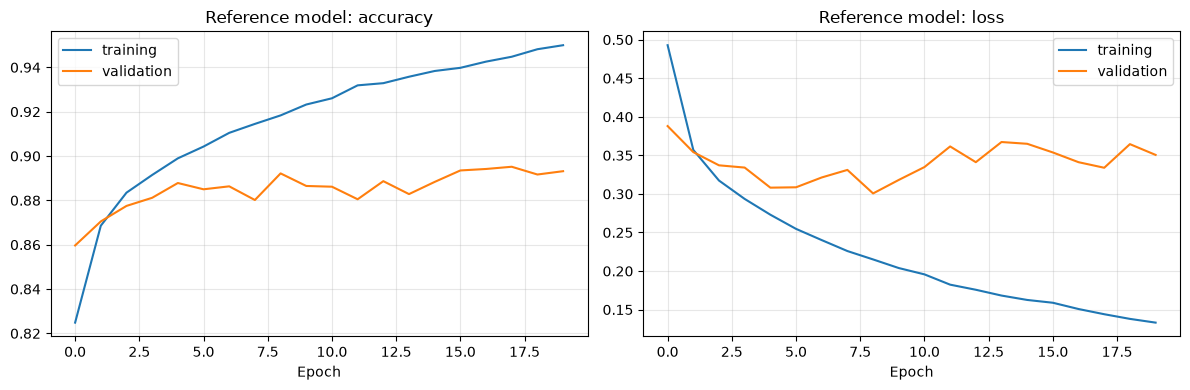

In [7]:
def plot_histories(histories, names, title=''):
    """Plot validation accuracy and loss for several training histories."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for history, name in zip(histories, names):
        axes[0].plot(history.history['val_accuracy'], label=name)
        axes[1].plot(history.history['val_loss'], label=name)
    axes[0].set_title('Validation accuracy')
    axes[1].set_title('Validation loss')
    for ax in axes:
        ax.set_xlabel('Epoch')
        ax.legend()
        ax.grid(alpha=0.3)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

# Training and validation curves of the reference model
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_ref.history['accuracy'], label='training')
axes[0].plot(history_ref.history['val_accuracy'], label='validation')
axes[0].set_title('Reference model: accuracy')
axes[1].plot(history_ref.history['loss'], label='training')
axes[1].plot(history_ref.history['val_loss'], label='validation')
axes[1].set_title('Reference model: loss')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Reference Model Analysis:**

*Final figures (epoch 20, seed 42).* Training accuracy 0.9500 (loss 0.1331), validation accuracy 0.8932 (loss 0.3506), test accuracy 0.8833. The official target is therefore a mean test accuracy of at least 0.8733.

*Overfitting.* The curves show a classic high-variance pattern. Training loss falls monotonically (0.4928 to 0.1331) and training accuracy keeps rising, but validation loss reaches its minimum of 0.3006 at epoch 9 and then drifts upwards to 0.3506, while validation accuracy plateaus and oscillates between 0.8802 and 0.8952 from epoch 5 onwards. The final train-validation gap is 0.9500 - 0.8932 = 5.7 pp. After epoch 9 the extra epochs mostly make the network more confident on training examples (lower training loss) without clear improvement in accuracy (+0.3 pp at best: 0.8922 at epoch 9, peak 0.8952 at epoch 18), and on the loss even hurting generalisation: the model has more capacity than the task needs.

*Where the parameters are.* The first layer holds 401,920 of the 669,706 parameters (784 x 512 + 512), i.e. 60.0 %; the second holds 262,656 (39.2 %) and the output layer only 5,130. Any reduction must therefore act on the product *input size x width* of the first layer and on the 512 x 512 block between the hidden layers. Given the overfitting, we expect the width to be the first thing that can shrink with little loss (Experiment 1), and the input dimension the next one.

*Validation guide versus test target.* G = final-epoch validation accuracy of the reference - 0.01 = 0.8932 - 0.01 = 0.8832; decision threshold G + 0.003 = 0.8862 (the 0.3 pp margin is a buffer against seed noise): a candidate passes only if its 3-seed mean validation accuracy M >= G + 0.003. We use the final epoch (epoch 20) for both the reference and the candidates so that they are compared on the same quantity. For the reference, best val exceeds test by +1.19 pp (0.8952 vs 0.8833), and even the final val accuracy exceeds test by 0.99 pp. A plausible but unverified assumption is that lean models show a similar val-test gap, in which case passing on validation leaves room above the test target; this cannot be checked without looking at test, so it is not used for any decision. The test set is used only here and for the final lean model; all selection uses validation.

## 5. Results Table

Record **every** model you train with the `record` function, so that you can compare them and draw the plot of accuracy against parameters in Section 7. Use the validation accuracy to make your decisions, and keep the test set for the reference and your final lean model.

In [8]:
# WARNING: re-running single cells duplicates records in `results`; use Restart & run all.
results = []

def record(name, model, history, test_acc=None):
    """Store the main figures of a trained model in the results table."""
    results.append({
        'model': name,
        'parameters': model.count_params(),
        # Added to the template: final training accuracy, to observe overfitting better (train - val gap)
        'final_train_accuracy': history.history['accuracy'][-1],
        'best_val_accuracy': max(history.history['val_accuracy']),
        'final_val_accuracy': history.history['val_accuracy'][-1],
        'test_accuracy': test_acc,
    })
    return pd.DataFrame(results)

record('Reference', reference, history_ref, ref_test_acc)

,model,parameters,final_train_accuracy,best_val_accuracy,final_val_accuracy,test_accuracy
0,Reference,669706,0.95,0.895167,0.893167,0.8833


In [9]:
# Helpers shared by all experiments, so that only the factor under study changes.
# Common protocol: Adam 1e-3 by default (the experiments take optimizer/lr/prefix so that they can be repeated
# with another optimiser), 20 epochs, batch 128, no early stopping.
import math

# Keras runs a whole epoch inside the TensorFlow graph when steps_per_execution equals the number of batches:
# Python only intervenes once per epoch (validation and history), so training is faster. It does not change
# the computations: verified locally (final validation accuracy identical to 6 decimals, seed 42, with and
# without it) for E1 784-64-64 and 784-32-32. The reference cell of Section 4 does not use it.
steps_per_epoch = math.ceil(len(x_train) / 128)

# ---- Decision helpers -------------------------------------------------------------------------------------
# The validation set has 6,000 images, so every final validation accuracy is a multiple of 1/6000 and the mean
# of three seeds a multiple of 1/18000. Such a mean can land EXACTLY on the threshold, and floating-point
# rounding would then decide the outcome at random. The rule says M >= threshold, so equality must count as
# passing: all comparisons use a tolerance (1e-9) that is far smaller than the 1/18000 grain.
EPS = 1e-9
threshold = G + 0.003            # pass threshold = G + 0.3 pp (G: diagnostic cell of Section 4)

def at_least(a, b):
    """a >= b, with equality (up to rounding) counted as true."""
    return a >= b - EPS

def exceeds(a, b):
    """a > b strictly: a difference that is only rounding noise does not count as exceeding."""
    return a > b + EPS

# Convention note: `at_least` counts a difference equal to the tolerance as passing, whereas `exceeds` is strict
# (delta == tol does NOT count). Use the one that matches the decision rule; no decision lies exactly on the
# boundary, so no outcome depends on it.
def passes(M):
    """Does a (mean) validation accuracy M reach the pass threshold? Used in EVERY decision."""
    return at_least(M, threshold)

def mlp_params(d, units):
    """Parameters of a Dense network: (inputs + 1 bias) * outputs for each layer, with a 10-class softmax output."""
    sizes = [d] + list(units) + [10]
    return sum((a + 1) * b for a, b in zip(sizes[:-1], sizes[1:]))

def flat(x):
    """Flatten each image into a vector (the MLP takes vectors of size input_dim)."""
    return x.reshape(len(x), -1)

def make_optimizer(name, lr):
    """Adam, RMSprop or SGD with momentum 0.9."""
    if name == 'adam':
        return keras.optimizers.Adam(learning_rate=lr)
    if name == 'rmsprop':
        return keras.optimizers.RMSprop(learning_rate=lr)
    if name == 'sgd':
        return keras.optimizers.SGD(learning_rate=lr, momentum=0.9)
    raise ValueError(name)

def build_mlp(input_dim, hidden_units, activation='relu', num_classes=10,
              dropout=0.0, l1=0.0, l2=0.0, batchnorm=False, optimizer='adam', lr=1e-3):
    """Fully connected network: one Dense layer per entry of hidden_units, then a softmax output.
    The optional arguments default to 'nothing extra': the defaults give exactly the
    plain Dense(activation) network of E1-E3.
    activation: a Keras name, or 'leaky_relu' = LeakyReLU with negative_slope=0.1 (Keras 3 defaults to 0.3).
    dropout: rate applied after each hidden activation (not on the input nor the output).
    l1, l2: penalties on the kernels of the HIDDEN Dense layers only (not the biases, and not the output layer); both > 0 gives l1_l2.
    batchnorm: Dense -> BatchNormalization -> activation (adds 4 parameters per hidden unit)."""
    model = keras.Sequential([keras.Input(shape=(input_dim,))])
    if l1 > 0 and l2 > 0:
        reg = keras.regularizers.l1_l2(l1=l1, l2=l2)
    elif l1 > 0:
        reg = keras.regularizers.l1(l1)
    elif l2 > 0:
        reg = keras.regularizers.l2(l2)
    else:
        reg = None
    for units in hidden_units:
        if batchnorm or activation == 'leaky_relu':
            model.add(layers.Dense(units, kernel_regularizer=reg))      # linear; the activation comes after (L2 only on hidden kernels)
            if batchnorm:
                model.add(layers.BatchNormalization())
            if activation == 'leaky_relu':
                model.add(layers.LeakyReLU(negative_slope=0.1))        # no extra parameters
            else:
                model.add(layers.Activation(activation))
        else:
            model.add(layers.Dense(units, activation=activation, kernel_regularizer=reg))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(num_classes, activation='softmax'))
    model.compile(optimizer=make_optimizer(optimizer, lr),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'],
                  steps_per_execution=steps_per_epoch)
    return model

# Histories of every trained model by name, so that E5 can reuse the control without retraining it.
HISTS = {}

def train_candidate(name, x_tr, y_tr, x_va, y_va, hidden_units, seed,
                    activation='relu', epochs=20, batch_size=128, **build_kw):
    """Train one candidate with the common protocol and record it (WITHOUT test accuracy).
    build_kw: optional build_mlp arguments (dropout, l1, l2, batchnorm, optimizer, lr).
    Returns the model, its history and the training time in seconds."""
    x_tr, x_va = flat(x_tr), flat(x_va)
    keras.utils.set_random_seed(seed)  # right before building, so weights depend only on the seed
    model = build_mlp(x_tr.shape[1], hidden_units, activation, num_classes, **build_kw)
    start = time.time()
    history = model.fit(x_tr, y_tr, validation_data=(x_va, y_va),
                        epochs=epochs, batch_size=batch_size, verbose=0)
    seconds = time.time() - start
    record(name, model, history)
    HISTS[name] = history
    print(f"{name}: {model.count_params():,} params, "
          f"train {history.history['accuracy'][-1]:.4f}, "
          f"val {history.history['val_accuracy'][-1]:.4f}, "
          f"{seconds / epochs:.2f} s/epoch")
    return model, history, seconds

# ---- 784-input 512-512 network (the reference architecture) ---------------------------------------------------
# E1 (h = 512) and E2 (d = 784) both need this network. It is trained at most once per (optimiser, lr, seed):
# with Adam 1e-3 and seed 42 it IS the reference (history_ref, Section 4), so nothing is trained for it.
FULL784 = {('adam', 1e-3, 42): history_ref}

def full784(seed, optimizer='adam', lr=1e-3, name='full784'):
    """History of the 784-512-512 network for this seed and optimiser: from the cache, or trained and cached.
    The callers (screen_e1, confirm_e1, screen, confirm) assert that non-Adam names carry a prefix."""
    key = (optimizer, lr, seed)
    if key not in FULL784:
        _, FULL784[key], _ = train_candidate(name, flat(x_train), y_train, flat(x_val), y_val,
                                             hidden_units=[512, 512], seed=seed, optimizer=optimizer, lr=lr)
    return FULL784[key]

def plot_train_val(histories, names, title=''):
    """Training (dashed) and validation (solid) accuracy and loss, one colour per model."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for k, (history, name) in enumerate(zip(histories, names)):
        color = f'C{k}'
        epochs_axis = np.arange(1, len(history.history['loss']) + 1)  # epochs counted from 1
        for ax, metric in zip(axes, ['accuracy', 'loss']):
            ax.plot(epochs_axis, history.history[metric], '--', color=color, alpha=0.7)
            ax.plot(epochs_axis, history.history['val_' + metric], '-', color=color, label=name)
    axes[0].set_title('Accuracy (dashed: training, solid: validation)')
    axes[1].set_title('Loss (dashed: training, solid: validation)')
    for ax in axes:
        ax.set_xlabel('Epoch')
        ax.set_xticks(range(1, 21, 1))
        ax.tick_params(axis='x', labelsize=7)
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## 6. Systematic Experimentation

Conduct at least **THREE** systematic experiments. For each experiment:
1. State your hypothesis clearly
2. Implement the variation, changing one factor at a time
3. Train the models and evaluate them on the validation set
4. Record every model in the results table
5. Plot and analyze the results, and compare them with the reference

---

### Experiment 1: Width at full input (784)

We vary one factor, the number of neurons per hidden layer (two equal hidden layers), keeping the input at the full 784 pixels and the rest of the reference configuration fixed (ReLU, Adam 1e-3, 20 epochs, batch 128). The question is how narrow the network can be made before the validation accuracy falls below the threshold.

**Hypothesis:** The curves, in both loss and accuracy, clearly show that the model overfits. While the epochs advance, the training loss decreases, but the validation loss oscillates without improving. Likewise, the training accuracy keeps increasing, but the validation accuracy oscillates. This is why we could stop training earlier and obtain the same results. This overfitting makes it clear that the model is so complex that it simply memorises the training data; therefore, a simpler model should obtain similar results.

**Design:** Thus, the next experiment is a grid in which the number of neurons of each hidden layer is halved. That is, we start with an initial width of 256 neurons instead of 512 and reduce it down to 8. We keep the smallest model that meets the quality requirements.

In [10]:
# Experiment 1, helpers: the width sweep is wrapped in functions so that it can be repeated with another optimiser
# (optimizer, lr, prefix) without copying code. With Adam 1e-3 and prefix='' the model names, the trained models and
# the results table are exactly those of the original run. The prefix keeps other optimisers' models apart.
widths = [256, 128, 64, 32, 16, 8]
e1_expected = {256: 269322, 128: 118282, 64: 55050, 32: 26506, 16: 13002, 8: 6442}

def screen_e1(optimizer='adam', lr=1e-3, prefix=''):
    """Seed-42 width sweep. Returns e1 (width -> history and parameters) and the seconds per epoch of each width."""
    assert prefix or (optimizer, lr) == ('adam', 1e-3)  # a non-Adam model must never be recorded without a prefix
    # h = 512 anchor: with Adam 1e-3 this is the reference history from Section 4 (nothing is trained)
    e1 = {512: {'history': full784(42, optimizer, lr, name=f'{prefix}E1-784-512x2-s42'),
                'params': mlp_params(784, [512, 512])}}
    e1_epoch_time = {}
    for h in widths:
        model, history, seconds = train_candidate(f'{prefix}E1-784-{h}x2-s42', x_train, y_train, x_val, y_val,
                                                  hidden_units=[h, h], seed=42, optimizer=optimizer, lr=lr)
        assert model.count_params() == e1_expected[h], (h, model.count_params())  # matches the plan
        assert model.count_params() == mlp_params(784, [h, h])
        e1[h] = {'history': history, 'params': model.count_params()}
        e1_epoch_time[h] = seconds / 20
    return e1, e1_epoch_time

def show_e1(e1, e1_epoch_time):
    """Comparison table and training/validation curves of the seed-42 sweep. Returns the table."""
    rows = []
    for h in [512] + widths:
        hist = e1[h]['history'].history
        rows.append({
            'hidden units': h,
            'parameters': e1[h]['params'],
            'final train acc': hist['accuracy'][-1],
            'final val acc': hist['val_accuracy'][-1],
            'best val acc': max(hist['val_accuracy']),
            'gap (train - val)': hist['accuracy'][-1] - hist['val_accuracy'][-1],
            'final val loss': hist['val_loss'][-1],
            'min val loss': min(hist['val_loss']),
            # Student request: does this width meet the decision criterion (seed-42 screening; the final decision uses M over 3 seeds, next cell)?
            'final val acc >= G + 0.003': passes(hist['val_accuracy'][-1]),
        })
    e1_table = pd.DataFrame(rows).set_index('hidden units')
    display(e1_table.round(4))
    print("Seconds per epoch (seed 42):", {h: round(t, 2) for h, t in e1_epoch_time.items()})

    # Two figures so that the curves of the wide networks (zone 0.85-0.95) stay readable
    wide = [h for h in [512] + widths if h >= 64]
    narrow = [h for h in [512] + widths if h <= 32]
    plot_train_val([e1[h]['history'] for h in wide], [f'h={h}' for h in wide],
                   'Experiment 1: wide networks (h >= 64)')
    plot_train_val([e1[h]['history'] for h in narrow], [f'h={h}' for h in narrow],
                   'Experiment 1: narrow networks (h <= 32)')
    return e1_table

def confirm_e1(e1, optimizer='adam', lr=1e-3, prefix=''):
    """Confirm the width with seeds 7 and 126, from the seed-42 frontier upwards; stop at the first width whose
    3-seed mean passes. Returns (chosen_h, val_runs); chosen_h is None if no width passes."""
    assert prefix or (optimizer, lr) == ('adam', 1e-3)
    val42 = {h: e1[h]['history'].history['val_accuracy'][-1] for h in e1}  # h = 512 is the reference
    widths_asc = sorted(val42)
    ok42 = [h for h in widths_asc if passes(val42[h])]
    fail_below = [h for h in widths_asc if ok42 and h < ok42[0]]  # all of them fail (ok42[0] is the smallest passing)
    start = max(fail_below) if fail_below else (ok42[0] if ok42 else widths_asc[0])

    val_runs = {}  # width -> final val accuracy for seeds 42, 7, 126
    chosen_h = None
    for h in [w for w in widths_asc if w >= start]:
        runs = [val42[h]]  # seed 42 is already trained (h = 512: the reference), not retrained
        for seed in [7, 126]:
            name = f'{prefix}E1-784-{h}x2-s{seed}'
            if h == 512:
                hist = full784(seed, optimizer, lr, name=name)  # trained once and shared with E2 (d = 784)
            else:
                _, hist, _ = train_candidate(name, x_train, y_train, x_val, y_val,
                                             hidden_units=[h, h], seed=seed, optimizer=optimizer, lr=lr)
            runs.append(hist.history['val_accuracy'][-1])
        val_runs[h] = runs
        print(f"h = {h}: val s42/s7/s126 = {[round(v, 4) for v in runs]}, mean = {np.mean(runs):.4f}, passes: {passes(np.mean(runs))}")
        if passes(np.mean(runs)):
            chosen_h = h  # first (smallest) width whose 3-seed mean passes
            break
    return chosen_h, val_runs

In [11]:
# Experiment 1: width sweep with seed 42 (h = 512 is the reference, reused from Section 4)
e1, e1_epoch_time = screen_e1()  # width -> history and parameters (seed 42); widths and expected parameters: see helpers

E1-784-256x2-s42: 269,322 params, train 0.9464, val 0.8905, 2.41 s/epoch


E1-784-128x2-s42: 118,282 params, train 0.9351, val 0.8938, 1.61 s/epoch


E1-784-64x2-s42: 55,050 params, train 0.9208, val 0.8927, 1.13 s/epoch


E1-784-32x2-s42: 26,506 params, train 0.9026, val 0.8853, 0.87 s/epoch


E1-784-16x2-s42: 13,002 params, train 0.8832, val 0.8705, 0.78 s/epoch


E1-784-8x2-s42: 6,442 params, train 0.8618, val 0.8532, 0.68 s/epoch


#### Analysis of Experiment 1

,parameters,final train acc,final val acc,best val acc,gap (train - val),final val loss,min val loss,final val acc >= G + 0.003
hidden units,,,,,,,,
512,669706,0.9500,0.8932,0.8952,0.0568,0.3506,0.3006,True
256,269322,0.9464,0.8905,0.8938,0.0559,0.3506,0.3094,True
128,118282,0.9351,0.8938,0.8953,0.0413,0.3275,0.3106,True
64,55050,0.9208,0.8927,0.8977,0.0281,0.3157,0.3015,True
32,26506,0.9026,0.8853,0.8853,0.0173,0.3243,0.3235,False
16,13002,0.8832,0.8705,0.8712,0.0127,0.3670,0.3670,False
8,6442,0.8618,0.8532,0.8532,0.0086,0.4182,0.4182,False


Seconds per epoch (seed 42): {256: 2.41, 128: 1.61, 64: 1.13, 32: 0.87, 16: 0.78, 8: 0.68}


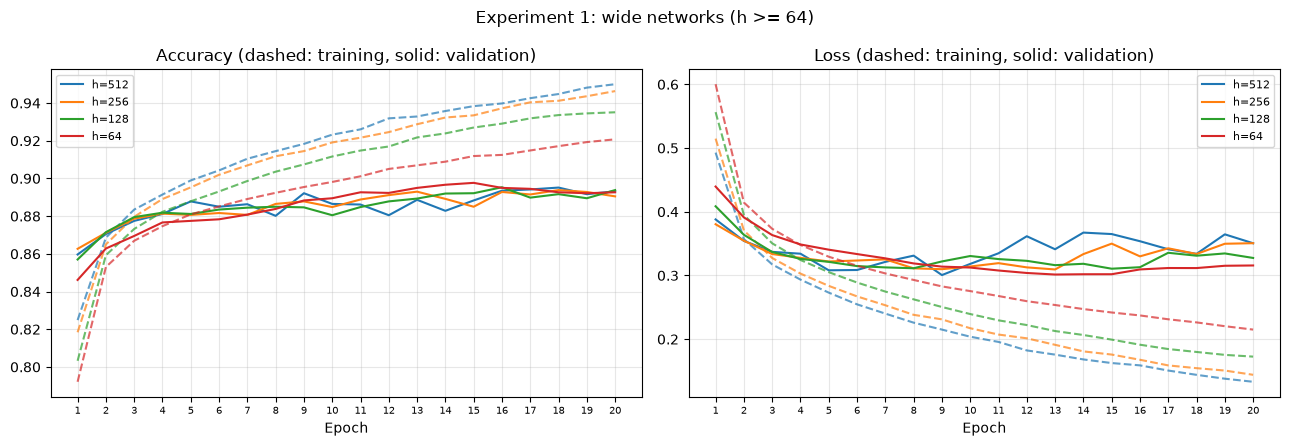

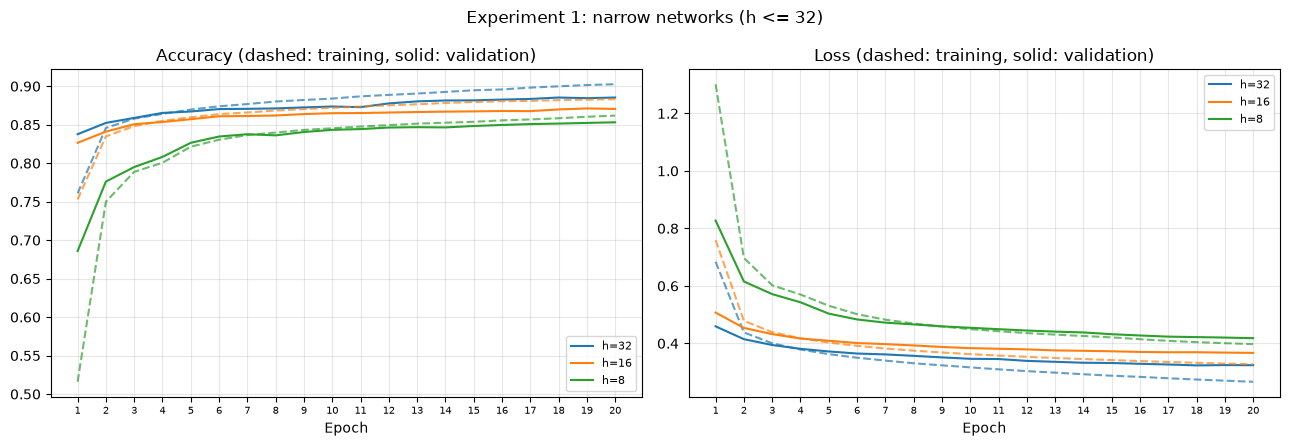

In [12]:
# Experiment 1: comparison table and training/validation curves (seed 42)
e1_table = show_e1(e1, e1_epoch_time)

As can be seen in the table and plots above, the smallest model that meets the accuracy requirements (with seed 42) is the one with 64 neurons in each hidden layer.

However, it is possible that seed 42 placed it at an advantageous starting point in weight space and that, therefore, this good result is due to chance. This is especially frequent in small models. Likewise, this can work against a model, and may have placed the starting point of the model with 32 neurons per layer in a bad location.

Therefore, to minimise this selection bias, we try seeds 7 and 126 starting from the first model that does not meet the requirements and moving upwards. If the mean of the three seeds meets the quality requirements, we take this model as valid; otherwise, we try the immediately larger model until we settle on the smallest one that meets them.

In [13]:
# Experiment 1: confirm the width with two extra seeds (7 and 126), from the seed-42 frontier upwards.
chosen_h, val_runs = confirm_e1(e1)
if chosen_h is None:
    print('WARNING: no width passes on the 3-seed mean in this environment; continuing with h = 64 (plan).')
    chosen_h = 64  # safe default = value of the plan, used only if nothing passes (keeps "Restart and run all" alive)

print(f"Threshold G + 0.003 = {threshold:.4f}")
print(f"Chosen width: h = {chosen_h} ({e1[chosen_h]['params']:,} parameters), mean = {np.mean(val_runs[chosen_h]):.4f}")
display(pd.DataFrame({'s42': [v[0] for v in val_runs.values()], 's7': [v[1] for v in val_runs.values()],
                      's126': [v[2] for v in val_runs.values()], 'mean': [np.mean(v) for v in val_runs.values()],
                      'passes': [passes(np.mean(v)) for v in val_runs.values()]},
                     index=pd.Index(list(val_runs), name='hidden units')).round(4))

E1-784-32x2-s7: 26,506 params, train 0.9029, val 0.8792, 0.83 s/epoch


E1-784-32x2-s126: 26,506 params, train 0.9045, val 0.8808, 0.83 s/epoch
h = 32: val s42/s7/s126 = [0.8853, 0.8792, 0.8808], mean = 0.8818, passes: False


E1-784-64x2-s7: 55,050 params, train 0.9251, val 0.8860, 1.11 s/epoch


E1-784-64x2-s126: 55,050 params, train 0.9234, val 0.8912, 1.13 s/epoch
h = 64: val s42/s7/s126 = [0.8927, 0.886, 0.8912], mean = 0.8899, passes: True
Threshold G + 0.003 = 0.8862
Chosen width: h = 64 (55,050 parameters), mean = 0.8899


,s42,s7,s126,mean,passes
hidden units,,,,,
32,0.8853,0.8792,0.8808,0.8818,False
64,0.8927,0.8860,0.8912,0.8899,True


In [14]:
# Experiment 1, whole experiment as one call (used to repeat E1 with another optimiser). This cell only DEFINES
# the function; E1 above was run with the default Adam 1e-3.
def run_e1(optimizer='adam', lr=1e-3, prefix=''):
    """Screen + table/curves + confirmation. Returns {'choice': width or None, 'runs': val accuracies of seeds
    42/7/126 per width tried, 'screen': e1 (seed-42 histories and parameters)}."""
    e1_, e1_time = screen_e1(optimizer, lr, prefix)
    show_e1(e1_, e1_time)
    choice, runs = confirm_e1(e1_, optimizer, lr, prefix)
    return {'choice': choice, 'runs': runs, 'screen': e1_}

### Conclusions of Experiment 1

As we reduce the width, the network goes from overfitting to underfitting. The train-validation gap decreases monotonically, from 0.0568 with h = 512 to 0.0086 with h = 8. Moreover, in the reference the final val loss (0.3506) is well above its minimum (0.3006): the network keeps fitting the training set while getting worse on validation, that is, it has spare capacity. At the other extreme, with h = 16 and h = 8 the minimum val loss coincides with the final one (0.3670 and 0.4182). They are still improving at epoch 20, so they are capacity-limited models (and perhaps also limited by the number of epochs). In bias-variance terms, wide networks have high variance and narrow ones have high bias.

| h | Parameters | Gap train−val | Final val (seed 42) |
|---|---|---|---|
| 512 | 669,706 | 0.0568 | 0.8932 |
| 64 | 55,050 | 0.0281 | 0.8927 |
| 32 | 26,506 | 0.0173 | 0.8853 |
| 8 | 6,442 | 0.0086 | 0.8532 |

Consequently, most of the reference capacity was surplus: h = 64 exceeds the threshold (0.8862) with 55,050 parameters, about 12.2 times fewer (669,706 / 55,050).

However, confirmation with three seeds was necessary. The "bad luck" hypothesis for h = 32 is discarded: with seeds 7 and 126 it comes out even lower (0.8792 and 0.8808), and its mean (0.8818) is about 0.44 pp below the threshold. In contrast, h = 64 is confirmed: its mean is 0.8899, about 0.38 pp above. Even so, seed 42 was the highest of the three, and seed 7 alone (0.8860) would fall just below the threshold. This illustrates the sensitivity to initialisation of small networks: with h = 64, the difference between the best and the worst seed is 0.0067. Therefore we decide using the mean and not a single run.

As limitations, we only use 3 seeds and 20 fixed epochs for all models, which may penalise the smallest ones. All decisions are made on validation; the test set is not used here.

Therefore, h = 64 is the width we keep for the final combination; the following experiments start again from the base network.

### Experiment 2: Input size reduction (E2a area averaging, E2b variance selection)

We vary one factor, the input size d, keeping the 512-512 ReLU network and the training configuration of the reference fixed. We compare two ways of compressing the 784 pixels: neighbour averaging (E2a) and keeping the highest-variance pixels (E2b). The question is how many input values the network needs and which compression preserves more information.

**Hypothesis**

In the base network, most of the parameters are in the first layer: 784·512 + 512 = 401,920 out of 669,706, that is, 60 %. Consequently, reducing the input size is a direct way to reduce the network. However, not all pixels contribute equally. Neighbouring pixels are highly correlated, so a large part of the input is redundant. Moreover, the border pixels are almost always empty and their variance is almost zero.

Therefore, we expect the validation accuracy to drop little for the first sizes and to fall faster for the smallest ones, because fewer inputs imply less information and less capacity. With the same parameters, we expect neighbour averaging to preserve more information than variance-based selection, especially at 7×7. Averaging acts as a filter that preserves the silhouette of the whole image, whereas selection keeps isolated pixels and discards the rest entirely. Likewise, we expect the train−val gap to shrink as the input decreases, since the network has less capacity to memorise.

Finally, there is a limit that does not depend on the results. With 512-512, the parameters cannot go below 268,298, because the 512×512 layer dominates as soon as the input is reduced. Consequently, the reduction that this factor allows is limited.

**Design**

Factor: the input size. Everything else is the same as in the base network (512-512 ReLU, Adam 1e-3, 20 epochs, batch 128). We compare two compressions. In E2a we use neighbour averaging (`area`) to go to 14×14, 10×10 and 7×7. In E2b we keep the 196, 100 or 49 pixels with the highest variance, computed only on the training images. The parameters are 512·d + 268,298: 368,650, 319,498 and 293,386. We choose the smallest size whose 3-seed mean meets final val ≥ G + 0.003.

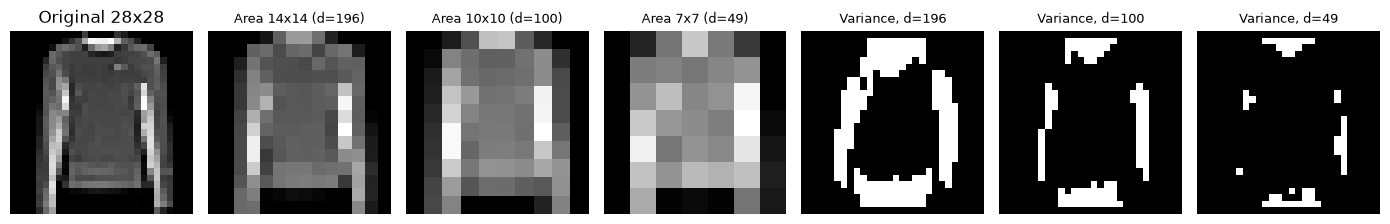

In [15]:
# Experiment 2, input preparation: two ways of compressing the 784 pixels into d values (train and validation only).
dims = [196, 100, 49]
side = {196: 14, 100: 10, 49: 7}  # d = side * side

# Variance of every pixel, computed on the training images ONLY (the validation set must not influence the selection)
pixel_var = flat(x_train).var(axis=0)
order = np.argsort(-pixel_var)                      # pixel indices, most variable first
keep = {d: np.sort(order[:d]) for d in dims}        # the d most variable pixels

def area(x, s):
    """Average of neighbouring pixels: (n, 28, 28) -> (n, s, s)."""
    return tf.image.resize(x[..., None], (s, s), method='area').numpy()

def e2_inputs(method, d):
    """(x_tr, x_va) flattened to d values. method: 'area' (neighbour average) or 'var' (highest-variance pixels)."""
    if d == 784:
        return flat(x_train), flat(x_val)
    if method == 'area':
        return flat(area(x_train, side[d])), flat(area(x_val, side[d]))
    return flat(x_train)[:, keep[d]], flat(x_val)[:, keep[d]]

# One training image, its area-reduced versions and the pixels kept by variance (white = kept)
fig, axes = plt.subplots(1, 7, figsize=(14, 2.4))
axes[0].imshow(x_train[0], cmap='gray')
axes[0].set_title('Original 28x28')
for ax, d in zip(axes[1:4], dims):
    ax.imshow(area(x_train[:1], side[d])[0, :, :, 0], cmap='gray')
    ax.set_title(f'Area {side[d]}x{side[d]} (d={d})', fontsize=9)
for ax, d in zip(axes[4:], dims):
    mask = np.zeros(784)
    mask[keep[d]] = 1
    ax.imshow(mask.reshape(28, 28), cmap='gray')
    ax.set_title(f'Variance, d={d}', fontsize=9)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [16]:
# Experiment 2, helpers shared by E2a (area) and E2b (variance): the network is always 512-512, only the input changes.
# optimizer, lr, prefix: as in E1 (Adam 1e-3 and prefix='' reproduce the original names and results).
HIDDEN = [512, 512]
TAG = {'area': 'a', 'var': 'b'}
expected = {196: 368650, 100: 319498, 49: 293386}  # 512*d + 268,298

def screen(method, optimizer='adam', lr=1e-3, prefix=''):
    """Seed-42 screen: train 512-512 for d = 196, 100, 49; d = 784 is the reference (not retrained with Adam)."""
    assert prefix or (optimizer, lr) == ('adam', 1e-3)  # a non-Adam model must never be recorded without a prefix
    hists = {784: full784(42, optimizer, lr, name=f'{prefix}E2-full784-512x2-s42')}
    for d in dims:
        x_tr, x_va = e2_inputs(method, d)
        _, hists[d], _ = train_candidate(f'{prefix}E2{TAG[method]}-{method}{d}-512x2-s42', x_tr, y_train, x_va, y_val,
                                         hidden_units=HIDDEN, seed=42, optimizer=optimizer, lr=lr)
        assert results[-1]['parameters'] == expected[d] == mlp_params(d, HIDDEN)  # parameter check
    rows = []
    for d in sorted(hists):
        tr, va = hists[d].history['accuracy'][-1], hists[d].history['val_accuracy'][-1]
        rows.append({'d': d, 'parameters': mlp_params(d, HIDDEN), 'train acc': tr, 'val acc': va,
                     'gap (train - val)': tr - va, 'val acc >= G + 0.003': passes(va)})
    display(pd.DataFrame(rows).set_index('d').round(4))
    ds_desc = sorted(hists, reverse=True)
    plot_train_val([hists[d] for d in ds_desc], [f'd={d}' for d in ds_desc], f'{prefix}E2{TAG[method]} ({method}), seed 42')
    return hists

def confirm(method, hists, optimizer='adam', lr=1e-3, prefix=''):
    """Same rule as E1: start at the largest failing d below the smallest passing d, go up, stop at the first d
    whose 3-seed mean (42, 7, 126) passes. Returns the chosen d (None if no d passes) and the runs of every d tried."""
    assert prefix or (optimizer, lr) == ('adam', 1e-3)
    val42 = {d: h.history['val_accuracy'][-1] for d, h in hists.items()}
    ds = sorted(val42)
    ok42 = [d for d in ds if passes(val42[d])]
    fail_below = [d for d in ds if ok42 and d < ok42[0]]
    start = max(fail_below) if fail_below else (ok42[0] if ok42 else ds[0])
    runs, choice = {}, None
    for d in [d for d in ds if d >= start]:
        vals = [val42[d]]  # seed 42 is already trained (d = 784: the reference)
        for seed in [7, 126]:
            if d == 784:
                # trained once per (optimiser, seed) and shared with E1 and with the other method
                hist = full784(seed, optimizer, lr, name=f'{prefix}E2-full784-512x2-s{seed}')
            else:
                x_tr, x_va = e2_inputs(method, d)
                _, hist, _ = train_candidate(f'{prefix}E2{TAG[method]}-{method}{d}-512x2-s{seed}', x_tr, y_train, x_va, y_val,
                                             hidden_units=HIDDEN, seed=seed, optimizer=optimizer, lr=lr)
            vals.append(hist.history['val_accuracy'][-1])
        runs[d] = vals
        print(f"d = {d}: val s42/s7/s126 = {[round(v, 4) for v in vals]}, mean = {np.mean(vals):.4f}, passes: {passes(np.mean(vals))}")
        if passes(np.mean(vals)):
            choice = d
            break
    display(pd.DataFrame({'s42': [v[0] for v in runs.values()], 's7': [v[1] for v in runs.values()],
                          's126': [v[2] for v in runs.values()], 'mean': [np.mean(v) for v in runs.values()],
                          'passes': [passes(np.mean(v)) for v in runs.values()]},
                         index=pd.Index(list(runs), name='d')).round(4))
    return choice, runs

def show_e2(e2a_choice, e2a_runs, e2a_hists, e2b_choice, e2b_runs, e2b_hists):
    """Summary of E2: choice of each method and validation accuracy (seed 42) against parameters."""
    display(pd.DataFrame({'method': ['area', 'variance'], 'd': [e2a_choice, e2b_choice],
                          'parameters': [mlp_params(e2a_choice, HIDDEN), mlp_params(e2b_choice, HIDDEN)],
                          'mean val acc (3 seeds)': [np.mean(e2a_runs[e2a_choice]), np.mean(e2b_runs[e2b_choice])]}).round(4))

    plt.figure(figsize=(7, 4.5))
    for hists, label in [(e2a_hists, 'E2a area'), (e2b_hists, 'E2b variance')]:
        ds_asc = sorted(hists)
        plt.plot([mlp_params(d, HIDDEN) for d in ds_asc], [hists[d].history['val_accuracy'][-1] for d in ds_asc],
                 'o-', label=label)
    plt.plot(mlp_params(784, HIDDEN), e2a_hists[784].history['val_accuracy'][-1], 'k*', markersize=12, label='Reference (d=784)')
    plt.axhline(threshold, color='r', linestyle='--', label=f'Threshold G + 0.003 = {threshold:.4f}')
    plt.xscale('log')
    plt.xlabel('Parameters (log scale)')
    plt.ylabel('Final validation accuracy (seed 42)')
    plt.title('Experiment 2: input size')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

E2a-area196-512x2-s42: 368,650 params, train 0.9403, val 0.8947, 3.04 s/epoch


E2a-area100-512x2-s42: 319,498 params, train 0.9238, val 0.8867, 3.20 s/epoch


E2a-area49-512x2-s42: 293,386 params, train 0.9064, val 0.8837, 3.39 s/epoch


,parameters,train acc,val acc,gap (train - val),val acc >= G + 0.003
d,,,,,
49,293386,0.9064,0.8837,0.0228,False
100,319498,0.9238,0.8867,0.0371,True
196,368650,0.9403,0.8947,0.0456,True
784,669706,0.9500,0.8932,0.0568,True


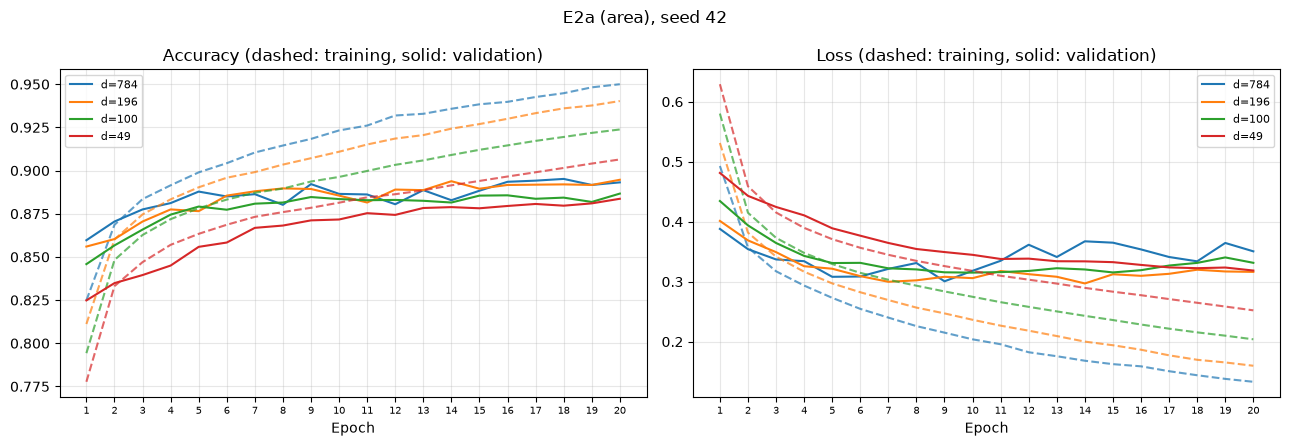

In [17]:
# Experiment 2a (area): seed-42 screen of 512-512 with d = 196, 100, 49 (d = 784: the reference).
e2a_hists = screen('area')

In [18]:
# Experiment 2a (area): confirm with seeds 7 and 126, from the seed-42 frontier upwards.
e2a_choice, e2a_runs = confirm('area', e2a_hists)
if e2a_choice is None:
    print('WARNING: no d passes on the 3-seed mean; falling back to d = 784.')
    e2a_choice = 784  # safe default: the reference input, used only if nothing passes
print(f"Threshold G + 0.003 = {threshold:.4f}")
print(f"E2a choice: d = {e2a_choice} ({mlp_params(e2a_choice, HIDDEN):,} parameters), mean = {np.mean(e2a_runs[e2a_choice]):.4f}")

E2a-area49-512x2-s7: 293,386 params, train 0.9045, val 0.8812, 2.65 s/epoch


E2a-area49-512x2-s126: 293,386 params, train 0.9042, val 0.8783, 2.52 s/epoch
d = 49: val s42/s7/s126 = [0.8837, 0.8812, 0.8783], mean = 0.8811, passes: False


E2a-area100-512x2-s7: 319,498 params, train 0.9241, val 0.8860, 2.41 s/epoch


E2a-area100-512x2-s126: 319,498 params, train 0.9231, val 0.8827, 2.71 s/epoch
d = 100: val s42/s7/s126 = [0.8867, 0.886, 0.8827], mean = 0.8851, passes: False


E2a-area196-512x2-s7: 368,650 params, train 0.9416, val 0.8920, 2.97 s/epoch


E2a-area196-512x2-s126: 368,650 params, train 0.9403, val 0.8958, 2.74 s/epoch
d = 196: val s42/s7/s126 = [0.8947, 0.892, 0.8958], mean = 0.8942, passes: True


,s42,s7,s126,mean,passes
d,,,,,
49,0.8837,0.8812,0.8783,0.8811,False
100,0.8867,0.8860,0.8827,0.8851,False
196,0.8947,0.8920,0.8958,0.8942,True


Threshold G + 0.003 = 0.8862
E2a choice: d = 196 (368,650 parameters), mean = 0.8942


E2b-var196-512x2-s42: 368,650 params, train 0.9245, val 0.8495, 3.01 s/epoch


E2b-var100-512x2-s42: 319,498 params, train 0.9005, val 0.8235, 3.31 s/epoch


E2b-var49-512x2-s42: 293,386 params, train 0.8564, val 0.7903, 2.65 s/epoch


,parameters,train acc,val acc,gap (train - val),val acc >= G + 0.003
d,,,,,
49,293386,0.8564,0.7903,0.0661,False
100,319498,0.9005,0.8235,0.0770,False
196,368650,0.9245,0.8495,0.0750,False
784,669706,0.9500,0.8932,0.0568,True


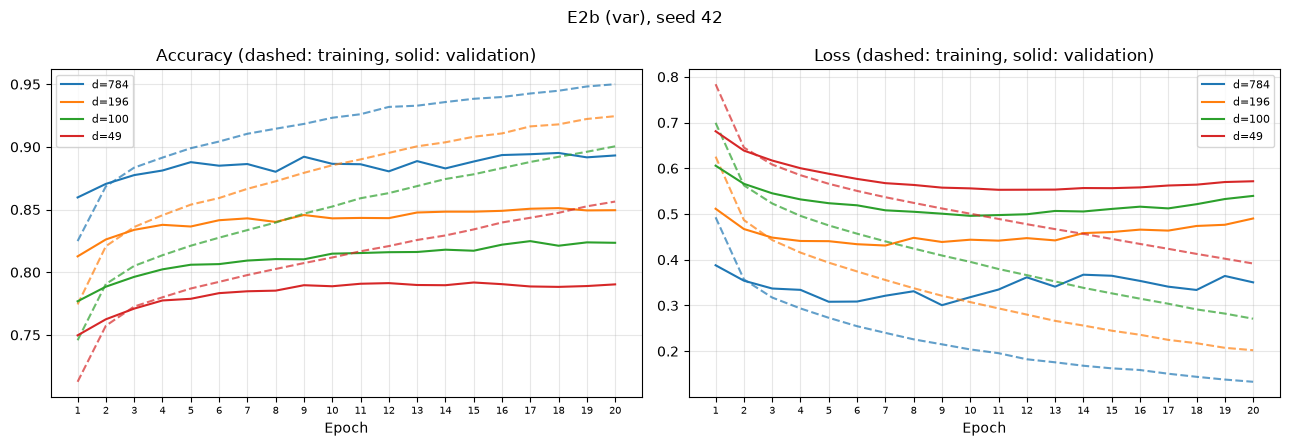

In [19]:
# Experiment 2b (variance): seed-42 screen of 512-512 with the d highest-variance pixels (d = 784: the reference).
e2b_hists = screen('var')

In [20]:
# Experiment 2b (variance): confirm with seeds 7 and 126, from the seed-42 frontier upwards.
# If it reaches d = 784, the 784 models already trained (cache FULL784) are reused, not retrained.
e2b_choice, e2b_runs = confirm('var', e2b_hists)
if e2b_choice is None:
    print('WARNING: no d passes on the 3-seed mean; falling back to d = 784.')
    e2b_choice = 784  # safe default: the reference input, used only if nothing passes
print(f"Threshold G + 0.003 = {threshold:.4f}")
print(f"E2b choice: d = {e2b_choice} ({mlp_params(e2b_choice, HIDDEN):,} parameters), mean = {np.mean(e2b_runs[e2b_choice]):.4f}")

E2b-var196-512x2-s7: 368,650 params, train 0.9249, val 0.8528, 3.17 s/epoch


E2b-var196-512x2-s126: 368,650 params, train 0.9241, val 0.8567, 2.98 s/epoch
d = 196: val s42/s7/s126 = [0.8495, 0.8528, 0.8567], mean = 0.8530, passes: False


E2-full784-512x2-s7: 669,706 params, train 0.9497, val 0.8912, 4.58 s/epoch


E2-full784-512x2-s126: 669,706 params, train 0.9514, val 0.8950, 4.59 s/epoch
d = 784: val s42/s7/s126 = [0.8932, 0.8912, 0.895], mean = 0.8931, passes: True


,s42,s7,s126,mean,passes
d,,,,,
196,0.8495,0.8528,0.8567,0.8530,False
784,0.8932,0.8912,0.8950,0.8931,True


Threshold G + 0.003 = 0.8862
E2b choice: d = 784 (669,706 parameters), mean = 0.8931


,method,d,parameters,mean val acc (3 seeds)
0,area,196,368650,0.8942
1,variance,784,669706,0.8931


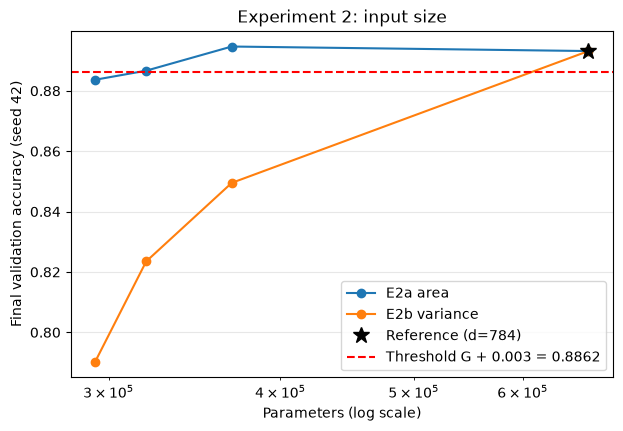

In [21]:
# Experiment 2, summary: choice of each method and validation accuracy (seed 42) against parameters.
show_e2(e2a_choice, e2a_runs, e2a_hists, e2b_choice, e2b_runs, e2b_hists)

In [22]:
# Experiment 2, whole experiment as one call (used to repeat E2 with another optimiser). This cell only DEFINES
# the function; E2 above was run with the default Adam 1e-3.
def run_e2(optimizer='adam', lr=1e-3, prefix='', methods=('area', 'var')):
    """Screen + confirmation of each input-reduction method. Returns {method: (choice or None, runs, hists)}."""
    out = {}
    for method in methods:
        hists = screen(method, optimizer, lr, prefix)
        choice, runs = confirm(method, hists, optimizer, lr, prefix)
        out[method] = (choice, runs, hists)
    return out

### Conclusions of Experiment 2

We number the predictions of the hypothesis in the order in which they appear: (1) validation drops little with the first sizes and falls faster with the smallest ones; (2) with the same parameters, averaging preserves more information than variance-based selection; (3) the train−val gap shrinks as the input decreases; and (4) with 512-512, the parameters cannot go below 268,298. As can be seen, the first part of prediction (1) holds: going from 784 to 196 inputs with neighbour averaging we lose nothing. The three-seed mean is 0.8942, versus 0.8932 for the reference with seed 42. However, the second part is refuted. The largest drop occurs between 196 and 100 (0.91 pp on average) and not between 100 and 49 (0.40 pp), although in both steps the input is reduced by roughly half.

| d | Parameters | Averaging: mean val | Variance: val s42 | Gap averaging / variance (s42) |
|---|---|---|---|---|
| 784 | 669,706 | 0.8931 | 0.8932 | 0.0568 / 0.0568 |
| 196 | 368,650 | 0.8942 | 0.8495 (mean 0.8530) | 0.0456 / 0.0750 |
| 100 | 319,498 | 0.8851 | 0.8235 | 0.0371 / 0.0770 |
| 49 | 293,386 | 0.8811 | 0.7903 | 0.0228 / 0.0661 |

Prediction (2) is clearly confirmed. With the same parameters, variance-based selection loses 4.12 pp at d = 196 (three-seed mean) and 9.34 pp at d = 49 (seed 42). The figure with the masks helps us understand why: the highest-variance pixels are on the outline (sleeves, neckline, bottom edge), whose value depends on the shape and position of each garment, whereas the interior, where the texture that distinguishes similar garments lies, varies little and is discarded. Consequently, a high variance does not equate to information that is useful for the class. Averaging, in contrast, acts as a low-pass filter that summarises the whole image.

Likewise, prediction (3) is confirmed for averaging: the gap decreases monotonically (0.0568, 0.0456, 0.0371, 0.0228), since fewer inputs mean less capacity and, with it, less overfitting. However, it is refuted for variance, whose gap (0.0661–0.0770) exceeds that of the reference. A plausible explanation is that the network memorises outline patterns that do not generalise. In that case, the problem would be the information lost and not the capacity.

The averaging case d = 100 passes the screening with seed 42 (0.8867), but fails with the three-seed mean (0.8851). Therefore, the three-seed protocol is once again necessary, this time in the opposite direction to E1.

Finally, limit (4) is confirmed. The best reduction is 368,650 parameters, 45.0 % fewer than the reference (about 1.82 times), far from the 12.2 times of E1. As soon as the input is reduced, the 512×512 layer dominates the count, so reducing only the input is not enough. We keep 14×14 with averaging for the final combination. We expect that, with a narrow network like that of E1, the first layer will weigh heavily again and reducing the input will have more impact there. The limitations of this experiment are that we use only three seeds, 20 fixed epochs and the validation set, and that variance is only one of the possible selection criteria.

### Experiment 3: Width at reduced input (196)

We vary one factor, the width of the two hidden layers, with the input fixed at 14x14 (d = 196, area averaging) and the rest of the configuration fixed. The question is whether the savings of narrowing (E1) and of reducing the input (E2) combine.

**Hypothesis**

We propose that, once the network has been narrowed, reducing the input is again a main lever. In E2 the saving was limited because with 512-512 the middle layer dominated. However, with 784-64-64 the first layer has 50,240 of the 55,050 parameters, 91 %. Consequently, with 196-64-64 that layer drops to 12,608 and the model ends up with 17,418 parameters.

On the other hand, we do not expect the savings of E1 and E2 to simply add up. We measured them separately on the base network, and the two factors may interact. Averaging to 14×14 preserves almost all the useful information when the network has ample capacity. However, with a narrow network that loss may no longer be compensated. Therefore we predict that h = 64 will not be enough and that the smallest valid h will be above 64.

Likewise, since there are fewer inputs and therefore less capacity, we expect the train−val gap to be smaller than that of 784-64-64 with the same h. This would indicate that the network is approaching underfitting rather than overfitting. If any h ≤ 144 meets the criterion, the combination improves on E1. If none does, we will conclude that with low widths what limits the network is the input information and not the capacity, and we will keep 784-64-64.

**Design**

The factor we vary is the width h of the two hidden layers, with the input fixed at 14×14 by averaging (d = 196). We try h ∈ {64, 80, 96, 112, 128, 144}, with 17,418 / 23,050 / 29,194 / 35,850 / 43,018 / 50,698 parameters. The network is 196-h-h-10 with ReLU, with the rest of the configuration the same as in the reference. We do the screening with seed 42 and the confirmation with 7 and 126 starting from the first size that fails and moving upwards. We choose the smallest h whose 3-seed validation mean is ≥ G + 0.003 = 0.8862.

In [23]:
# Experiment 3, helpers: screen + confirmation at a reduced input d, wrapped in functions (optimizer, lr, prefix)
# so that E3 can be repeated with another optimiser. Adam 1e-3 and prefix='' reproduce the original run.
def screen_e3(d, widths, optimizer='adam', lr=1e-3, prefix='', method='area'):
    """Seed-42 screen of the two-hidden-layer width at input size d. Returns {width: history}."""
    assert prefix or (optimizer, lr) == ('adam', 1e-3)  # a non-Adam model must never be recorded without a prefix
    x_tr, x_va = e2_inputs(method, d)  # same input as E2 (built from train only)
    hists = {}
    for h in widths:
        _, hists[h], _ = train_candidate(f'{prefix}E3-{method}{d}-{h}x2-s42', x_tr, y_train, x_va, y_val,
                                         hidden_units=[h, h], seed=42, optimizer=optimizer, lr=lr)
        assert results[-1]['parameters'] == mlp_params(d, [h, h])  # parameter check
    return hists

def show_e3(hists, d, widths, method='area', prefix=''):
    """Table and training/validation curves of the seed-42 screen."""
    rows = []
    for h in widths:
        tr, va = hists[h].history['accuracy'][-1], hists[h].history['val_accuracy'][-1]
        rows.append({'h': h, 'parameters': mlp_params(d, [h, h]), 'train acc': tr, 'val acc': va,
                     'gap (train - val)': tr - va, 'val acc >= G + 0.003': passes(va)})
    display(pd.DataFrame(rows).set_index('h').round(4))
    plot_train_val([hists[h] for h in widths], [f'h={h}' for h in widths], f'{prefix}E3 ({method} {d}), seed 42')

def confirm_e3(hists, d, widths, optimizer='adam', lr=1e-3, prefix='', method='area'):
    """Same rule as E1 and E2, with seeds 7 and 126, from the seed-42 frontier upwards.
    Returns (choice, runs); choice is None if no width passes on the 3-seed mean."""
    assert prefix or (optimizer, lr) == ('adam', 1e-3)
    x_tr, x_va = e2_inputs(method, d)
    val42 = {h: hists[h].history['val_accuracy'][-1] for h in widths}
    widths_asc = sorted(val42)
    ok42 = [h for h in widths_asc if passes(val42[h])]
    fail_below = [h for h in widths_asc if ok42 and h < ok42[0]]  # widths that fail below the smallest passing one
    start = max(fail_below) if fail_below else (ok42[0] if ok42 else widths_asc[0])

    runs = {}      # width -> final val accuracy for seeds 42, 7, 126
    choice = None  # stays None if no width passes
    for h in [w for w in widths_asc if w >= start]:
        vals = [val42[h]]  # seed 42 is already trained
        for seed in [7, 126]:
            _, hist, _ = train_candidate(f'{prefix}E3-{method}{d}-{h}x2-s{seed}', x_tr, y_train, x_va, y_val,
                                         hidden_units=[h, h], seed=seed, optimizer=optimizer, lr=lr)
            vals.append(hist.history['val_accuracy'][-1])
        runs[h] = vals
        print(f"h = {h}: val s42/s7/s126 = {[round(v, 4) for v in vals]}, mean = {np.mean(vals):.4f}, passes: {passes(np.mean(vals))}")
        if passes(np.mean(vals)):
            choice = h  # first (smallest) width whose 3-seed mean passes
            break
    return choice, runs

E3-area196-64x2-s42: 17,418 params, train 0.8952, val 0.8890, 0.76 s/epoch


E3-area196-80x2-s42: 23,050 params, train 0.9018, val 0.8932, 0.76 s/epoch


E3-area196-96x2-s42: 29,194 params, train 0.9054, val 0.8967, 0.81 s/epoch


E3-area196-112x2-s42: 35,850 params, train 0.9094, val 0.8865, 0.87 s/epoch


E3-area196-128x2-s42: 43,018 params, train 0.9137, val 0.8958, 0.85 s/epoch


E3-area196-144x2-s42: 50,698 params, train 0.9146, val 0.8902, 0.89 s/epoch


,parameters,train acc,val acc,gap (train - val),val acc >= G + 0.003
h,,,,,
64,17418,0.8952,0.8890,0.0062,True
80,23050,0.9018,0.8932,0.0086,True
96,29194,0.9054,0.8967,0.0088,True
112,35850,0.9094,0.8865,0.0229,True
128,43018,0.9137,0.8958,0.0178,True
144,50698,0.9146,0.8902,0.0244,True


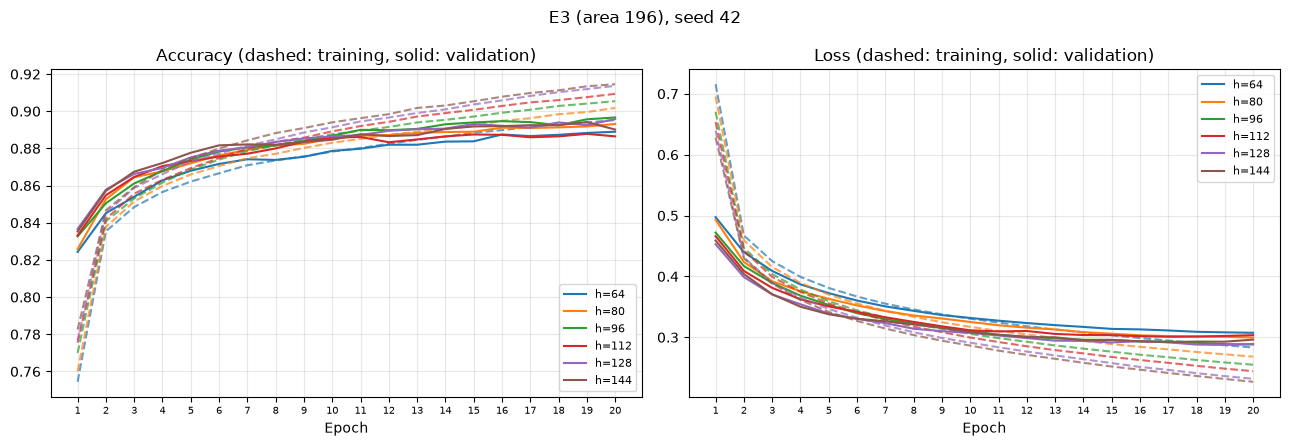

In [24]:
# Experiment 3, screen: width of the two hidden layers at the reduced input (d = 196, area 14x14), seed 42.
# Everything else as in E1/E2: 2 ReLU layers, Adam 1e-3, 20 epochs, batch 128.
E3_WIDTHS = [64, 80, 96, 112, 128, 144]
E3_D = 196

e3_hists = screen_e3(E3_D, E3_WIDTHS)
show_e3(e3_hists, E3_D, E3_WIDTHS)

In [25]:
# Experiment 3, confirm: same rule as E1 and E2, with seeds 7 and 126, from the seed-42 frontier upwards.
e3_choice, e3_runs = confirm_e3(e3_hists, E3_D, E3_WIDTHS)

print(f"Threshold G + 0.003 = {threshold:.4f}")
if e3_choice is None:
    print('WARNING: no width passes on the 3-seed mean in this environment; continuing with h = 64 (plan).')
    e3_choice = 64  # safe default = value of the plan, used only if nothing passes (keeps "Restart and run all" alive)
else:
    print(f"E3 choice: h = {e3_choice} ({mlp_params(E3_D, [e3_choice] * 2):,} parameters), mean = {np.mean(e3_runs[e3_choice]):.4f}")
display(pd.DataFrame({'s42': [v[0] for v in e3_runs.values()], 's7': [v[1] for v in e3_runs.values()],
                      's126': [v[2] for v in e3_runs.values()], 'mean': [np.mean(v) for v in e3_runs.values()],
                      'passes': [passes(np.mean(v)) for v in e3_runs.values()]},
                     index=pd.Index(list(e3_runs), name='hidden units')).round(4))

E3-area196-64x2-s7: 17,418 params, train 0.8954, val 0.8863, 0.78 s/epoch


E3-area196-64x2-s126: 17,418 params, train 0.8968, val 0.8865, 0.78 s/epoch
h = 64: val s42/s7/s126 = [0.889, 0.8863, 0.8865], mean = 0.8873, passes: True
Threshold G + 0.003 = 0.8862
E3 choice: h = 64 (17,418 parameters), mean = 0.8873


,s42,s7,s126,mean,passes
hidden units,,,,,
64,0.889,0.8863,0.8865,0.8873,True


,d,parameters,mean val acc (3 seeds)
model,,,
E1: 784-64-64,784,55050,0.8899
E3: 196-64-64,196,17418,0.8873
E2a: 196-512-512,196,368650,0.8942


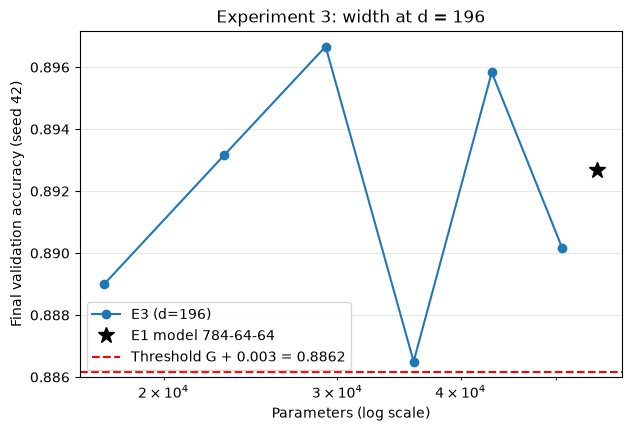

In [26]:
# Experiment 3, summary: E3 choice against the E1 model and the E2a choice (3-seed mean of validation accuracy).
e1_params = mlp_params(784, [chosen_h, chosen_h])
e2a_params = mlp_params(e2a_choice, HIDDEN)
rows = [{'model': f'E1: 784-{chosen_h}-{chosen_h}', 'd': 784, 'parameters': e1_params,
         'mean val acc (3 seeds)': np.mean(val_runs[chosen_h])},
        {'model': f'E2a: {e2a_choice}-512-512', 'd': e2a_choice, 'parameters': e2a_params,
         'mean val acc (3 seeds)': np.mean(e2a_runs[e2a_choice])}]
if e3_choice is not None:
    rows.insert(1, {'model': f'E3: {E3_D}-{e3_choice}-{e3_choice}', 'd': E3_D,
                    'parameters': mlp_params(E3_D, [e3_choice] * 2),
                    'mean val acc (3 seeds)': np.mean(e3_runs[e3_choice])})
else:
    print('E3 has no choice (no width passed): the table only shows E1 and E2a.')
display(pd.DataFrame(rows).set_index('model').round(4))

plt.figure(figsize=(7, 4.5))
plt.plot([mlp_params(E3_D, [h, h]) for h in E3_WIDTHS], [e3_hists[h].history['val_accuracy'][-1] for h in E3_WIDTHS],
         'o-', label='E3 (d=196)')
plt.plot(e1_params, val_runs[chosen_h][0], 'k*', markersize=12, label=f'E1 model 784-{chosen_h}-{chosen_h}')
plt.axhline(threshold, color='r', linestyle='--', label=f'Threshold G + 0.003 = {threshold:.4f}')
plt.xscale('log')
plt.xlabel('Parameters (log scale)')
plt.ylabel('Final validation accuracy (seed 42)')
plt.title('Experiment 3: width at d = 196')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [27]:
# Experiment 3, whole experiment as one call (used to repeat E3 with another optimiser). This cell only DEFINES
# the function; E3 above was run with the default Adam 1e-3.
def run_e3(d, widths, optimizer='adam', lr=1e-3, prefix=''):
    """Screen + table/curves + confirmation. Returns {'hists': seed-42 histories, 'choice': width or None,
    'runs': val accuracies of seeds 42/7/126 per width tried}."""
    hists = screen_e3(d, widths, optimizer, lr, prefix)
    show_e3(hists, d, widths, prefix=prefix)
    choice, runs = confirm_e3(hists, d, widths, optimizer, lr, prefix)
    return {'hists': hists, 'choice': choice, 'runs': runs}

### Conclusions of Experiment 3

As can be seen, the first prediction is refuted: with the input reduced to 14×14, h = 64 is enough. Seeds 42, 7 and 126 give 0.8890, 0.8863 and 0.8865, with a mean of 0.8873, above the threshold of 0.8862. Therefore, the information lost by averaging neighbours turns out to be of little relevance even for a narrow network: the 784-pixel input was redundant and the savings of E1 and E2 combine. However, the margin is small (0.0011). Seeds 7 and 126 are almost at the threshold, and the mean is 0.26 percentage points lower than that of 784-64-64 (0.8899). This is an accuracy cost, although it fits within the criterion.

| Model | Parameters | Val mean (3 seeds) | Gap train−val |
|---|---|---|---|
| Reference 784-512-512 | 669,706 | 0.8932 (1 run) | 0.0568 |
| E1: 784-64-64 | 55,050 | 0.8899 | 0.0281 (s42) |
| E3: 196-64-64 | 17,418 | 0.8873 | 0.0062 (s42) |

The second prediction is confirmed. With h = 64, the gap drops from 0.0281 to 0.0062. When the input is reduced, the first layer goes from 50,240 to 12,608 parameters, the capacity decreases and with it the overfitting. With train at 0.8952, very close to validation, the network is close to its capacity limit, that is, close to underfitting. Likewise, within E3 the gap tends to grow with h, as expected when adding capacity: it goes from 0.0062 to 0.0244, although not monotonically (0.0229 with h = 112 versus 0.0178 with h = 128).

Regarding the third, the combination improves on E1: 17,418 parameters versus 55,050, about 3.16 times fewer, and about 38.4 times fewer than the reference. It is the smallest network so far that meets the criterion on validation.

On the other hand, more width does not clearly improve validation. The six curves are grouped between 0.886 and 0.897 and cross each other, and, in the curves, the val loss seems to flatten at the end of training. The single-seed values between h = 80 and 144 (0.8865–0.8967) do not follow a clear order. Therefore we attribute this to the noise of a single seed and do not interpret it.

Finally, we did not try h < 64 with the 14×14 input, so we do not know whether a smaller network would also meet the criterion. Moreover, the margin is narrow, we use only 3 seeds and 20 fixed epochs, and everything has been decided on validation. Consequently, 196-64-64 is our current candidate. In E3b, E4 and E4b we will study whether another architecture allows reducing it further, and in E5, whether an improvement in training (optimiser and regularisation) achieves it.

### Experiment 3b: Narrower second layer

We vary one factor, the width of the second hidden layer (64 to 32), keeping two hidden layers, the 196-value input and the rest of the configuration of E3 fixed. The question is whether the second layer can be narrowed without losing the validation threshold.

**Hypothesis**

We start from the combined model of E3 (input 196), 196-64-64, which meets the threshold with 17,418 parameters. Our idea is that, for the same budget, the number of layers matters more than the number of neurons, because each layer composes a new non-linear transformation on the features of the previous one. Consequently, if we keep the two hidden layers and only narrow the second one, we expect the network to lose barely any validation accuracy and to still meet the threshold or be very close. However, the saving will be small, because the first layer concentrates most of the parameters. If the drop with respect to the E3 mean (0.8873) clearly exceeds the variation between seeds, the hypothesis is refuted: the second layer would need its width.

**Design**

Factor: width of the second hidden layer (64 → 32); the rest fixed as in E3. The network is 196-64-32-10, with 12,608 + 2,080 + 330 = 15,018 parameters, versus 17,418 for E3 (14 % fewer). The first layer (12,608) is still 84 % of the total. Therefore, we train with seeds 42, 7 and 126, and the network passes if the validation mean is ≥ 0.8862.

E3b-area196-64-32-s42: 15,018 params, train 0.8896, val 0.8845, 0.72 s/epoch


E3b-area196-64-32-s7: 15,018 params, train 0.8926, val 0.8810, 0.77 s/epoch


E3b-area196-64-32-s126: 15,018 params, train 0.8920, val 0.8847, 0.77 s/epoch


,parameters,s42,s7,s126,mean,mean >= G + 0.003
E3: 196-64-64,17418,0.8890,0.8863,0.8865,0.8873,True
E3b: 196-64-32,15018,0.8845,0.8810,0.8847,0.8834,False


Threshold G + 0.003 = 0.8862; E3b mean = 0.8834, passes: False


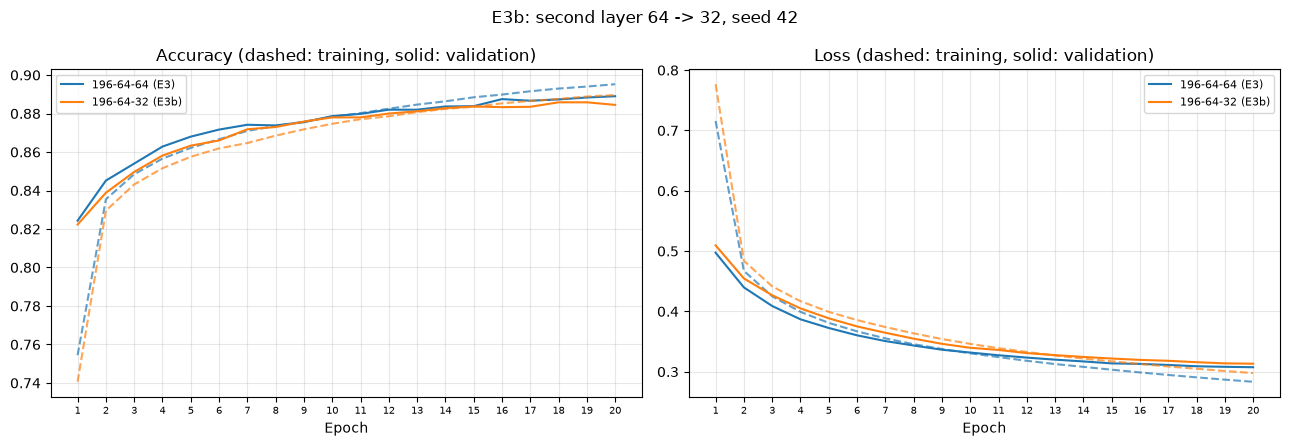

In [28]:
# Experiment 3b: width of the second hidden layer (same depth) at the reduced input (d = 196, area 14x14). Same as E3 except that the second hidden layer
# is halved (64 -> 32): 196-64-32-10. Seeds 42, 7 and 126, Adam 1e-3, 20 epochs, batch 128.
# Wrapped in a function (optimizer, lr, prefix) so that E5 can repeat it with another optimiser.
def run_e3b(optimizer='adam', lr=1e-3, prefix=''):
    """Train 196-64-32 with 3 seeds, compare with E3 (196-64-64). Returns {'runs': val acc of s42/s7/s126, 'passes': bool}."""
    assert prefix or (optimizer, lr) == ('adam', 1e-3)  # a non-Adam model must never be recorded without a prefix
    x_tr, x_va = e2_inputs('area', 196)  # same input as E3 (built from train only)
    hists, runs = {}, []
    for seed in [42, 7, 126]:
        model, hists[seed], _ = train_candidate(f'{prefix}E3b-area196-64-32-s{seed}', x_tr, y_train, x_va, y_val,
                                                hidden_units=[64, 32], seed=seed, optimizer=optimizer, lr=lr)
        assert model.count_params() == 15018 == mlp_params(196, [64, 32])  # matches the plan
        runs.append(hists[seed].history['val_accuracy'][-1])
    mean = np.mean(runs)

    # Table: E3b against E3 (196-64-64) with the 3-seed validation accuracies
    e3_vals = e3_runs[e3_choice]
    display(pd.DataFrame(
        {'parameters': [mlp_params(196, [e3_choice] * 2), 15018],
         's42': [e3_vals[0], runs[0]], 's7': [e3_vals[1], runs[1]], 's126': [e3_vals[2], runs[2]],
         'mean': [np.mean(e3_vals), mean], 'mean >= G + 0.003': [passes(np.mean(e3_vals)), passes(mean)]},
        index=[f'E3: 196-{e3_choice}-{e3_choice}', 'E3b: 196-64-32']).round(4))
    print(f"Threshold G + 0.003 = {threshold:.4f}; E3b mean = {mean:.4f}, passes: {passes(mean)}")

    # Curves, seed 42: the halved second layer against E3
    plot_train_val([e3_hists[e3_choice], hists[42]], [f'196-{e3_choice}-{e3_choice} (E3)', '196-64-32 (E3b)'],
                   f'{prefix}E3b: second layer 64 -> 32, seed 42')
    return {'runs': runs, 'passes': bool(passes(mean))}

e3b = run_e3b()
e3b_runs, e3b_passes = e3b['runs'], e3b['passes']

### Conclusions of Experiment 3b

**Scope.** The hypothesis speaks of "for the same budget, layers versus neurons", but the design does not compare depths at the same budget: it keeps the two layers and only narrows the second one (from 17,418 to 15,018 parameters). Therefore, what we really test is whether the second layer needs its 64 neurons, and we formulate the verdict on that specific prediction (losing barely any accuracy and meeting the threshold or being very close), not on the general idea of layers versus neurons, which we test in E4 and E4b.

As can be seen, the results obtained do not allow us to determine whether the observed difference is due to seed-to-seed noise, which would keep the hypothesis, or to a real loss, which would refute it. By narrowing the second layer from 64 to 32 neurons we save only 2,400 parameters (from 17,418 to 15,018, 14 % fewer), and the validation mean drops from 0.8873 to 0.8834, that is, 0.39 pp. The network ends up 0.28 pp below the threshold (0.8862), so it does not meet the criterion.

Can this drop be seed-to-seed noise? The range of E3 is 0.0027 and that of E3b is 0.0037, so the difference of means (0.0039) is of the same order or somewhat larger. On its own, this comparison does not "clearly" exceed the variation between seeds, which is the refutation criterion of the hypothesis. Likewise, as a descriptive fact, the drop is repeated in all three seeds: 0.8845 versus 0.8890 (s42), 0.8810 versus 0.8863 (s7) and 0.8847 versus 0.8865 (s126). Even the best seed of E3b falls below the worst of E3. However, this was not the refutation criterion that we registered, and with only three seeds per network we cannot separate a real loss from noise. Therefore, the result is inconclusive.

Moreover, with seed 42 we see no signs of overfitting: train also drops, from 0.8952 to 0.8896, and the gap remains small (0.0051 versus 0.0062). If the drop were real, a plausible explanation would be underfitting: the network loses capacity and learns worse even the training data. However, we only see this with one seed, so we cannot state that the second layer needs its 64 neurons. Since the first layer concentrates 84 % of the parameters, trimming the second one saves little, and, if the network is already close to its capacity limit, any trimming may be paid for in accuracy. We keep 196-64-64 as the best model, since 196-64-32 does not meet the threshold.

### Experiment 4: One hidden layer

We vary one factor, the number of hidden layers (two to one), with the 196-value input and the rest of the configuration of E3 fixed. The question is whether, at a similar parameter budget, a single wider layer can replace two narrow ones.

**Hypothesis**

We start from the combined model of E3 (input 196) and go from two hidden layers to one. Our hypothesis is that, with the same parameter budget, depth matters more than width. A single hidden layer with ReLU is already non-linear and, by the universal approximation theorem, with enough neurons it can approximate any continuous function. However, those neurons may be many. Depth, in contrast, composes non-linearities: each layer builds features on top of those of the previous one (hierarchical representation), and thus certain functions are represented with far fewer neurons than with a single wide layer.

Consequently, we expect 196-84-10 to perform worse on validation than 196-64-64 at the same budget, and that no one-layer network with fewer than 17,418 parameters will meet the threshold. The hypothesis is refuted if h = 84 matches or exceeds the E3 mean, or if any one-layer network smaller than E3 meets the threshold.

**Design**

Factor: number of hidden layers (2 → 1); the rest fixed as in E3. The network is 196-h-10, with h ∈ {32, 48, 64, 84, 96, 128} and 207·h + 10 parameters: 6,634 / 9,946 / 13,258 / 17,398 / 19,882 / 26,506. h = 84 matches E3 (17,398 versus 17,418) and is the fair comparison between one and two layers. Likewise, 96 and 128 have more parameters than E3 and only show the trend.

Criterion: screening with seed 42 and confirmation with seeds 7 and 126 starting from the first size that fails and moving upwards; we choose the smallest with a 3-seed mean ≥ 0.8862. h = 84 is always trained with the three seeds to compare it with the E3 mean (0.8873).

In [29]:
# Experiment 4, helpers: ONE hidden layer 196-h-10 (depth 1) at the reduced input d = 196 (area 14x14).
# Same structure as E3: screen at seed 42, table + curves, confirmation with seeds 7 and 126.
# Parameters: (196 + 1) * h + (h + 1) * 10 = 207 * h + 10.
def screen_e4(widths, optimizer='adam', lr=1e-3, prefix=''):
    """Seed-42 screen of the single hidden layer width. Returns {width: history}."""
    assert prefix or (optimizer, lr) == ('adam', 1e-3)  # a non-Adam model must never be recorded without a prefix
    x_tr, x_va = e2_inputs('area', 196)
    hists = {}
    for h in widths:
        model, hists[h], _ = train_candidate(f'{prefix}E4-area196-1L{h}-s42', x_tr, y_train, x_va, y_val,
                                             hidden_units=[h], seed=42, optimizer=optimizer, lr=lr)
        assert model.count_params() == 207 * h + 10 == mlp_params(196, [h])  # parameter check
    return hists

def show_e4(hists, widths):
    """Table and training/validation curves of the seed-42 screen."""
    rows = []
    for h in widths:
        tr, va = hists[h].history['accuracy'][-1], hists[h].history['val_accuracy'][-1]
        rows.append({'h': h, 'parameters': mlp_params(196, [h]), 'train acc': tr, 'val acc': va,
                     'gap (train - val)': tr - va, 'val acc >= G + 0.003': passes(va)})
    display(pd.DataFrame(rows).set_index('h').round(4))
    plot_train_val([hists[h] for h in widths], [f'h={h}' for h in widths], 'E4 (one hidden layer, area 196), seed 42')

def confirm_e4(hists, widths, optimizer='adam', lr=1e-3, prefix=''):
    """Same rule as E1-E3: seeds 7 and 126 from the seed-42 frontier upwards, stopping at the first width whose
    3-seed mean passes. Returns (choice, runs); choice is None if no width passes."""
    assert prefix or (optimizer, lr) == ('adam', 1e-3)
    x_tr, x_va = e2_inputs('area', 196)
    val42 = {h: hists[h].history['val_accuracy'][-1] for h in widths}
    widths_asc = sorted(val42)
    ok42 = [h for h in widths_asc if passes(val42[h])]
    fail_below = [h for h in widths_asc if ok42 and h < ok42[0]]  # widths that fail below the smallest passing one
    start = max(fail_below) if fail_below else (ok42[0] if ok42 else widths_asc[0])

    runs = {}      # width -> final val accuracy for seeds 42, 7, 126
    choice = None  # stays None if no width passes
    for h in [w for w in widths_asc if w >= start]:
        vals = [val42[h]]  # seed 42 is already trained
        for seed in [7, 126]:
            _, hist, _ = train_candidate(f'{prefix}E4-area196-1L{h}-s{seed}', x_tr, y_train, x_va, y_val,
                                         hidden_units=[h], seed=seed, optimizer=optimizer, lr=lr)
            vals.append(hist.history['val_accuracy'][-1])
        runs[h] = vals
        print(f"h = {h}: val s42/s7/s126 = {[round(v, 4) for v in vals]}, mean = {np.mean(vals):.4f}, passes: {passes(np.mean(vals))}")
        if passes(np.mean(vals)):
            choice = h  # first (smallest) width whose 3-seed mean passes
            break
    return choice, runs

def same_budget_e4(val42, runs, optimizer='adam', lr=1e-3, prefix='', h=84):
    """h = 84 has the same budget as E3 (17,398 vs 17,418 parameters), so it is ALWAYS trained with the 3 seeds.
    Reuses the confirmation runs if h is already in `runs`; otherwise trains seeds 7 and 126 (val42 is the seed-42 screen value)."""
    if h in runs:
        return list(runs[h])
    x_tr, x_va = e2_inputs('area', 196)
    vals = [val42]
    for seed in [7, 126]:
        _, hist, _ = train_candidate(f'{prefix}E4-area196-1L{h}-s{seed}', x_tr, y_train, x_va, y_val,
                                     hidden_units=[h], seed=seed, optimizer=optimizer, lr=lr)
        vals.append(hist.history['val_accuracy'][-1])
    return vals

def run_e4(widths, optimizer='adam', lr=1e-3, prefix=''):
    """Screen + table/curves + confirmation (used to repeat E4 with another optimiser). The cells below
    run the same three steps one by one with the default Adam 1e-3."""
    hists = screen_e4(widths, optimizer, lr, prefix)
    show_e4(hists, widths)
    choice, runs = confirm_e4(hists, widths, optimizer, lr, prefix)
    same = same_budget_e4(hists[84].history['val_accuracy'][-1], runs, optimizer, lr, prefix)
    return {'hists': hists, 'choice': choice, 'runs': runs, 'same_budget': same}

E4-area196-1L32-s42: 6,634 params, train 0.8740, val 0.8727, 0.59 s/epoch


E4-area196-1L48-s42: 9,946 params, train 0.8782, val 0.8778, 0.60 s/epoch


E4-area196-1L64-s42: 13,258 params, train 0.8810, val 0.8818, 0.81 s/epoch


E4-area196-1L84-s42: 17,398 params, train 0.8886, val 0.8842, 0.80 s/epoch


E4-area196-1L96-s42: 19,882 params, train 0.8924, val 0.8893, 0.70 s/epoch


E4-area196-1L128-s42: 26,506 params, train 0.8947, val 0.8905, 0.76 s/epoch


,parameters,train acc,val acc,gap (train - val),val acc >= G + 0.003
h,,,,,
32,6634,0.8740,0.8727,0.0014,False
48,9946,0.8782,0.8778,0.0004,False
64,13258,0.8810,0.8818,-0.0009,False
84,17398,0.8886,0.8842,0.0044,False
96,19882,0.8924,0.8893,0.0030,True
128,26506,0.8947,0.8905,0.0042,True


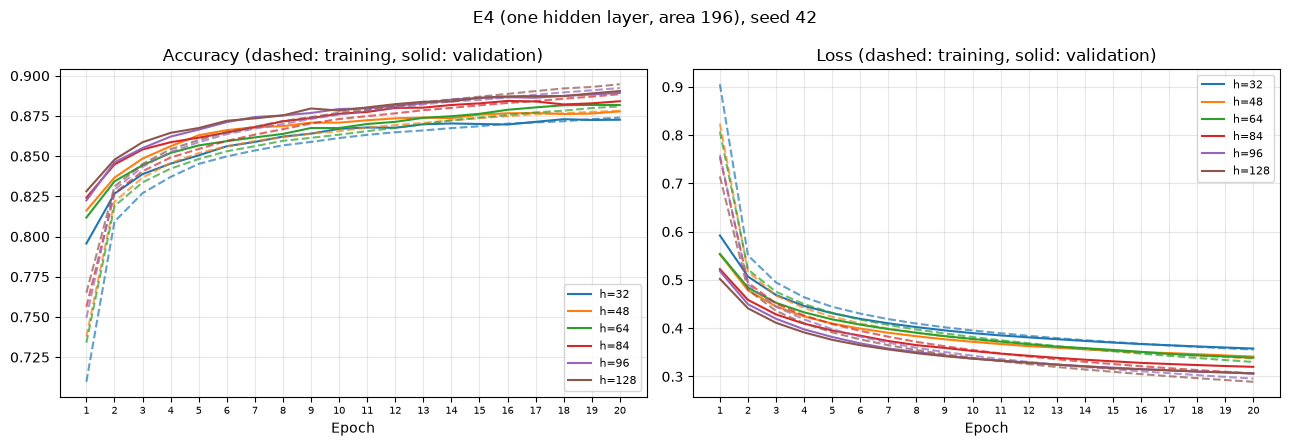

In [30]:
# Experiment 4, screen: width of a single hidden layer at d = 196 (area 14x14), seed 42.
# Everything else as before: ReLU, Adam 1e-3, 20 epochs, batch 128. h = 84 has the same budget as E3 (17,398 vs 17,418).
E4_WIDTHS = [32, 48, 64, 84, 96, 128]

e4_hists = screen_e4(E4_WIDTHS)
show_e4(e4_hists, E4_WIDTHS)

In [31]:
# Experiment 4, confirm: same rule as E1-E3, with seeds 7 and 126, from the seed-42 frontier upwards.
e4_choice, e4_runs = confirm_e4(e4_hists, E4_WIDTHS)

print(f"Threshold G + 0.003 = {threshold:.4f}")
if e4_choice is None:
    print('WARNING: no width passes on the 3-seed mean; E4 gives no choice (one hidden layer is not enough here).')
else:
    print(f"E4 choice: h = {e4_choice} ({mlp_params(196, [e4_choice]):,} parameters), mean = {np.mean(e4_runs[e4_choice]):.4f}")
display(pd.DataFrame({'s42': [v[0] for v in e4_runs.values()], 's7': [v[1] for v in e4_runs.values()],
                      's126': [v[2] for v in e4_runs.values()], 'mean': [np.mean(v) for v in e4_runs.values()],
                      'passes': [passes(np.mean(v)) for v in e4_runs.values()]},
                     index=pd.Index(list(e4_runs), name='hidden units')).round(4))

# Same budget as E3: h = 84 is always trained with the 3 seeds (reuse the runs above if they already include it)
e4_same_budget = same_budget_e4(e4_hists[84].history['val_accuracy'][-1], e4_runs)
print(f"Same budget (196-84, 17,398 params): val s42/s7/s126 = {[round(v, 4) for v in e4_same_budget]}, "
      f"mean = {np.mean(e4_same_budget):.4f}, passes: {passes(np.mean(e4_same_budget))}")
print(f"Mean difference vs E3 (196-{e3_choice}-{e3_choice}, mean {np.mean(e3_runs[e3_choice]):.4f}): "
      f"{np.mean(e4_same_budget) - np.mean(e3_runs[e3_choice]):+.4f}")

E4-area196-1L84-s7: 17,398 params, train 0.8889, val 0.8802, 0.74 s/epoch


E4-area196-1L84-s126: 17,398 params, train 0.8883, val 0.8825, 0.68 s/epoch
h = 84: val s42/s7/s126 = [0.8842, 0.8802, 0.8825], mean = 0.8823, passes: False


E4-area196-1L96-s7: 19,882 params, train 0.8907, val 0.8803, 0.69 s/epoch


E4-area196-1L96-s126: 19,882 params, train 0.8921, val 0.8833, 0.69 s/epoch
h = 96: val s42/s7/s126 = [0.8893, 0.8803, 0.8833], mean = 0.8843, passes: False


E4-area196-1L128-s7: 26,506 params, train 0.8939, val 0.8843, 0.69 s/epoch


E4-area196-1L128-s126: 26,506 params, train 0.8956, val 0.8880, 0.64 s/epoch
h = 128: val s42/s7/s126 = [0.8905, 0.8843, 0.888], mean = 0.8876, passes: True
Threshold G + 0.003 = 0.8862
E4 choice: h = 128 (26,506 parameters), mean = 0.8876


,s42,s7,s126,mean,passes
hidden units,,,,,
84,0.8842,0.8802,0.8825,0.8823,False
96,0.8893,0.8803,0.8833,0.8843,False
128,0.8905,0.8843,0.8880,0.8876,True


Same budget (196-84, 17,398 params): val s42/s7/s126 = [0.8842, 0.8802, 0.8825], mean = 0.8823, passes: False
Mean difference vs E3 (196-64-64, mean 0.8873): -0.0050


,hidden layers,parameters,val acc (seed 42),mean val acc (3 seeds),mean >= G + 0.003
model,,,,,
E3: 196-64-64,2,17418,0.8890,0.8873,True
E3b: 196-64-32,2,15018,0.8845,0.8834,False
E4 choice: 196-128,1,26506,0.8905,0.8876,True
E4 same budget: 196-84,1,17398,0.8842,0.8823,False


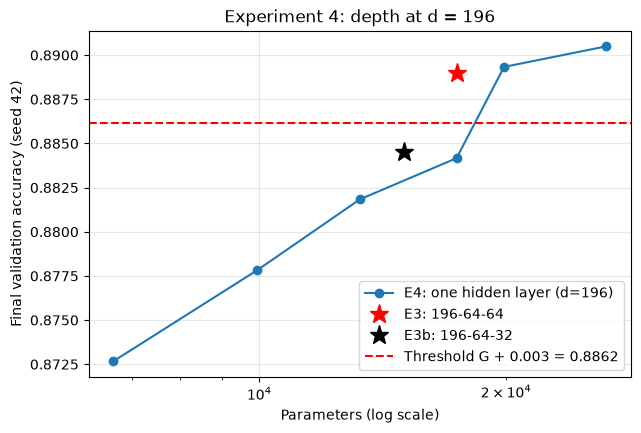

In [32]:
# Experiment 4, summary: depth comparison at d = 196 (area 14x14), validation accuracy.
def row(label, layers, params, val42, mean):
    """One table row; mean is NaN when the model was not confirmed with 3 seeds."""
    return {'model': label, 'hidden layers': layers, 'parameters': params, 'val acc (seed 42)': val42,
            'mean val acc (3 seeds)': mean, 'mean >= G + 0.003': passes(mean) if not np.isnan(mean) else np.nan}

rows = [row(f'E3: 196-{e3_choice}-{e3_choice}', 2, mlp_params(196, [e3_choice] * 2), e3_runs[e3_choice][0], np.mean(e3_runs[e3_choice])),
        row('E3b: 196-64-32', 2, 15018, e3b_runs[0], np.mean(e3b_runs))]
if e4_choice is not None:
    rows.append(row(f'E4 choice: 196-{e4_choice}', 1, mlp_params(196, [e4_choice]), e4_runs[e4_choice][0], np.mean(e4_runs[e4_choice])))
else:
    print('E4 has no choice (no width passed): no E4-choice row.')
# Same budget as E3 (17,398 vs 17,418 parameters), but one layer: the cleanest depth comparison
h84 = 84
rows.append(row(f'E4 same budget: 196-{h84}', 1, mlp_params(196, [h84]), e4_hists[h84].history['val_accuracy'][-1],
                np.mean(e4_same_budget)))  # 3-seed mean, always available
display(pd.DataFrame(rows).set_index('model').round(4))

plt.figure(figsize=(7, 4.5))
plt.plot([mlp_params(196, [h]) for h in E4_WIDTHS], [e4_hists[h].history['val_accuracy'][-1] for h in E4_WIDTHS],
         'o-', label='E4: one hidden layer (d=196)')
plt.plot(mlp_params(196, [e3_choice] * 2), e3_runs[e3_choice][0], 'r*', markersize=14, label=f'E3: 196-{e3_choice}-{e3_choice}')
plt.plot(15018, e3b_runs[0], 'k*', markersize=14, label='E3b: 196-64-32')
plt.axhline(threshold, color='r', linestyle='--', label=f'Threshold G + 0.003 = {threshold:.4f}')
plt.xscale('log')
plt.xlabel('Parameters (log scale)')
plt.ylabel('Final validation accuracy (seed 42)')
plt.title('Experiment 4: depth at d = 196')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Conclusions of Experiment 4

As can be seen, both predictions are confirmed. First, with the same budget, 196-84 (17,398 parameters) obtains a mean of 0.8823, versus 0.8873 for 196-64-64 (17,418), that is, 0.50 pp less. Moreover, it is worse in all three seeds (0.8842 / 0.8802 / 0.8825 versus 0.8890 / 0.8863 / 0.8865), so the difference is not explained by noise alone. Second, no one-layer network with fewer than 17,418 parameters meets the threshold. The smallest one that does is 196-128, with 26,506 parameters and mean 0.8876: 9,088 more parameters than E3 (52 % more) for a practically equal accuracy (0.8876 versus 0.8873).

| h | Parameters | Train (s42) | Val (s42) | Gap (s42) | Val mean (3 seeds) |
|---|---|---|---|---|---|
| 32 | 6,634 | 0.8740 | 0.8727 | 0.0014 | – |
| 48 | 9,946 | 0.8782 | 0.8778 | 0.0004 | – |
| 64 | 13,258 | 0.8810 | 0.8818 | −0.0009 | – |
| 84 | 17,398 | 0.8886 | 0.8842 | 0.0044 | 0.8823 |
| 96 | 19,882 | 0.8924 | 0.8893 | 0.0030 | 0.8843 |
| 128 | 26,506 | 0.8947 | 0.8905 | 0.0042 | 0.8876 |

Therefore, in this problem depth is more parameter-efficient. A single ReLU layer is already non-linear and, in theory, can approximate any function, but it may need many neurons. A plausible explanation is that the second layer combines the features of the first one and composes non-linearities, which allows the same decision boundary to be represented with fewer weights. However, we must qualify our hypothesis: we did not show that "neurons matter less than layers" in general. What we observe is that, for the same budget, splitting it into two layers performs better. Likewise, in E3b removing neurons from the second layer lowered the mean in all three seeds, although we cannot state whether that difference is due to seed-to-seed noise.

Likewise, the gap of all one-layer networks is minimal (from −0.0009 to 0.0044) and train rises with h, from 0.8740 to 0.8947. That is, they are limited by capacity (underfitting) and not by overfitting. This supports our expectation for E5: regularisation should help little.

The case h = 96 again shows the value of using three seeds: with seed 42 it passes (0.8893), but seed 7 gives 0.8803 and the mean (0.8843) falls below the threshold.

Consequently, the winner remains 196-64-64 (17,418 parameters). Since the hypothesis holds, in E4b we try narrower three- and four-layer networks before moving on to the training-improvement experiments (E5). As limitations, we use only three seeds and 20 epochs, and all decisions are made on validation.

### Experiment 4b: Deeper and narrower networks

We vary one factor, the number of hidden layers (three and four, with equal widths in all of them), with the 196-value input and the rest of the configuration of E3 fixed. The question is whether more and narrower layers can match the E3 winner with fewer parameters.

**Hypothesis**

The conclusions of E4 tell us that, with an almost equal budget, two hidden layers (196-64-64, 17,418 parameters) outperform a single wider layer (196-84, 17,398). Consequently, we expect that more and narrower layers will match or improve on the winner with fewer parameters, since each additional layer composes a new non-linear transformation. However, E3b showed that narrowing already has a cost: 196-64-32 (15,018) also drops in train, a sign of underfitting. Likewise, splitting the budget into more layers narrows the first layer (from 64 to 54 or 48 neurons), which may act as a bottleneck, and deeper networks may converge more slowly in 20 epochs. Therefore, we formulate two refutable predictions. First: with an almost equal budget, 196-54-54-54 (17,128) and 196-48-48-48-48 (17,002) will obtain a 3-seed validation mean equal to or higher than that of 196-64-64. Second: at least one three- or four-layer network with fewer than 17,418 parameters will meet the threshold. If both fail, the hypothesis is refuted.

**Design**

We vary only the depth, with equal widths in all hidden layers, and keep the input at 196 (14×14 averaging), ReLU, Adam 1e-3, 20 epochs and batch 128. We try three layers with h ∈ {32, 40, 48, 54} (from 8,746 to 17,128 parameters) and four layers with h ∈ {32, 40, 48} (from 9,802 to 17,002). Within each depth we apply D5 in ascending order, and the almost-equal-budget networks are always trained with seeds 42, 7 and 126. We choose the network with the fewest parameters that meets ≥ G + 0.003.

In [33]:
# Experiment 4b, helpers: DEEPER and NARROWER networks at d = 196 (area 14x14). Same structure as E3/E4 (D5 protocol):
# screen at seed 42, confirmation with seeds 7 and 126, but now inside each depth (3 and 4 hidden layers).
# All hidden layers of a network have the same width h; ReLU, Adam 1e-3, 20 epochs, batch 128, no regularisation.
# Parameters: 3 layers -> 2h^2 + 209h + 10; 4 layers -> 3h^2 + 210h + 10.
E4B_WIDTHS = {3: [32, 40, 48, 54], 4: [32, 40, 48]}
E4B_PARAMS = {3: [8746, 11570, 14650, 17128], 4: [9802, 13210, 17002]}   # from the design (D12)
E4B_BIGGEST = {3: 54, 4: 48}   # near-equal budget to E3 (196-64-64, 17,418): ALWAYS trained with the 3 seeds
E4B_X_TR, E4B_X_VA = e2_inputs('area', 196)  # same input as E3/E4 (built from train only)

def e4b_name(depth, h, seed):
    return f'E4b-area196-{depth}L{h}-s{seed}'

def e4b_train(depth, h, seed):
    """Train one 196-h-...-h-10 network (depth hidden layers of width h) and return the final (train, val) accuracy."""
    model, hist, _ = train_candidate(e4b_name(depth, h, seed), E4B_X_TR, y_train, E4B_X_VA, y_val,
                                     hidden_units=[h] * depth, seed=seed)
    assert model.count_params() == mlp_params(196, [h] * depth)  # parameter check (formula)
    assert model.count_params() == E4B_PARAMS[depth][E4B_WIDTHS[depth].index(h)]  # parameter check (design)
    return hist.history['accuracy'][-1], hist.history['val_accuracy'][-1]

def screen_e4b(depth):
    """Seed-42 screen of one depth, ascending widths. Returns {width: (train acc, val acc)}."""
    return {h: e4b_train(depth, h, 42) for h in E4B_WIDTHS[depth]}

def show_e4b_screen(depth, screen):
    """Table and training/validation curves of the seed-42 screen of one depth."""
    rows = [{'h': h, 'parameters': mlp_params(196, [h] * depth), 'train acc': tr, 'val acc': va,
             'gap (train - val)': tr - va, 'val acc >= G + 0.003': passes(va)} for h, (tr, va) in screen.items()]
    display(pd.DataFrame(rows).set_index('h').round(4))
    plot_train_val([HISTS[e4b_name(depth, h, 42)] for h in screen], [f'h={h}' for h in screen],
                   f'E4b ({depth} hidden layers, area 196), seed 42')

def confirm_e4b(depth, screen):
    """D5 inside one depth: seeds 7 and 126 from the largest width that fails below the smallest passing one
    (or from the smallest passing width) upwards; the first width whose 3-seed mean passes is the choice.
    Returns (choice, runs); runs = {width: [(train, val) for seeds 42, 7, 126]}. choice is None if nothing passes."""
    widths = sorted(screen)
    ok42 = [h for h in widths if passes(screen[h][1])]
    fail_below = [h for h in widths if ok42 and h < ok42[0]]
    start = max(fail_below) if fail_below else (ok42[0] if ok42 else widths[0])
    runs, choice = {}, None
    for h in [w for w in widths if w >= start]:
        runs[h] = [screen[h]] + [e4b_train(depth, h, seed) for seed in [7, 126]]
        mean = np.mean([va for _, va in runs[h]])
        print(f"{depth} layers, h = {h}: val s42/s7/s126 = {[round(va, 4) for _, va in runs[h]]}, mean = {mean:.4f}, passes: {passes(mean)}")
        if passes(mean):
            choice = h
            break
    return choice, runs

def same_budget_e4b(depth, screen, runs):
    """The near-equal-budget network of this depth (54 or 48) is ALWAYS trained with the 3 seeds
    (reusing the confirmation runs if it was already confirmed)."""
    h = E4B_BIGGEST[depth]
    if h not in runs:
        runs[h] = [screen[h]] + [e4b_train(depth, h, seed) for seed in [7, 126]]
    return runs[h]


E4b-area196-3L32-s42: 8,746 params, train 0.8823, val 0.8752, 0.61 s/epoch


E4b-area196-3L40-s42: 11,570 params, train 0.8872, val 0.8828, 0.65 s/epoch


E4b-area196-3L48-s42: 14,650 params, train 0.8936, val 0.8862, 0.74 s/epoch


E4b-area196-3L54-s42: 17,128 params, train 0.8972, val 0.8823, 0.83 s/epoch


,parameters,train acc,val acc,gap (train - val),val acc >= G + 0.003
h,,,,,
32,8746,0.8823,0.8752,0.0071,False
40,11570,0.8872,0.8828,0.0044,False
48,14650,0.8936,0.8862,0.0074,True
54,17128,0.8972,0.8823,0.0148,False


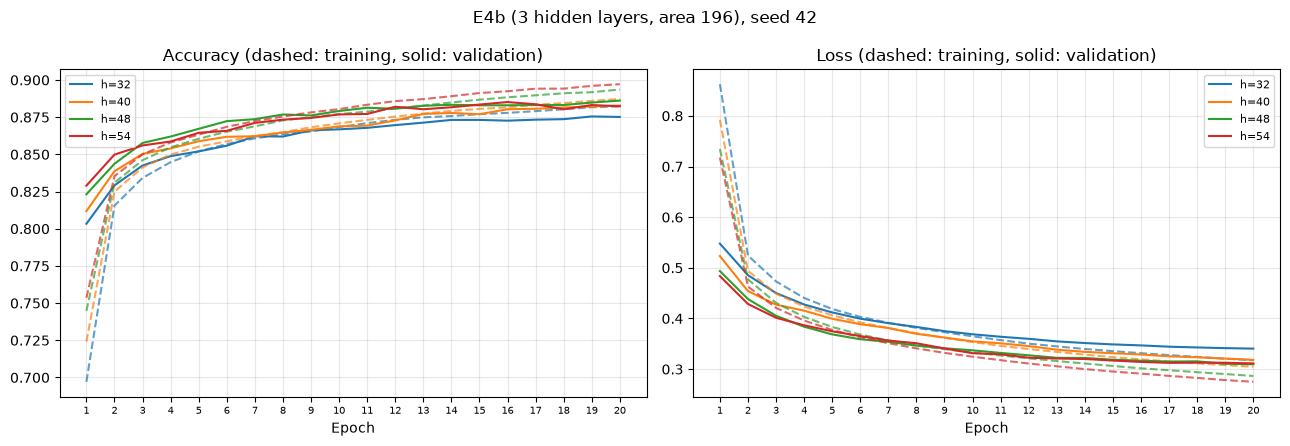

E4b-area196-4L32-s42: 9,802 params, train 0.8808, val 0.8742, 0.78 s/epoch


E4b-area196-4L40-s42: 13,210 params, train 0.8869, val 0.8800, 1.00 s/epoch


E4b-area196-4L48-s42: 17,002 params, train 0.8971, val 0.8833, 1.05 s/epoch


,parameters,train acc,val acc,gap (train - val),val acc >= G + 0.003
h,,,,,
32,9802,0.8808,0.8742,0.0066,False
40,13210,0.8869,0.8800,0.0069,False
48,17002,0.8971,0.8833,0.0138,False


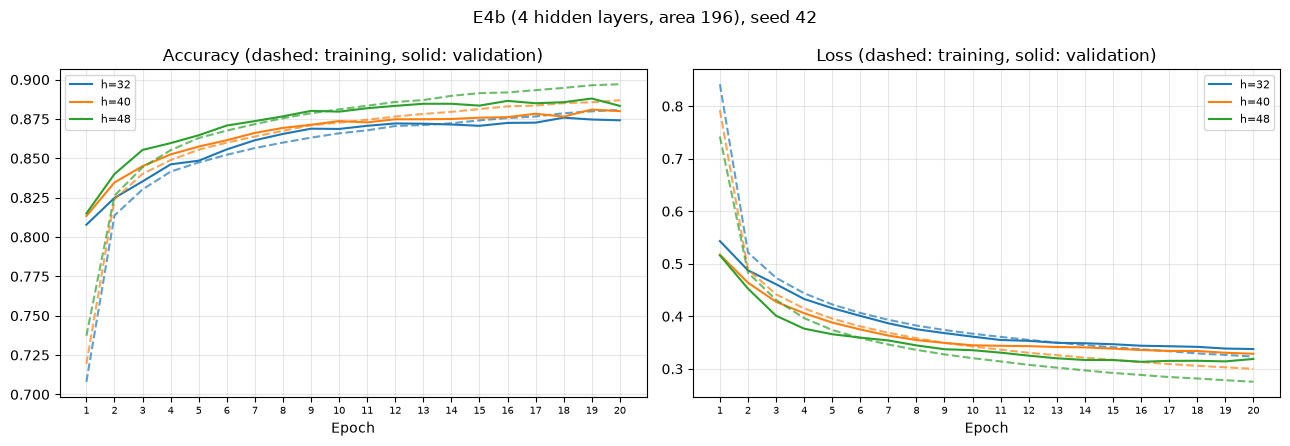

In [34]:
# Experiment 4b, screen: 3 hidden layers (h = 32, 40, 48, 54) and 4 hidden layers (h = 32, 40, 48), seed 42.
# Everything else fixed: input 196 (area 14x14), ReLU, Adam 1e-3, 20 epochs, batch 128, no regularisation.
e4b_screen = {}
for depth in [3, 4]:
    e4b_screen[depth] = screen_e4b(depth)
    show_e4b_screen(depth, e4b_screen[depth])


In [35]:
# Experiment 4b, confirm: D5 inside each depth, in ascending order (seeds 7 and 126), plus the near-equal-budget
# networks 196-54-54-54 and 196-48-48-48-48, which are always trained with the 3 seeds.
print(f"Threshold G + 0.003 = {threshold:.4f}")
e4b_choice, e4b_runs = {}, {}
for depth in [3, 4]:
    e4b_choice[depth], e4b_runs[depth] = confirm_e4b(depth, e4b_screen[depth])
    same_budget_e4b(depth, e4b_screen[depth], e4b_runs[depth])  # adds h = 54 / 48 to the runs if not yet there
    if e4b_choice[depth] is None:
        print(f"WARNING: no width passes with {depth} hidden layers.")
    else:
        h = e4b_choice[depth]
        print(f"E4b choice with {depth} hidden layers: 196-{'-'.join([str(h)] * depth)} "
              f"({mlp_params(196, [h] * depth):,} parameters), mean = {np.mean([va for _, va in e4b_runs[depth][h]]):.4f}")


Threshold G + 0.003 = 0.8862


E4b-area196-3L40-s7: 11,570 params, train 0.8887, val 0.8807, 0.78 s/epoch


E4b-area196-3L40-s126: 11,570 params, train 0.8883, val 0.8792, 0.74 s/epoch
3 layers, h = 40: val s42/s7/s126 = [0.8828, 0.8807, 0.8792], mean = 0.8809, passes: False


E4b-area196-3L48-s7: 14,650 params, train 0.8939, val 0.8855, 0.75 s/epoch


E4b-area196-3L48-s126: 14,650 params, train 0.8934, val 0.8787, 0.75 s/epoch
3 layers, h = 48: val s42/s7/s126 = [0.8862, 0.8855, 0.8787], mean = 0.8834, passes: False


E4b-area196-3L54-s7: 17,128 params, train 0.8973, val 0.8812, 0.79 s/epoch


... (3 outputs left out)

E4b-area196-4L40-s7: 13,210 params, train 0.8900, val 0.8803, 0.80 s/epoch


E4b-area196-4L40-s126: 13,210 params, train 0.8877, val 0.8808, 0.79 s/epoch
4 layers, h = 40: val s42/s7/s126 = [0.88, 0.8803, 0.8808], mean = 0.8804, passes: False


E4b-area196-4L48-s7: 17,002 params, train 0.8973, val 0.8772, 0.85 s/epoch


E4b-area196-4L48-s126: 17,002 params, train 0.8968, val 0.8752, 0.84 s/epoch
4 layers, h = 48: val s42/s7/s126 = [0.8833, 0.8772, 0.8752], mean = 0.8786, passes: False


,hidden layers,parameters,val s42,val s7,val s126,train s42,train s7,train s126,mean val (3 seeds),mean train (3 seeds),std val (3 seeds),mean val >= G + 0.003
network,,,,,,,,,,,,
196-40-40-40,3,11570,0.8828,0.8807,0.8792,0.8872,0.8887,0.8883,0.8809,0.8881,0.0018,False
196-48-48-48,3,14650,0.8862,0.8855,0.8787,0.8936,0.8939,0.8934,0.8834,0.8937,0.0042,False
196-54-54-54,3,17128,0.8823,0.8812,0.8830,0.8972,0.8973,0.8964,0.8822,0.8969,0.0009,False
196-32-32-32-32,4,9802,0.8742,0.8823,0.8763,0.8808,0.8878,0.8823,0.8776,0.8836,0.0042,False
196-40-40-40-40,4,13210,0.8800,0.8803,0.8808,0.8869,0.8900,0.8877,0.8804,0.8882,0.0004,False
196-48-48-48-48,4,17002,0.8833,0.8772,0.8752,0.8971,0.8973,0.8968,0.8786,0.8970,0.0043,False
E3: 196-64-64 (reference winner),2,17418,0.8890,0.8863,0.8865,0.8952,0.8954,0.8968,0.8873,0.8958,0.0015,True


Threshold G + 0.003 = 0.8862
E4b winner with 3 hidden layers: none
E4b winner with 4 hidden layers: none

Prediction 1: 3-seed mean of the near-equal-budget networks vs E3 196-64-64 (mean 0.8873, std between seeds 0.0015):
  196-54-54-54 (17,128 params): mean 0.8822, difference vs E3 -0.0051 (-0.51 pp), std between seeds 0.0009, mean >= E3 mean: False
  196-48-48-48-48 (17,002 params): mean 0.8786, difference vs E3 -0.0087 (-0.87 pp), std between seeds 0.0043, mean >= E3 mean: False
Prediction 1 holds for both networks: False

Prediction 2: networks with < 17,418 parameters and 3-seed mean >= 0.8862: none
Prediction 2 holds: False


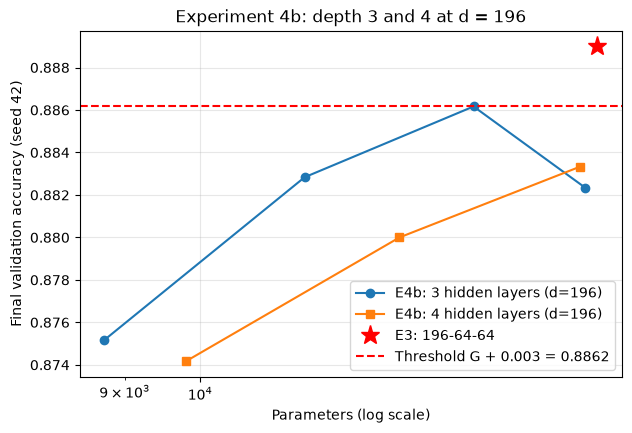

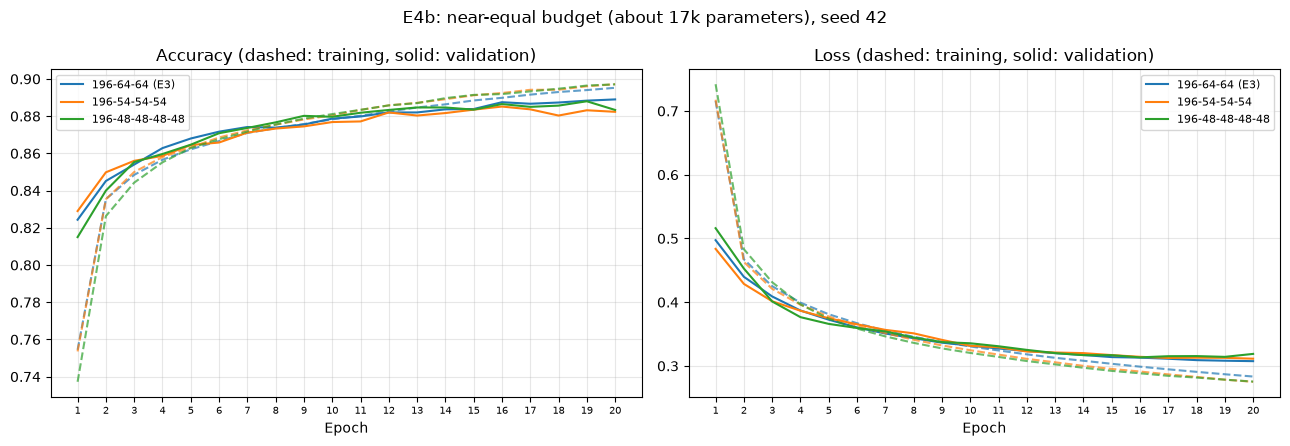

In [36]:
# Experiment 4b, summary: every network trained in E4b (3 or 4 hidden layers), validation accuracy.
rows = []
for depth in [3, 4]:
    for h, vals in sorted(e4b_runs[depth].items()):
        rows.append({'network': f"196-{'-'.join([str(h)] * depth)}", 'hidden layers': depth,
                     'parameters': mlp_params(196, [h] * depth),
                     'val s42': vals[0][1], 'val s7': vals[1][1], 'val s126': vals[2][1],
                     'train s42': vals[0][0], 'train s7': vals[1][0], 'train s126': vals[2][0],
                     'mean val (3 seeds)': np.mean([v for _, v in vals]),
                     'mean train (3 seeds)': np.mean([t for t, _ in vals]),
                     'std val (3 seeds)': np.std([v for _, v in vals], ddof=1),
                     'mean val >= G + 0.003': passes(np.mean([v for _, v in vals]))})
e3_vals = e3_runs[e3_choice]   # E3: 196-64-64, the current winner
# Train accuracy of the three E3 runs, read from `results` (same value as the history, nothing is re-trained)
_res = pd.DataFrame(results).set_index('model')
e3_train = [_res.loc[f'E3-area196-{e3_choice}x2-s{s}', 'final_train_accuracy'] for s in [42, 7, 126]]
rows.append({'network': f'E3: 196-{e3_choice}-{e3_choice} (reference winner)', 'hidden layers': 2,
             'parameters': mlp_params(196, [e3_choice] * 2),
             'val s42': e3_vals[0], 'val s7': e3_vals[1], 'val s126': e3_vals[2],
             'train s42': e3_hists[e3_choice].history['accuracy'][-1], 'train s7': e3_train[1], 'train s126': e3_train[2],
             'mean val (3 seeds)': np.mean(e3_vals), 'mean train (3 seeds)': np.mean(e3_train),
             'std val (3 seeds)': np.std(e3_vals, ddof=1), 'mean val >= G + 0.003': passes(np.mean(e3_vals))})
e4b_table = pd.DataFrame(rows).set_index('network')
pd.set_option('display.width', 250)
display(e4b_table.round(4))

# Winner of each depth, and overall (fewest parameters among the winners)
print(f"Threshold G + 0.003 = {threshold:.4f}")
for depth in [3, 4]:
    h = e4b_choice[depth]
    if h is None:
        print(f"E4b winner with {depth} hidden layers: none")
    else:
        print(f"E4b winner with {depth} hidden layers: 196-{'-'.join([str(h)] * depth)}, "
              f"{mlp_params(196, [h] * depth):,} parameters, mean val = {np.mean([v for _, v in e4b_runs[depth][h]]):.4f}")
winners = {depth: mlp_params(196, [e4b_choice[depth]] * depth) for depth in [3, 4] if e4b_choice[depth] is not None}
if winners:
    best_depth = min(winners, key=winners.get)
    print(f"E4b overall winner (fewest parameters): {best_depth} hidden layers, h = {e4b_choice[best_depth]}, {winners[best_depth]:,} parameters")

# Prediction 1: with near-equal budget, 196-54-54-54 and 196-48-48-48-48 have a 3-seed mean >= that of 196-64-64
m_e3 = np.mean(e3_vals)
print(f"\nPrediction 1: 3-seed mean of the near-equal-budget networks vs E3 196-{e3_choice}-{e3_choice} "
      f"(mean {m_e3:.4f}, std between seeds {np.std(e3_vals, ddof=1):.4f}):")
p1 = []
for depth in [3, 4]:
    h = E4B_BIGGEST[depth]
    vals = [v for _, v in e4b_runs[depth][h]]
    ok = at_least(np.mean(vals), m_e3)
    p1.append(ok)
    print(f"  196-{'-'.join([str(h)] * depth)} ({mlp_params(196, [h] * depth):,} params): mean {np.mean(vals):.4f}, "
          f"difference vs E3 {np.mean(vals) - m_e3:+.4f} ({(np.mean(vals) - m_e3) * 100:+.2f} pp), "
          f"std between seeds {np.std(vals, ddof=1):.4f}, mean >= E3 mean: {ok}")
print(f"Prediction 1 holds for both networks: {all(p1)}")

# Prediction 2: some 3- or 4-layer network with fewer parameters than E3 reaches the threshold (3-seed mean)
small = [(depth, h) for depth in [3, 4] for h in e4b_runs[depth]
         if mlp_params(196, [h] * depth) < mlp_params(196, [e3_choice] * 2)
         and passes(np.mean([v for _, v in e4b_runs[depth][h]]))]
print(f"\nPrediction 2: networks with < {mlp_params(196, [e3_choice] * 2):,} parameters and 3-seed mean >= {threshold:.4f}: "
      f"{[f'{d} layers, h={h}' for d, h in small] if small else 'none'}")
print(f"Prediction 2 holds: {bool(small)}")

# Validation accuracy (seed 42) against parameters: every network of E4b together with E3
plt.figure(figsize=(7, 4.5))
for depth, style in [(3, 'o-'), (4, 's-')]:
    plt.plot([mlp_params(196, [h] * depth) for h in E4B_WIDTHS[depth]], [e4b_screen[depth][h][1] for h in E4B_WIDTHS[depth]],
             style, label=f'E4b: {depth} hidden layers (d=196)')
plt.plot(mlp_params(196, [e3_choice] * 2), e3_vals[0], 'r*', markersize=14, label=f'E3: 196-{e3_choice}-{e3_choice}')
plt.axhline(threshold, color='r', linestyle='--', label=f'Threshold G + 0.003 = {threshold:.4f}')
plt.xscale('log')
plt.xlabel('Parameters (log scale)')
plt.ylabel('Final validation accuracy (seed 42)')
plt.title('Experiment 4b: depth 3 and 4 at d = 196')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Seed-42 training/validation curves of the near-equal-budget networks against E3
plot_train_val([e3_hists[e3_choice], HISTS[e4b_name(3, 54, 42)], HISTS[e4b_name(4, 48, 42)]],
               [f'196-{e3_choice}-{e3_choice} (E3)', '196-54-54-54', '196-48-48-48-48'],
               'E4b: near-equal budget (about 17k parameters), seed 42')


### Conclusions of Experiment 4b

**Verdict.** The hypothesis is refuted: both predictions fail. With an almost equal budget, 196-54-54-54 (17,128 parameters) obtains a mean of 0.8822 and 196-48-48-48-48 (17,002) one of 0.8786, both below 196-64-64 (0.8873): −0.51 and −0.87 points. Likewise, no three- or four-layer network with fewer than 17,418 parameters reaches the threshold of 0.8862.

| Network | Parameters | Train mean | Val mean | sd val | Gap (train − val) |
|---|---|---|---|---|---|
| 196-32-32-32 | 8,746 | 0.8823 (s42) | 0.8752 (s42) | – | 0.0071 (s42) |
| 196-40-40-40 | 11,570 | 0.8881 | 0.8809 | 0.0018 | 0.0072 |
| 196-48-48-48 | 14,650 | 0.8937 | 0.8834 | 0.0042 | 0.0102 |
| 196-54-54-54 | 17,128 | 0.8969 | 0.8822 | 0.0009 | 0.0148 |
| 196-32-32-32-32 | 9,802 | 0.8836 | 0.8776 | 0.0042 | 0.0060 |
| 196-40-40-40-40 | 13,210 | 0.8882 | 0.8804 | 0.0004 | 0.0078 |
| 196-48-48-48-48 | 17,002 | 0.8970 | 0.8786 | 0.0043 | 0.0185 |
| 196-64-64 (E3) | 17,418 | 0.8958 | 0.8873 | 0.0015 | 0.0085 |

**Seed-to-seed noise.** The three seeds of 196-54-54-54 (0.8823, 0.8812 and 0.8830) and the three of 196-48-48-48-48 (0.8833, 0.8772 and 0.8752) fall below the worst seed of 196-64-64 (0.8863). Therefore, the differences of means (−0.0051 and −0.0087) are not explained by seed-to-seed noise, although with only three seeds per network we remain cautious. Consequently, at this budget, more and narrower layers do not match two layers of 64.

**Protocol.** With three layers, 196-48-48-48 passed the threshold with seed 42, so the confirmation started at h = 40, the largest width below it that failed. With four layers no width passed with seed 42, so, by the rule that the code applies since E1, we confirmed all of them starting from the smallest (h = 32).

**Why.** What we observed contradicts part of our reasoning. We expected deep networks to converge more slowly in 20 epochs. However, the two almost-equal-budget networks reach a train accuracy equal to or higher than that of 196-64-64 (0.8969 and 0.8970 versus 0.8958). The difference appears in validation: the gap rises from 0.0085 to 0.0148 and 0.0185. The same is seen when adding a fourth layer of 48: going from 196-48-48-48 to 196-48-48-48-48 adds 2,352 parameters, raises train (from 0.8937 to 0.8970) and lowers validation (from 0.8834 to 0.8786). Therefore, our reading is that the extra depth is spent on fitting the training set and not on generalising. The result coincides with what we anticipated, but not the mechanism: the hypothesis foresaw that the narrower first layer would act as a capacity bottleneck, which would also have lowered the train accuracy, and what is observed is that train rises. A plausible explanation still has to do with where the parameters are. The first layer, the one that sees the 196 pixels, concentrates most of the weights, and splitting the budget into more layers narrows it from 64 to 54 or 48 neurons. With fewer features extracted from the input, the following layers might recombine them in a way that fits the training set better but generalises worse. We have not measured this directly, and we have not counted dead ReLU neurons either, which could aggravate the problem in such narrow layers. Moreover, in E5 regularisation does not improve 196-48-48-48, which weakens this overfitting reading (we discuss it in the conclusions of E5). Together with E4 (196-84, 17,398 parameters, 0.8823), the result indicates that, with about 17,400 parameters, two hidden layers work better than one, three or four.

**Behaviours that do not allow a conclusion.** With three layers, validation rises from h = 40 to h = 48 (from 0.8809 to 0.8834) and drops slightly at h = 54 (0.8822), although train keeps rising. The difference between 48 and 54 (0.0012) is smaller than the deviation of 196-48-48-48 (0.0042), so we do not interpret it as a real maximum. Likewise, 196-48-48-48 passes the threshold with seed 42 (0.8862), but seed 126 gives 0.8787. This shows, once again, the value of confirming with three seeds.

**Decision.** E4b does not find any winner with fewer than 17,418 parameters, so the winner remains 196-64-64 and point 7 of D12 (repeating E5 on a new winner) is not triggered. However, 196-48-48-48 (14,650 parameters) and 196-64-32 (15,018) are separated by a difference of 1 hit in 18,000 (0.883444 versus 0.883389). D13 extends the protocol; applying D8 to the extended set, the candidate is 196-48-48-48. D8 chooses it by higher mean; the tie-break by fewer parameters would have given the same result. We apply the E5 grid to it in the D13 block.

### Experiment 5: Optimiser and regularisation

We vary the training recipe (optimiser, learning rate and regularisation) on fixed architectures with the 196-value input, instead of changing the architecture. The question is whether any recipe lets a smaller network reach the validation threshold.

**Rule for the candidate network (fixed before the training-improvement experiments).** Experiments E1–E4b are network-architecture experiments: they reduce the size by designing smaller networks trained from scratch. From here on, the experiments are training-improvement experiments (optimiser and regularisation) with the architecture fixed. The winner is the network with the fewest parameters whose validation mean over seeds 42, 7 and 126 meets ≥ G + 0.003. The candidate is, among the networks with fewer parameters than the winner that failed and have a 3-seed mean, the one with the highest mean (the closest to the threshold). If any training improvement makes the candidate meet the threshold, it becomes the winner and the rule is applied again, with a maximum of two rescues.

*Clarification (the tie-break was already part of D8 before E3b/E4):* if two networks tie in mean, the one with fewer parameters is chosen.

**Hypothesis**

We expect regularisation to help little or even worsen validation. The networks of E3, E3b and E4 barely overfit: the winner 196-64-64 (17,418 parameters) has a gap of 0.0062 with seed 42, the candidate 196-64-32 (15,018 parameters) one of 0.0051, and the one-layer networks of E4 lie between −0.0009 and 0.0044, with a train accuracy that keeps rising with h. Consequently, the dominant problem is underfitting, and restricting a capacity that is already scarce should aggravate it. Therefore we predict that no regularisation will clearly improve the unregularised version of the same optimiser, that the effect will be more negative in the candidate, which is smaller, than in the winner, and that L1 will be the most harmful, because it pushes weights to zero and reduces the effective capacity even further.

However, with only 20 epochs the optimiser can make a difference. Adam and RMSprop adapt the step of each weight and should converge earlier, ending above SGD with momentum, whose validation we expect to keep rising at epoch 20. Likewise, raising the learning rate should benefit SGD more than the adaptive optimisers, because its limitation is the speed of convergence.

Given the above, if any combination rescues the candidate, we expect it to be through the optimiser or the learning rate and not through regularisation.

**Design**

We apply a 3×4 grid to the winner (for information only) and to the candidate: Adam 1e-3 (control, reused), RMSprop 1e-3 and SGD with momentum 0.9 at 1e-2, each one without regularisation, with Dropout 0.1, with L1 1e-5 or with L2 1e-4, only on the hidden layers. We add a learning-rate block without regularisation: Adam 3e-3, RMSprop 3e-3 and SGD 3e-2. We train each combination with seeds 42, 7 and 126. The candidate is rescued if any combination reaches a validation mean ≥ 0.8862; if several do, the one with the highest mean wins, with a tie-break by the smallest change, and there are at most 2 rescues. In the Dropout combinations we additionally measure the train accuracy with Dropout switched off.

In [37]:
# Experiment 5, helpers: optimiser x regularisation grid on a FIXED architecture (input 196, area 14x14).
# Only the training recipe changes; the control (Adam 1e-3, no regularisation) is reused from E3/E3b, not retrained.
opt_grid = [('adam', 1e-3), ('rmsprop', 1e-3), ('sgd', 1e-2)]
reg_grid = [('none', {}), ('drop0.1', {'dropout': 0.1}), ('l1_1e-05', {'l1': 1e-5}), ('l2_0.0001', {'l2': 1e-4})]
lr_grid = [('adam', 3e-3), ('rmsprop', 3e-3), ('sgd', 3e-2)]   # lr x3, without regularisation
BASE_LR = {'adam': 1e-3, 'rmsprop': 1e-3, 'sgd': 1e-2}

def run_e5(d, hidden_units, opt_grid, reg_grid, base_fmt, prefix='E5', seeds=(42, 7, 126), method='area'):
    """Train (or reuse) every optimiser x regularisation combination with the 3 seeds.
    base_fmt: name of the Adam 1e-3 control in `results`, e.g. 'E3-area196-64x2-s{seed}'; None = train everything.
    Returns a table (one row per combination) and the seed-42 histories {(opt, lr, reg): history}."""
    arch = f"{method}{d}-" + '-'.join(map(str, hidden_units))
    x_tr, x_va = e2_inputs(method, d)
    res = pd.DataFrame(results)
    rows, hists42 = [], {}
    for opt, lr in opt_grid:
        for reg, reg_kw in reg_grid:
            vals, trains, train_evals = [], [], []
            for seed in seeds:
                if base_fmt is not None and (opt, lr, reg) == ('adam', 1e-3, 'none'):
                    # Control: already trained in an earlier experiment, read it from the results table
                    name = base_fmt.format(seed=seed)
                    row = res[res['model'] == name]
                    assert len(row) == 1, name
                    vals.append(row['final_val_accuracy'].iloc[0])
                    trains.append(row['final_train_accuracy'].iloc[0])
                    train_evals.append(np.nan)                       # no model kept: not re-evaluated
                    hist = HISTS.get(name)
                else:
                    name = f"{prefix}-{arch}-{opt}_{lr:g}-{reg}-s{seed}"
                    model, hist, _ = train_candidate(name, x_tr, y_train, x_va, y_val, hidden_units, seed,
                                                     optimizer=opt, lr=lr, **reg_kw)
                    assert model.count_params() == mlp_params(d, hidden_units)  # same architecture as the control
                    vals.append(hist.history['val_accuracy'][-1])
                    trains.append(hist.history['accuracy'][-1])
                    # Train accuracy measured with Dropout switched off (evaluate), comparable with validation
                    train_evals.append(model.evaluate(x_tr, y_train, verbose=0)[1])
                if seed == 42 and hist is not None:
                    hists42[(opt, lr, reg)] = hist
            rows.append({'optimizer': opt, 'lr': lr, 'reg': reg,
                         's42': vals[0], 's7': vals[1], 's126': vals[2],
                         'mean': np.mean(vals), 'sd': np.std(vals, ddof=1),
                         'train acc (history)': np.mean(trains), 'train acc (eval)': np.mean(train_evals),
                         'gap (history)': np.mean(trains) - np.mean(vals),
                         'gap (eval)': np.mean(train_evals) - np.mean(vals),
                         'passes': bool(passes(np.mean(vals)))})
            print(f"{opt} {lr:g} {reg}: mean val {np.mean(vals):.4f}, passes: {passes(np.mean(vals))}")
    return pd.DataFrame(rows), hists42

def run_e5_full(d, hidden_units, base_fmt, method='area', prefix='E5'):
    """Main grid (3 x 4) plus the lr x3 block, joined in one table and one dict of seed-42 histories.
    prefix: name prefix of the trained models ('E5' original grid, 'E5c' D13 grid, ...)."""
    t_main, h_main = run_e5(d, hidden_units, opt_grid, reg_grid, base_fmt=base_fmt, prefix=prefix, method=method)
    t_lr, h_lr = run_e5(d, hidden_units, lr_grid, [('none', {})], base_fmt=None, prefix=prefix, method=method)
    return pd.concat([t_main, t_lr], ignore_index=True), {**h_main, **h_lr}

def show_e5(table, hists42, title):
    """Heatmaps (validation mean, train-val gap) of the main grid, and seed-42 curves without regularisation."""
    main = table[[np.isclose(lr, BASE_LR[o]) for o, lr in zip(table['optimizer'], table['lr'])]]
    opts, regs = list(main['optimizer'].unique()), list(main['reg'].unique())
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
    for ax, col, label in zip(axes, ['mean', 'gap (history)'], ['Mean validation accuracy (3 seeds)', 'Mean gap (train - val)']):
        grid = np.full((len(opts), len(regs)), np.nan)
        for i, o in enumerate(opts):
            for j, r in enumerate(regs):
                sel = main[(main['optimizer'] == o) & (main['reg'] == r)]
                grid[i, j] = sel[col].iloc[0]
                ax.text(j, i, f"{grid[i, j]:.4f}", ha='center', va='center', fontsize=9, color='white' if col == 'mean' else 'black')
                if col == 'mean' and sel['passes'].iloc[0]:   # thick border: cell reaches G + 0.003
                    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor='red', linewidth=3))
        im = ax.imshow(grid, cmap='viridis' if col == 'mean' else 'magma_r', aspect='auto')
        ax.set_xticks(range(len(regs)))
        ax.set_xticklabels(regs)
        ax.set_yticks(range(len(opts)))
        ax.set_yticklabels(opts)
        ax.set_title(label)
        fig.colorbar(im, ax=ax)
    fig.suptitle(f"{title} (red border: mean >= G + 0.003 = {threshold:.4f})")
    fig.text(0.5, -0.04, "Note: with Dropout the gap uses the train accuracy of history (measured with Dropout ON); "
             "the table column 'gap (eval)' uses Dropout OFF.", ha='center', fontsize=8)
    plt.tight_layout()
    plt.show()
    # Curves, seed 42, no regularisation: base lr, then lr x3
    for label, keys in [('base lr', [(o, BASE_LR[o], 'none') for o in opts]),
                        ('lr x3', [(o, lr, 'none') for o, lr in lr_grid])]:
        keys = [k for k in keys if k in hists42]
        if keys:
            plot_train_val([hists42[k] for k in keys], [f"{k[0]} {k[1]:g}" for k in keys], f"{title}: {label}, seed 42")

def decide_e5(table):
    """Rule D10: among the combinations that pass, the highest mean; if others are within 0.0005 of it, prefer
    the smallest change from the control: optimiser adam > rmsprop > sgd, base lr > x3, reg none > l2 > drop > l1.
    Returns the chosen row, or None if nothing passes."""
    ok = table[table['passes']]
    if ok.empty:
        return None
    top = ok['mean'].max()
    close = ok[[not at_least(top - m, 0.0005) for m in ok['mean']]]   # difference < 0.0005 (includes the top row)
    reg_rank = {'none': 0, 'l2': 1, 'drop': 2, 'l1': 3}
    def change(r):
        lr_rank = 0 if np.isclose(r['lr'], BASE_LR[r['optimizer']]) else 1
        reg = next(v for k, v in reg_rank.items() if r['reg'].startswith(k))
        return (['adam', 'rmsprop', 'sgd'].index(r['optimizer']), lr_rank, reg)
    return min((r for _, r in close.iterrows()), key=change)
# ---- Rule D8 (candidate network) in code, so that nobody has to write the network by hand -----------------------
import re

# POOL OF THE ORIGINAL E5: the networks that existed when E5 was designed (E3, E3b and E4). It is filtered by name
# prefix on purpose: E4b runs EARLIER in the notebook than E5 but was designed afterwards, so without the filter a
# full "Restart and run all" would pick a different candidate than the original E5 used (196-64-32).
# 'E4-' does not match 'E4b-' and 'E3-' does not match 'E3b-', so each experiment is listed explicitly.
D8_POOL_E5 = ('E3-', 'E3b-', 'E4-')
# POOL OF D13: the original pool extended with E4b (deeper and narrower networks).
D8_POOL_D13 = D8_POOL_E5 + ('E4b-',)

def d8_pool(prefixes, max_params):
    """Adam 1e-3 networks of the experiments in `prefixes`, trained with the 3 seeds (42, 7, 126), with FEWER than
    max_params parameters and a 3-seed mean validation accuracy BELOW the threshold (they failed).
    Returns a DataFrame (base name, parameters, mean val), best mean first and, on ties, fewest parameters first."""
    res = pd.DataFrame(results)
    # A re-run cell would append the same run name twice and groupby/len(g) == 3 would silently drop that network
    dup = res['model'][res['model'].duplicated()].unique().tolist()
    assert not dup, f"Duplicate run names in `results` (a cell was re-run?): {dup[:5]}. Use Restart and run all."
    res = res[res['model'].str.startswith(tuple(prefixes))]
    res = res.assign(base=res['model'].str.replace(r'-s\d+$', '', regex=True),
                     seed=res['model'].str.extract(r'-s(\d+)$')[0].astype(int))
    rows = []
    for base, g in res.groupby('base'):
        if len(g) == 3 and set(g['seed']) == {42, 7, 126} and g['parameters'].iloc[0] < max_params:
            mean = g['final_val_accuracy'].mean()
            if not passes(mean):
                rows.append({'base': base, 'parameters': int(g['parameters'].iloc[0]), 'mean val': mean})
    pool = pd.DataFrame(rows, columns=['base', 'parameters', 'mean val'])
    return pool.sort_values(['mean val', 'parameters'], ascending=[False, True]).reset_index(drop=True)

def d8_choose(pool):
    """D8: the highest mean; a difference below EPS (rounding noise) is a tie, and a tie goes to the network with
    fewer parameters. Returns (chosen row, True if it was a tie)."""
    top = pool['mean val'].max()
    tied = pool[[at_least(m, top) for m in pool['mean val']]]
    return tied.sort_values('parameters').iloc[0], len(tied) > 1

def arch_from_name(base):
    """(method, input size, hidden units) from a network base name, e.g. 'E3-area196-64x2', 'E3b-area196-64-32',
    'E4-area196-1L84' (one layer), 'E4b-area196-3L48' (three layers of 48), 'E1-784-64x2'."""
    m = re.match(r'^E\d[a-z]?-(area|var)?(\d+)-(.+)$', base)
    method, d, rest = m.group(1) or 'area', int(m.group(2)), m.group(3)
    deep = re.fullmatch(r'(\d+)L(\d+)', rest)          # '<layers>L<width>': E4 (1L84) and E4b (3L48, 4L32)
    if deep:
        hidden = [int(deep.group(2))] * int(deep.group(1))
    elif rest.endswith('x2'):                           # '<width>x2': two equal layers (E1, E3)
        hidden = [int(rest[:-2])] * 2
    else:                                               # '64-32': explicit list
        hidden = [int(u) for u in rest.split('-')]
    return method, d, hidden

def net_label(d, hidden):
    """Short name such as '196-48-48-48'."""
    return '-'.join(str(u) for u in [d] + list(hidden))


adam 0.001 none: mean val 0.8873, passes: True


E5-area196-64-64-adam_0.001-drop0.1-s42: 17,418 params, train 0.8849, val 0.8888, 0.83 s/epoch


E5-area196-64-64-adam_0.001-drop0.1-s7: 17,418 params, train 0.8857, val 0.8872, 0.88 s/epoch


E5-area196-64-64-adam_0.001-drop0.1-s126: 17,418 params, train 0.8830, val 0.8828, 0.83 s/epoch


adam 0.001 drop0.1: mean val 0.8863, passes: True


E5-area196-64-64-adam_0.001-l1_1e-05-s42: 17,418 params, train 0.8949, val 0.8868, 0.63 s/epoch


... (48 outputs left out)

E5-area196-64-64-sgd_0.03-none-s7: 17,418 params, train 0.8963, val 0.8868, 0.52 s/epoch


E5-area196-64-64-sgd_0.03-none-s126: 17,418 params, train 0.8946, val 0.8760, 0.51 s/epoch


sgd 0.03 none: mean val 0.8812, passes: False


,optimizer,lr,reg,s42,s7,s126,mean,sd,train acc (history),train acc (eval),gap (history),gap (eval),passes
0,adam,0.001,none,0.8890,0.8863,0.8865,0.8873,0.0015,0.8958,NaN,0.0085,NaN,True
1,adam,0.001,drop0.1,0.8888,0.8872,0.8828,0.8863,0.0031,0.8845,0.8968,-0.0018,0.0105,True
2,adam,0.001,l1_1e-05,0.8868,0.8797,0.8857,0.8841,0.0038,0.8940,0.8953,0.0100,0.0113,False
3,adam,0.001,l2_0.0001,0.8845,0.8795,0.8850,0.8830,0.0030,0.8931,0.8940,0.0101,0.0110,False
4,rmsprop,0.001,none,0.8777,0.8853,0.8777,0.8802,0.0044,0.8955,0.8901,0.0153,0.0098,False
5,rmsprop,0.001,drop0.1,0.8802,0.8823,0.8788,0.8804,0.0018,0.8832,0.8933,0.0028,0.0129,False
6,rmsprop,0.001,l1_1e-05,0.8748,0.8830,0.8785,0.8788,0.0041,0.8942,0.8894,0.0154,0.0106,False
7,rmsprop,0.001,l2_0.0001,0.8730,0.8842,0.8712,0.8761,0.0070,0.8923,0.8867,0.0162,0.0106,False
8,sgd,0.010,none,0.8760,0.8808,0.8757,0.8775,0.0029,0.8826,0.8831,0.0051,0.0056,False
9,sgd,0.010,drop0.1,0.8763,0.8760,0.8747,0.8757,0.0009,0.8697,0.8802,-0.0060,0.0045,False


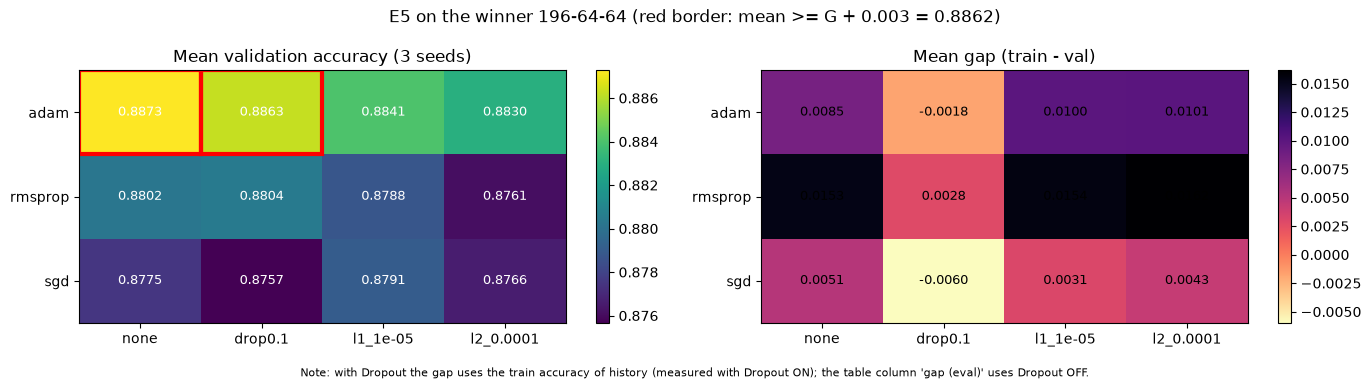

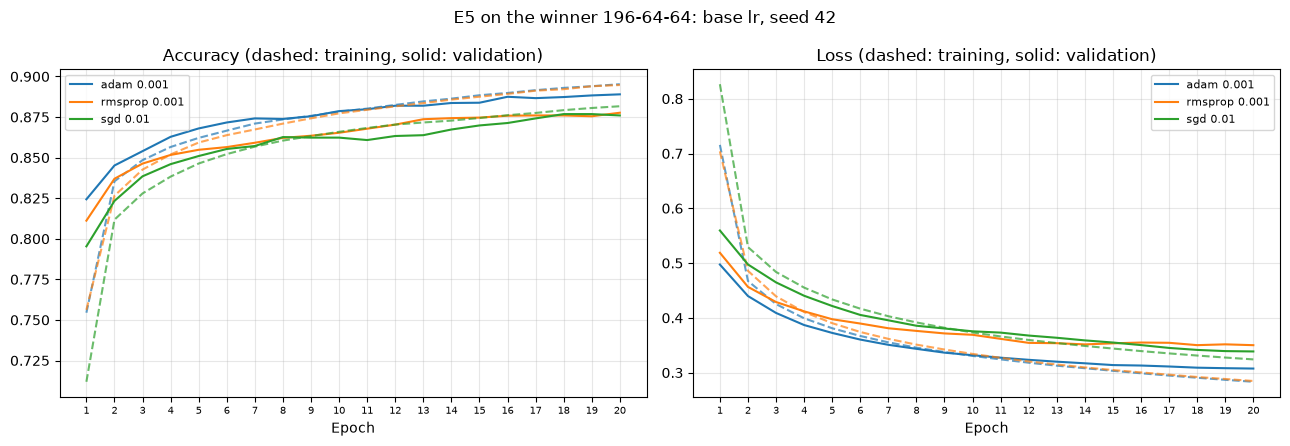

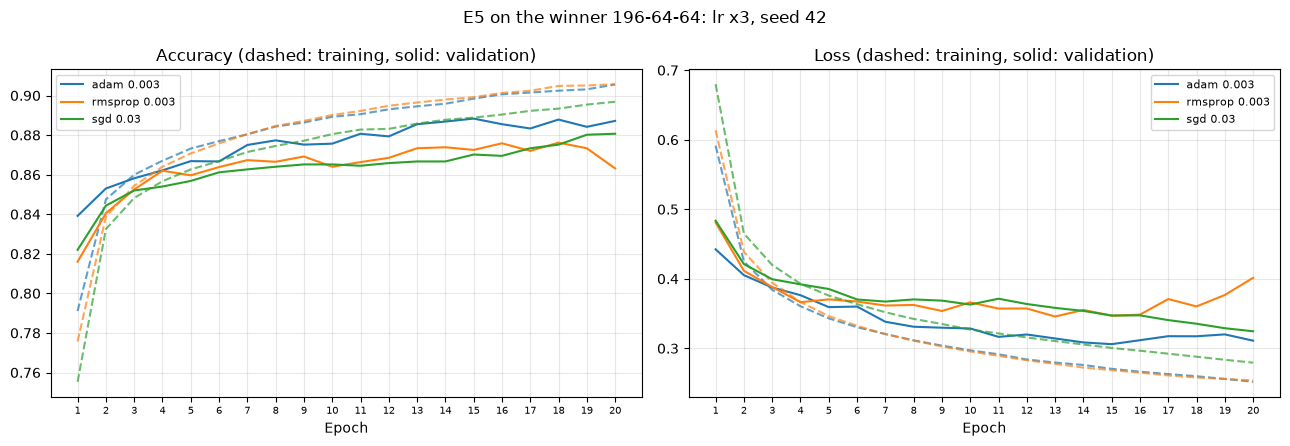

In [38]:
# Experiment 5, winner network 196-64-64 (E3): informative only, it does not change the winner.
e5_win_table, e5_win_hists = run_e5_full(196, [64, 64], base_fmt='E3-area196-64x2-s{seed}')
display(e5_win_table.round(4))
show_e5(e5_win_table, e5_win_hists, 'E5 on the winner 196-64-64')

adam 0.001 none: mean val 0.8834, passes: False


E5-area196-64-32-adam_0.001-drop0.1-s42: 15,018 params, train 0.8795, val 0.8880, 0.69 s/epoch


E5-area196-64-32-adam_0.001-drop0.1-s7: 15,018 params, train 0.8779, val 0.8830, 0.71 s/epoch


E5-area196-64-32-adam_0.001-drop0.1-s126: 15,018 params, train 0.8800, val 0.8830, 0.69 s/epoch


adam 0.001 drop0.1: mean val 0.8847, passes: False


E5-area196-64-32-adam_0.001-l1_1e-05-s42: 15,018 params, train 0.8890, val 0.8870, 0.58 s/epoch


... (48 outputs left out)

E5-area196-64-32-sgd_0.03-none-s7: 15,018 params, train 0.8945, val 0.8767, 0.51 s/epoch


E5-area196-64-32-sgd_0.03-none-s126: 15,018 params, train 0.8899, val 0.8805, 0.51 s/epoch


sgd 0.03 none: mean val 0.8802, passes: False


,optimizer,lr,reg,s42,s7,s126,mean,sd,train acc (history),train acc (eval),gap (history),gap (eval),passes
0,adam,0.001,none,0.8845,0.8810,0.8847,0.8834,0.0021,0.8914,NaN,0.0080,NaN,False
1,adam,0.001,drop0.1,0.8880,0.8830,0.8830,0.8847,0.0029,0.8791,0.8922,-0.0055,0.0075,False
2,adam,0.001,l1_1e-05,0.8870,0.8847,0.8808,0.8842,0.0031,0.8898,0.8905,0.0056,0.0064,False
3,adam,0.001,l2_0.0001,0.8808,0.8843,0.8823,0.8825,0.0018,0.8878,0.8896,0.0053,0.0071,False
4,rmsprop,0.001,none,0.8728,0.8790,0.8728,0.8749,0.0036,0.8903,0.8845,0.0155,0.0096,False
5,rmsprop,0.001,drop0.1,0.8742,0.8848,0.8783,0.8791,0.0054,0.8786,0.8904,-0.0005,0.0113,False
6,rmsprop,0.001,l1_1e-05,0.8732,0.8817,0.8695,0.8748,0.0062,0.8892,0.8826,0.0144,0.0078,False
7,rmsprop,0.001,l2_0.0001,0.8682,0.8837,0.8677,0.8732,0.0091,0.8870,0.8818,0.0138,0.0086,False
8,sgd,0.010,none,0.8803,0.8732,0.8770,0.8768,0.0036,0.8823,0.8834,0.0055,0.0066,False
9,sgd,0.010,drop0.1,0.8772,0.8762,0.8733,0.8756,0.0020,0.8652,0.8798,-0.0104,0.0043,False


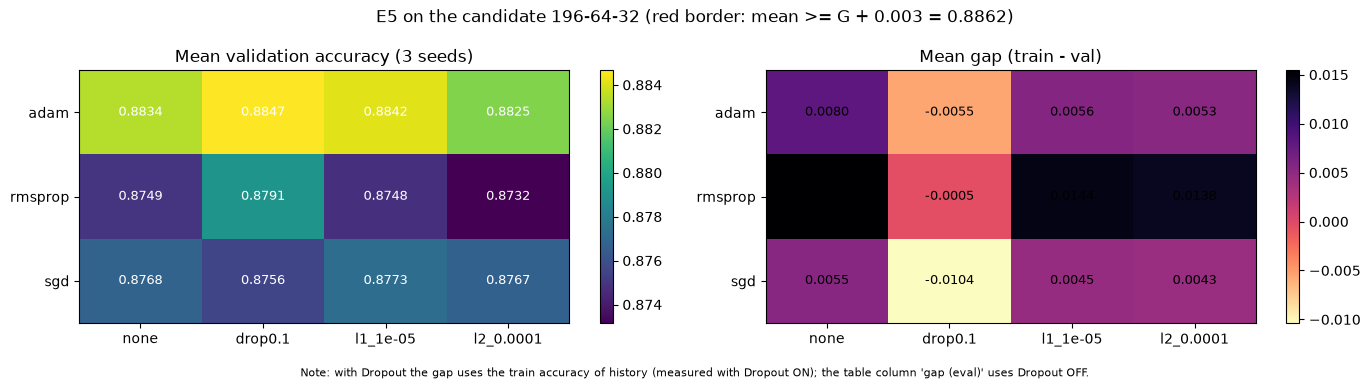

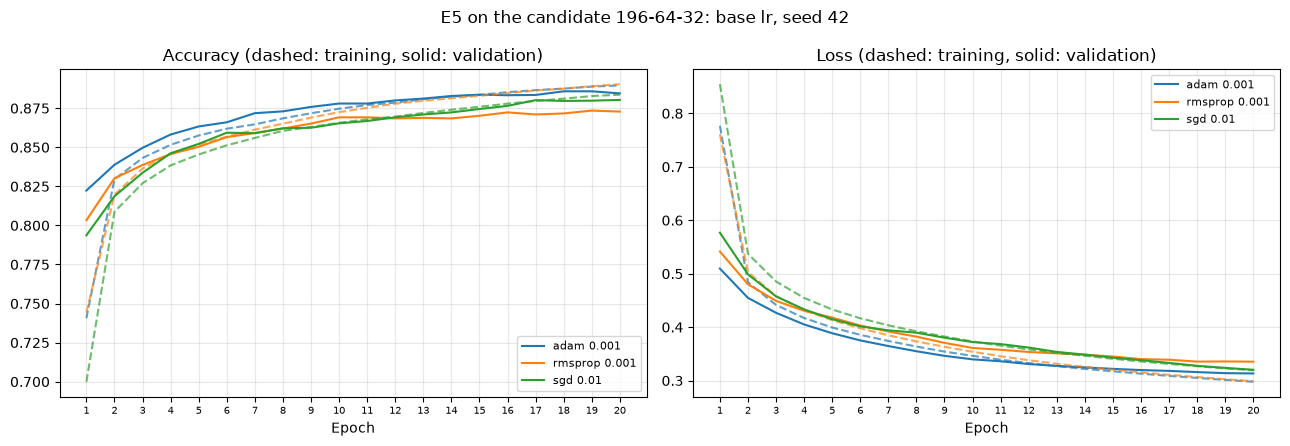

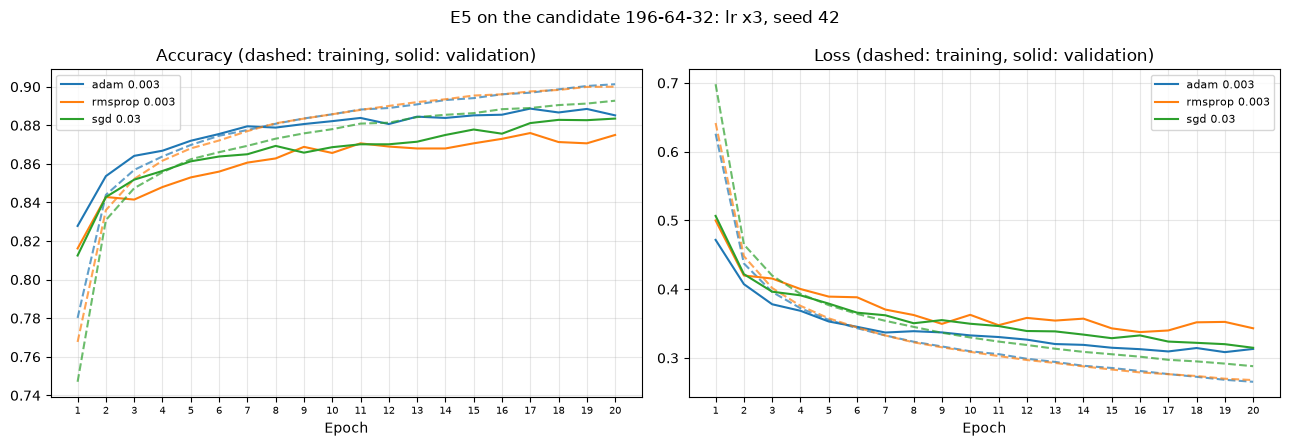

No combination rescues 196-64-32 (threshold G + 0.003 = 0.8862).


In [39]:
# Experiment 5, candidate network 196-64-32 (E3b, rule D8): does any training recipe make it pass?
# The network is written by hand on purpose: it is the D8 candidate of the ORIGINAL E5, chosen among the networks that
# existed when E5 was designed (E3, E3b, E4; E4b came later). Cell e5-d13-candidate recomputes it from `results`
# with D8_POOL_E5 and checks that it is this one.
e5_cand_table, e5_cand_hists = run_e5_full(196, [64, 32], base_fmt='E3b-area196-64-32-s{seed}')
display(e5_cand_table.round(4))
show_e5(e5_cand_table, e5_cand_hists, 'E5 on the candidate 196-64-32')

e5_rescue = decide_e5(e5_cand_table)
if e5_rescue is None:
    print(f"No combination rescues 196-64-32 (threshold G + 0.003 = {threshold:.4f}).")
else:
    print(f"Rescue: {e5_rescue['optimizer']} lr {e5_rescue['lr']:g}, reg {e5_rescue['reg']}, "
          f"mean val {e5_rescue['mean']:.4f} (threshold {threshold:.4f}).")

In [40]:
# Experiment 5, second rescue (the last one): rule D8 applied again, only if the candidate was rescued.
# The pool is that of the ORIGINAL E5 (E3, E3b, E4: the networks available when E5 was designed), so that a full run
# reproduces the original design even though E4b now runs earlier in the notebook. The D13 grid has its own cells below.
if e5_rescue is None:
    print('No rescue: the winner stays 196-64-64 and E5 ends.')
else:
    cand_params = mlp_params(196, [64, 32])      # parameters of the network just rescued (15,018)
    pool = d8_pool(D8_POOL_E5, cand_params)      # failed, 3 seeds, fewer parameters than the rescued network
    if pool.empty:
        print('No network with fewer parameters has the 3 seeds: no second candidate and E5 ends.')
    else:
        second, _ = d8_choose(pool)              # highest mean; tie: fewer parameters
        base2, params2, mean2 = second['base'], second['parameters'], second['mean val']
        print(f"Second candidate: {base2} ({params2:,} parameters), Adam mean {mean2:.4f}")
        method2, d2, hidden2 = arch_from_name(base2)
        assert mlp_params(d2, hidden2) == params2
        # Same grid as before, with prefix E5 and its own architecture tag
        e5_c2_table, e5_c2_hists = run_e5_full(d2, hidden2, base_fmt=base2 + '-s{seed}', method=method2)
        display(e5_c2_table.round(4))
        show_e5(e5_c2_table, e5_c2_hists, f"E5 on the second candidate {base2}")
        e5_rescue2 = decide_e5(e5_c2_table)
        if e5_rescue2 is None:
            print('No combination rescues the second candidate. E5 ends.')
        else:
            print(f"Second rescue: {e5_rescue2['optimizer']} lr {e5_rescue2['lr']:g}, reg {e5_rescue2['reg']}, "
                  f"mean val {e5_rescue2['mean']:.4f}. E5 ends (maximum two rescues).")


No rescue: the winner stays 196-64-64 and E5 ends.


#### Experiment 5, third candidate (D13): the grid on 196-48-48-48

This block applies the E5 grid to a third candidate. E4b did not find any winner, so the winner remains 196-64-64. However, E4b left 196-48-48-48 (14,650 parameters) at a difference of 1 hit in 18,000 from 196-64-32 (15,018): 0.883444 versus 0.883389. D13 applies D8 to the set of networks of E3, E3b, E4 and E4b; D8 chooses 196-48-48-48 by higher mean, and the tie-break by fewer parameters gives the same result. The next cell checks this in code. The E5 grid is applied to it with the identical D10 design as for the other two networks (same optimisers, regularisations, learning-rate block, seeds, rescue rule and tie-break) and the same E5 hypothesis; the Adam 1e-3 control is reused from E4b.

In [41]:
# D13, candidate: rule D8 (with its tie-break) applied IN CODE to the pool extended with E4b.
winner_params = mlp_params(196, [e3_choice] * 2)          # current winner 196-64-64: 17,418 parameters

# 1) Check: with the pool of the original E5 (E3, E3b, E4), D8 gives back the original candidate 196-64-32.
orig_cand, _ = d8_choose(d8_pool(D8_POOL_E5, winner_params))
if orig_cand['base'] != 'E3b-area196-64-32':   # visible warning, but do not stop the notebook
    print(f"WARNING: the original-pool D8 candidate is {orig_cand['base']}, not E3b-area196-64-32 "
          "(results differ from the original design).")
print(f"Original E5 pool (E3, E3b, E4): D8 candidate = {orig_cand['base']} ({orig_cand['parameters']:,} parameters), "
      f"mean {orig_cand['mean val']:.6f}")

# 2) D13: pool extended with E4b. Networks that FAIL (3-seed mean < G + 0.003), with fewer than 17,418 parameters.
pool = d8_pool(D8_POOL_D13, winner_params)
print(f"\nThreshold G + 0.003 = {threshold:.6f}. Failing networks with < {winner_params:,} parameters, 3 seeds (42, 7, 126),")
print("validation mean at full precision (best first):")
for _, r in pool.iterrows():
    h_r = arch_from_name(r['base'])
    print(f"  {net_label(h_r[1], h_r[2]):<18} {r['parameters']:>7,} parameters   mean val = {r['mean val']:.6f}   ({r['base']})")

d13_cand, d13_tie = d8_choose(pool)
d13_method, d13_d, d13_hidden = arch_from_name(d13_cand['base'])
d13_label = net_label(d13_d, d13_hidden)
d13_changed = d13_cand['base'] != orig_cand['base']
assert mlp_params(d13_d, d13_hidden) == d13_cand['parameters']
print(f"\nD13 candidate: {d13_label} ({d13_cand['parameters']:,} parameters), mean val = {d13_cand['mean val']:.6f}")
if d13_tie:
    print("Reason: exact tie in the highest mean (difference below the rounding tolerance); D8 tie-break = fewer parameters.")
else:
    second_best = pool['mean val'].iloc[1]
    print(f"Reason: strictly the highest mean (next network: {second_best:.6f}, difference {d13_cand['mean val'] - second_best:.6f}).")
if not d13_changed:
    print("The candidate does NOT change (it is still 196-64-32): the E5 grid of D13 is not run.")


Original E5 pool (E3, E3b, E4): D8 candidate = E3b-area196-64-32 (15,018 parameters), mean 0.883389

Threshold G + 0.003 = 0.886167. Failing networks with < 17,418 parameters, 3 seeds (42, 7, 126),
validation mean at full precision (best first):
  196-48-48-48        14,650 parameters   mean val = 0.883444   (E4b-area196-3L48)
  196-64-32           15,018 parameters   mean val = 0.883389   (E3b-area196-64-32)
  196-84              17,398 parameters   mean val = 0.882278   (E4-area196-1L84)
  196-54-54-54        17,128 parameters   mean val = 0.882167   (E4b-area196-3L54)
  196-40-40-40        11,570 parameters   mean val = 0.880889   (E4b-area196-3L40)
  196-40-40-40-40     13,210 parameters   mean val = 0.880389   (E4b-area196-4L40)
  196-48-48-48-48     17,002 parameters   mean val = 0.878556   (E4b-area196-4L48)
  196-32-32-32-32      9,802 parameters   mean val = 0.877611   (E4b-area196-4L32)

D13 candidate: 196-48-48-48 (14,650 parameters), mean val = 0.883444
Reason: strictly the

adam 0.001 none: mean val 0.8834, passes: False


E5c-area196-48-48-48-adam_0.001-drop0.1-s42: 14,650 params, train 0.8770, val 0.8812, 0.82 s/epoch


E5c-area196-48-48-48-adam_0.001-drop0.1-s7: 14,650 params, train 0.8761, val 0.8830, 0.81 s/epoch


E5c-area196-48-48-48-adam_0.001-drop0.1-s126: 14,650 params, train 0.8774, val 0.8798, 0.80 s/epoch


adam 0.001 drop0.1: mean val 0.8813, passes: False


E5c-area196-48-48-48-adam_0.001-l1_1e-05-s42: 14,650 params, train 0.8917, val 0.8835, 0.74 s/epoch


... (48 outputs left out)

E5c-area196-48-48-48-sgd_0.03-none-s7: 14,650 params, train 0.8939, val 0.8797, 0.60 s/epoch


E5c-area196-48-48-48-sgd_0.03-none-s126: 14,650 params, train 0.8906, val 0.8753, 0.66 s/epoch


sgd 0.03 none: mean val 0.8793, passes: False


,optimizer,lr,reg,s42,s7,s126,mean,sd,train acc (history),train acc (eval),gap (history),gap (eval),passes
0,adam,0.001,none,0.8862,0.8855,0.8787,0.8834,0.0042,0.8937,NaN,0.0102,NaN,False
1,adam,0.001,drop0.1,0.8812,0.8830,0.8798,0.8813,0.0016,0.8768,0.8901,-0.0045,0.0088,False
2,adam,0.001,l1_1e-05,0.8835,0.8853,0.8802,0.8830,0.0026,0.8919,0.8932,0.0089,0.0102,False
3,adam,0.001,l2_0.0001,0.8868,0.8820,0.8838,0.8842,0.0024,0.8903,0.8916,0.0061,0.0074,False
4,rmsprop,0.001,none,0.8745,0.8807,0.8675,0.8742,0.0066,0.8910,0.8857,0.0167,0.0115,False
5,rmsprop,0.001,drop0.1,0.8738,0.8785,0.8808,0.8777,0.0036,0.8742,0.8858,-0.0035,0.0081,False
6,rmsprop,0.001,l1_1e-05,0.8693,0.8752,0.8657,0.8701,0.0048,0.8905,0.8816,0.0204,0.0115,False
7,rmsprop,0.001,l2_0.0001,0.8722,0.8757,0.8600,0.8693,0.0082,0.8890,0.8783,0.0197,0.0091,False
8,sgd,0.010,none,0.8815,0.8808,0.8760,0.8794,0.0030,0.8848,0.8862,0.0054,0.0068,False
9,sgd,0.010,drop0.1,0.8790,0.8757,0.8733,0.8760,0.0028,0.8620,0.8805,-0.0140,0.0045,False


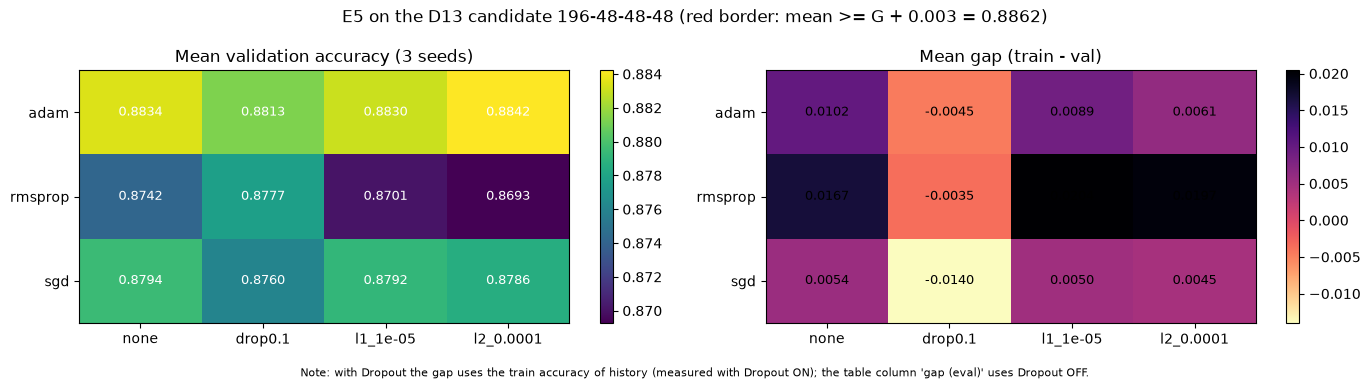

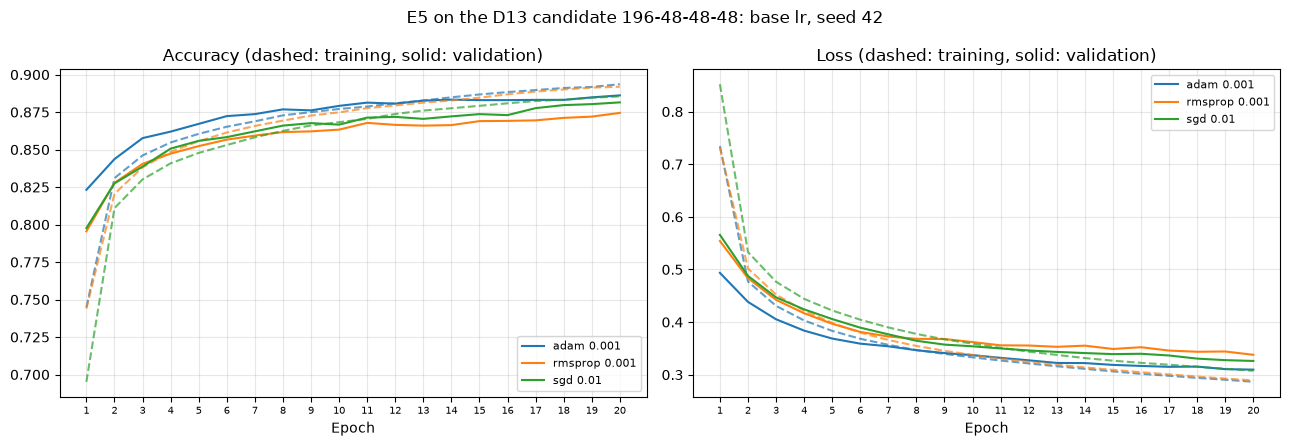

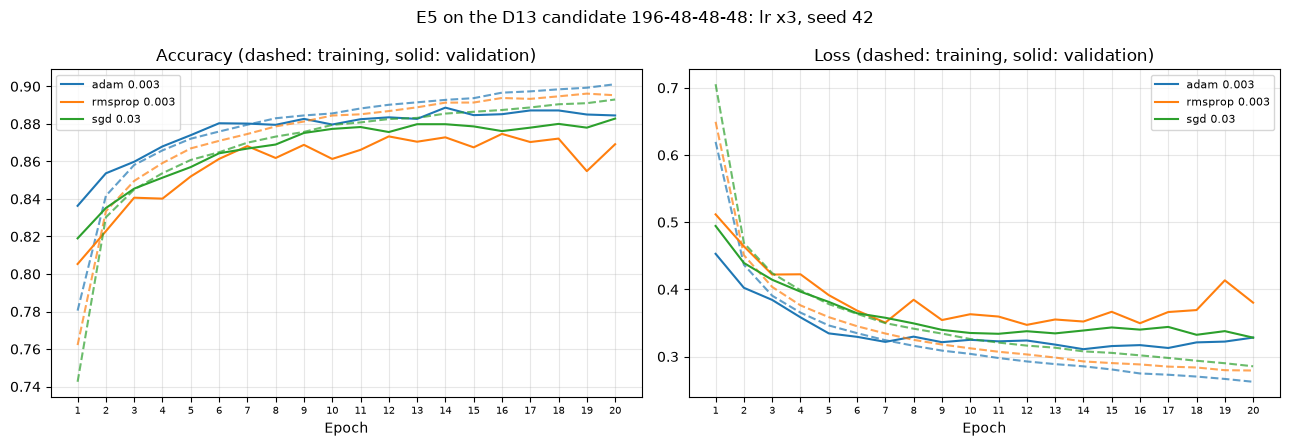

In [42]:
# D13: the E5 grid (D10, identical) on the new candidate. Control (Adam 1e-3, no regularisation) reused from E4b.
if not d13_changed:
    print('Candidate unchanged: nothing to run.')
else:
    d13_table, d13_hists = run_e5_full(d13_d, d13_hidden, base_fmt=d13_cand['base'] + '-s{seed}',
                                       method=d13_method, prefix='E5c')
    display(d13_table.round(4))
    show_e5(d13_table, d13_hists, f'E5 on the D13 candidate {d13_label}')


In [43]:
# D13, decision (rule D10): does any recipe rescue the new candidate?
if not d13_changed:
    print('Candidate unchanged: no D13 decision.')
else:
    d13_rescue = decide_e5(d13_table)
    if d13_rescue is None:
        print(f"No combination rescues {d13_label} (threshold G + 0.003 = {threshold:.4f}).")
        print('No rescue: the winner stays 196-64-64 and E5 ends.')
    else:
        print(f"Rescue: {d13_rescue['optimizer']} lr {d13_rescue['lr']:g}, reg {d13_rescue['reg']}, "
              f"mean val {d13_rescue['mean']:.4f} (threshold {threshold:.4f}). {d13_label} becomes the winner.")
        # Last possible rescue (D10: at most 2 in total): D8 once more, pool = networks with fewer parameters than the new winner
        pool2 = d8_pool(D8_POOL_D13, int(d13_cand['parameters']))
        if pool2.empty:
            print('No network with fewer parameters has the 3 seeds: no further candidate and E5 ends.')
        else:
            cand3, _ = d8_choose(pool2)
            method3, d3, hidden3 = arch_from_name(cand3['base'])
            label3 = net_label(d3, hidden3)
            print(f"Next candidate (D8): {label3} ({cand3['parameters']:,} parameters), Adam mean {cand3['mean val']:.6f}")
            d13_table2, d13_hists2 = run_e5_full(d3, hidden3, base_fmt=cand3['base'] + '-s{seed}', method=method3, prefix='E5d')
            display(d13_table2.round(4))
            show_e5(d13_table2, d13_hists2, f'E5 on the next candidate {label3}')
            d13_rescue2 = decide_e5(d13_table2)
            if d13_rescue2 is None:
                print(f'No combination rescues {label3}. E5 ends.')
            else:
                print(f"Last rescue: {d13_rescue2['optimizer']} lr {d13_rescue2['lr']:g}, reg {d13_rescue2['reg']}, "
                      f"mean val {d13_rescue2['mean']:.4f}. E5 ends (maximum two rescues).")


No combination rescues 196-48-48-48 (threshold G + 0.003 = 0.8862).
No rescue: the winner stays 196-64-64 and E5 ends.


In [44]:
# Experiment 5, SGD in epochs 15-20 (seed 42): is SGD still improving when training stops? (I8)
# Read from the saved seed-42 histories, nothing is re-trained.
sgd_sources = [('196-64-64', 'e5_win_hists'), ('196-64-32', 'e5_cand_hists'), ('196-48-48-48', 'd13_hists')]
for label, var in sgd_sources:
    hists = globals().get(var)
    if hists is None:
        print(f"{label}: history dict `{var}` does not exist (not run).")
        continue
    for lr in [1e-2, 3e-2]:
        h = hists.get(('sgd', lr, 'none'))
        if h is None:
            print(f"{label}, SGD {lr:g}, no regularisation: history missing.")
            continue
        va = h.history['val_accuracy']
        print(f"{label}, SGD {lr:g}, no reg, val acc epochs 15-20: " + ' '.join(f"{v:.4f}" for v in va[14:20])
              + f"   (change 15 -> 20: {va[19] - va[14]:+.4f})")


196-64-64, SGD 0.01, no reg, val acc epochs 15-20: 0.8698 0.8713 0.8742 0.8768 0.8768 0.8760   (change 15 -> 20: +0.0062)
196-64-64, SGD 0.03, no reg, val acc epochs 15-20: 0.8702 0.8695 0.8733 0.8752 0.8802 0.8807   (change 15 -> 20: +0.0105)
196-64-32, SGD 0.01, no reg, val acc epochs 15-20: 0.8745 0.8765 0.8802 0.8797 0.8798 0.8803   (change 15 -> 20: +0.0058)
196-64-32, SGD 0.03, no reg, val acc epochs 15-20: 0.8778 0.8757 0.8812 0.8828 0.8827 0.8835   (change 15 -> 20: +0.0057)
196-48-48-48, SGD 0.01, no reg, val acc epochs 15-20: 0.8737 0.8730 0.8777 0.8797 0.8803 0.8815   (change 15 -> 20: +0.0078)
196-48-48-48, SGD 0.03, no reg, val acc epochs 15-20: 0.8787 0.8762 0.8780 0.8800 0.8780 0.8828   (change 15 -> 20: +0.0042)


### Conclusions of Experiment 5

**Candidates.** In addition to the original candidate (196-64-32, which D8 chooses among E3, E3b and E4), we evaluated a second candidate. D13 extends the protocol; applying D8 to the extended set, the candidate is 196-48-48-48. We applied the E5 hypothesis unchanged and the D10 grid without modifying it, and kept the original E5 on 196-64-64 (winner) and 196-64-32. Between the two candidates there is a difference of 1 hit in 18,000 (0.883444 versus 0.883389); D8 chooses 196-48-48-48 by higher mean; the tie-break by fewer parameters would have given the same result.

3-seed validation mean at epoch 20 (threshold G + 0.003 = 0.8862):

| Optimiser | lr | Regularisation | 196-64-64 (17,418) | 196-64-32 (15,018) | 196-48-48-48 (14,650) |
|---|---|---|---|---|---|
| Adam | 1e-3 | none (control) | **0.8873** | 0.8834 | 0.8834 |
| Adam | 1e-3 | Dropout 0.1 | 0.8863 | **0.8847** | 0.8813 |
| Adam | 1e-3 | L1 1e-5 | 0.8841 | 0.8842 | 0.8830 |
| Adam | 1e-3 | L2 1e-4 | 0.8830 | 0.8825 | **0.8842** |
| RMSprop | 1e-3 | none | 0.8802 | 0.8749 | 0.8742 |
| RMSprop | 1e-3 | Dropout 0.1 | 0.8804 | 0.8791 | 0.8777 |
| RMSprop | 1e-3 | L1 1e-5 | 0.8788 | 0.8748 | 0.8701 |
| RMSprop | 1e-3 | L2 1e-4 | 0.8761 | 0.8732 | 0.8693 |
| SGD + momentum | 1e-2 | none | 0.8775 | 0.8768 | 0.8794 |
| SGD + momentum | 1e-2 | Dropout 0.1 | 0.8757 | 0.8756 | 0.8760 |
| SGD + momentum | 1e-2 | L1 1e-5 | 0.8791 | 0.8773 | 0.8792 |
| SGD + momentum | 1e-2 | L2 1e-4 | 0.8766 | 0.8767 | 0.8786 |
| Adam | 3e-3 | none | 0.8853 | 0.8821 | 0.8828 |
| RMSprop | 3e-3 | none | 0.8728 | 0.8729 | 0.8691 |
| SGD + momentum | 3e-2 | none | 0.8812 | 0.8802 | 0.8793 |

**Result.** No combination rescues either of the two candidates. In 196-64-32, the best is Adam with Dropout (0.8847), 0.0015 from the threshold. In 196-48-48-48, the best is Adam with L2 (0.8842), 0.0019 away. Therefore, the winner remains 196-64-64 (17,418 parameters, mean 0.8873) and E5 ends. In cost-benefit terms, a rescue would have saved 2,400 parameters (13.8 %) with 196-64-32 or 2,768 (15.9 %) with 196-48-48-48. However, no training recipe compensates for the lost capacity. In the winner the grid is for information only: Adam with Dropout also exceeds the threshold (0.8863), but it has the same parameters and a mean 0.0010 lower than the control. Moreover, with 28 recipe-and-candidate combinations (14 per candidate, not counting the reused control), the best mean tends to be overestimated, because choosing the maximum among many noisy means favours the one that was lucky with the seeds. It did not affect any decision, because there was no rescue.

**Contrast of each prediction with the three networks**

| Prediction | 196-64-64 | 196-64-32 | 196-48-48-48 | Verdict |
|---|---|---|---|---|
| Regularisation helps little or worsens | Holds | Holds, with the partial exception of RMSprop + Dropout | Holds, with the same partial exception | Confirmed in essence |
| The effect is more negative in the smallest network | – (mean −0.0017) | No: mean +0.0003 | No: mean −0.0013 | Not supported (differences within noise) |
| L1 is the most harmful | It is not the worst with any optimiser | It is not the worst with any optimiser | It is not the worst with any optimiser | Not supported (differences within noise) |
| Adam and RMSprop end above SGD | Both | Only Adam | Only Adam | Confirmed for Adam; for RMSprop it does not hold in the candidates |
| The SGD validation keeps rising at epoch 20 (seed 42) | Yes with 3e-2; with 1e-2 it flattens at the end | Rises from epoch 15 to 20, but almost flat since 17 | Yes, although with 3e-2 not monotonically | Weakly supported (one seed, non-monotonic rise) |
| Raising the lr benefits SGD more | Yes (+0.0037, sd 0.0054) | Yes (+0.0034, sd 0.0034) | Nobody gains; SGD is the one that loses least (−0.0001) | Supported in the two-layer networks, with gains of the order of the noise; not in the three-layer one |
| If there is a rescue, it will be through the optimiser or the lr | No rescue | No rescue | No rescue | Not evaluable |

*Regularisation.* In the winner, the nine regularised combinations are on average 0.0017 below their unregularised version. All get worse except two, with improvements within the noise: RMSprop with Dropout (+0.0002) and SGD with L1 (+0.0016, versus a deviation of 0.0029 in both SGD variants). This agrees with the expectation. In the candidates the result is not clearly negative: the mean of the nine differences is +0.0003 in 196-64-32 and −0.0013 in 196-48-48-48 (our own calculation from the tables). Consequently, the second prediction is not supported: we do not observe that the smaller network suffers more from regularisation. However, each individual difference is of the order of the deviation between seeds, so we cannot state the opposite either. The only improvement that repeats is RMSprop with Dropout (+0.0042 in 196-64-32, +0.0035 in 196-48-48-48 and +0.0002 in the winner). These gains are of the order of the deviation between seeds of unregularised RMSprop (0.0036 and 0.0066). Moreover, RMSprop starts from the worst control of the grid and not even with Dropout does it reach Adam. Therefore, we consider it a partial exception and not a clear improvement.

*The best regularisation in 196-48-48-48 is L2, not Dropout.* In 196-64-32 Dropout won (0.8847) and in 196-48-48-48 L2 wins (0.8842). However, neither of the two differences with respect to its control is reliable. Per seed, Adam with L2 in 196-48-48-48 changes +0.0006, −0.0035 and +0.0051 (seeds 42, 7 and 126). The improvement of the mean is mostly due to seed 126, in which the control had its worst value (0.8787), and the deviation of the control is 0.0042. Likewise, Adam with Dropout in 196-64-32 changes +0.0035, +0.0020 and −0.0017. With mixed signs and differences of 0.08 and 0.13 pp (0.0008 and 0.0013), smaller than the deviation of each control (0.0042 and 0.0021), we cannot state that one network "prefers" L2 and the other Dropout. With SGD, Dropout lowers the train accuracy measured without Dropout in the three networks (0.8802, 0.8798 and 0.8805, versus 0.8831, 0.8834 and 0.8862 without regularisation). With Adam this only happens in 196-48-48-48 (0.8901, below L1 with 0.8932 and L2 with 0.8916), and with RMSprop it happens in none of the networks. In 196-48-48-48, moreover, Dropout worsens validation with Adam (−0.0021) and with SGD (−0.0034). A plausible explanation is that switching off 10 % of the neurons in three layers of only 48 removes more capacity than in a network of two wider layers. We have not measured this directly, and these drops are of the order of the deviation of the controls (0.0042 and 0.0030).

*L1.* L1 is not the worst regularisation in any of the nine optimiser-and-network pairs. With Adam and RMSprop the worst is usually L2; with SGD the worst is Dropout, and with SGD, L1 is even the best option in the winner (+0.0016 versus unregularised SGD). However, several of these distances are small (for example, 0.0008 between L1 and L2 with RMSprop in 196-48-48-48) and fall within the noise between seeds. Therefore, the prediction is not supported, without our being able to state that L1 is the least harmful. A plausible explanation is that L1 1e-5 is a weak penalty compared with L2 1e-4 in these networks: its train accuracy barely drops with respect to the control (0.8940 versus 0.8958 in the winner). In that case, the comparison says more about the chosen strengths than about the norm. We have not counted how many weights end up at zero, so we cannot verify the idea of "pushing weights to zero".

*Optimisers.* Adam 1e-3 is the best optimiser without regularisation in the three networks, with an advantage over SGD of 0.0098 in the winner, 0.0066 in 196-64-32 and 0.0040 in 196-48-48-48. In the latter the advantage is of the order of the deviation of the control (0.0042), although Adam beats SGD in the three seeds. SGD also has the lowest train accuracy of the three optimisers (0.8826, 0.8823 and 0.8848, versus 0.8958, 0.8914 and 0.8937 for Adam). This is consistent with slower convergence: in 20 epochs, the network fits the data less. The cell for epochs 15 to 20 (seed 42) allows us to test the sub-prediction that the SGD validation would keep rising at epoch 20. In the six cases (two learning rates and three networks), the validation is higher at epoch 20 than at epoch 15, between +0.0042 and +0.0105. However, the rise is not monotonic. With 1e-2, in 196-64-64 the last three epochs give 0.8768, 0.8768 and 0.8760, and in 196-64-32 the curve is almost flat since epoch 17 (from 0.8802 to 0.8803). With 3e-2, in 196-48-48-48 it drops from 0.8800 to 0.8780 before rising to 0.8828. Consequently, the sub-prediction receives weak support: several curves are still rising, but with a single seed and oscillations of this size we cannot estimate how much SGD would gain with more epochs. RMSprop, in contrast, does not behave as we predicted. Its train accuracy is almost that of Adam (0.8955, 0.8903 and 0.8910), but its validation is the lowest, with the largest gap (from 0.0153 to 0.0167) and a high deviation between seeds. Likewise, it is the only optimiser whose train accuracy evaluated at the end of epoch 20 falls clearly below the one recorded during that epoch (for example, 0.8901 versus 0.8955 in the winner). A plausible explanation is that, without momentum or bias correction, RMSprop ends at an unstable point of the trajectory, with final weights worse than the average of the last epoch. Consequently, its deficit does not seem to be one of convergence speed, but of stability of the last iterate. This is a conjecture that we have not verified.

*Learning rate ×3.* With a learning rate three times larger, SGD gains +0.0037 in the winner and +0.0034 in 196-64-32, whereas Adam loses 0.0020 and 0.0013 and RMSprop 0.0074 and 0.0020. The gains of SGD are of the order of its deviation between seeds with 3e-2 (0.0054 and 0.0034), so, on average, they do not clearly exceed the noise. However, the improvement repeats in the three seeds of both networks (+0.0047, +0.0060 and +0.0003 in the winner; +0.0032, +0.0035 and +0.0035 in 196-64-32; our own calculation). Therefore, the prediction is supported in the two-layer networks, with caution, and fits with SGD being limited by speed. D13 qualifies it: in 196-48-48-48, SGD with 3e-2 stays the same (−0.0001), although its train accuracy rises from 0.8848 to 0.8925 and the gap goes from 0.0054 to 0.0132. SGD is still the one that loses least (Adam −0.0006 and RMSprop −0.0051), but it gains nothing. With Adam 3e-3 something similar happens in the three networks: the train accuracy exceeds 0.90 (0.9059 in the winner) and the gap doubles (0.0207 versus 0.0085), but the validation drops. Therefore, these networks can fit the training set more than they do with Adam 1e-3, but that extra fit does not translate into generalisation, which qualifies the idea that the only problem is capacity. The gap with Adam 1e-3 remains small (from 0.0080 to 0.0102, versus 0.0568 for the reference).

*Contrast with E4b.* In E4b we attributed the worse result of the three- and four-layer networks to their fitting the training set better and generalising worse (gap of 0.0148 in 196-54-54-54 and of 0.0185 in 196-48-48-48-48). If that overfitting reading were correct, regularisation should help the deep network of E5. However, in 196-48-48-48, which has the largest gap of the three E5 networks (0.0102), regularisation does not help: with Adam, Dropout changes the mean by −0.0021, L2 by +0.0008 and L1 by −0.0004, all within the noise. There are two explanations compatible with the data: either the overfitting reading of E4b is weak, or the chosen strengths (Dropout 0.1, L2 1e-4 and L1 1e-5) were too mild to correct it. With these experiments we cannot distinguish between them. Moreover, the contrast is indirect: 196-48-48-48 has a smaller gap than the two E4b networks cited, to which we did not apply the grid.

*Rescue through optimiser or lr.* There was no rescue, so this prediction cannot be evaluated. Even so, in the two candidates the combination closest to the threshold is a regularisation one (Adam with Dropout and Adam with L2), not an optimiser or lr one. Since their advantages over the control fall within the noise between seeds, we do not interpret this as evidence against.

**Why training does not allow the network to be shrunk.** With Adam 1e-3, the three networks have a small gap compared with the reference: they are low-capacity networks that barely overfit. Consequently, Dropout, L1 and L2 add a restriction to a network that lacks capacity, not one that has too much. In the winner all get worse except two, with improvements within the noise, and in the candidates the best they achieve is to stay on a par with the control, also within the noise. Changing the optimiser does not help either: Adam was already the best option, SGD converges more slowly and RMSprop seems unstable. Raising the lr makes the network fit the training set more, but the validation does not improve. None of these levers changes the number of parameters or the structure of the first layer, where most of the weights are. The difference between 196-64-64 and the candidates is one of capacity (0.0039 in the validation mean), and E5 does not recover it.

**Limitations.** We compare the optimisers with different learning rates (Adam and RMSprop with 1e-3, SGD with 1e-2), so part of their differences may be due to the lr and not to the optimiser; the ×3 block only adds one more value per optimiser. We test a single strength of each regularisation. The E5 curves are only shown for the unregularised variants (seed 42), so for the regularised variants we only know the final value. Moreover, we use three seeds and 20 fixed epochs, and all decisions are made on validation.

**Decision.** We keep Adam 1e-3, without regularisation, and 196-64-64 (17,418 parameters, mean 0.8873) as the final model for section 8. No rescues remain pending, so E5 ends here.

---

## 7. Accuracy Against Parameters

Final validation accuracy (epoch 20) of the models in `results` against their number of parameters, with a logarithmic x axis. Only validation data is used in this section.

How to read the plot:

- **Colour and marker** identify the experiment (E1 to E5c). The black diamond is the reference (512-512, seed 42) and the gold ring marks the final model 196-64-64.
- **Filled marker with a vertical bar**: a configuration trained with the three search seeds (42, 7 and 126). The marker is the **mean** and the bar goes from the **minimum to the maximum** of the three seeds.
- **Hollow marker**: a configuration trained only with seed 42 (a screening run), so it has no bar.
- **Small crosses** (E5, E5c, E5d): the optimiser and regularisation recipes of Experiment 5. Each one has the same parameters as the network it was applied to, so they stack vertically above that network; each cross is a 3-seed mean. The Adam 1e-3 controls without regularisation are the E3, E3b and E4b points.
- **Horizontal lines**: `G` (reference final validation accuracy minus one point) and the search threshold `G + 0.003`.

The table below the plot lists every recorded model; the column `mean val (3 seeds)` is filled only for configurations that have three seeds.

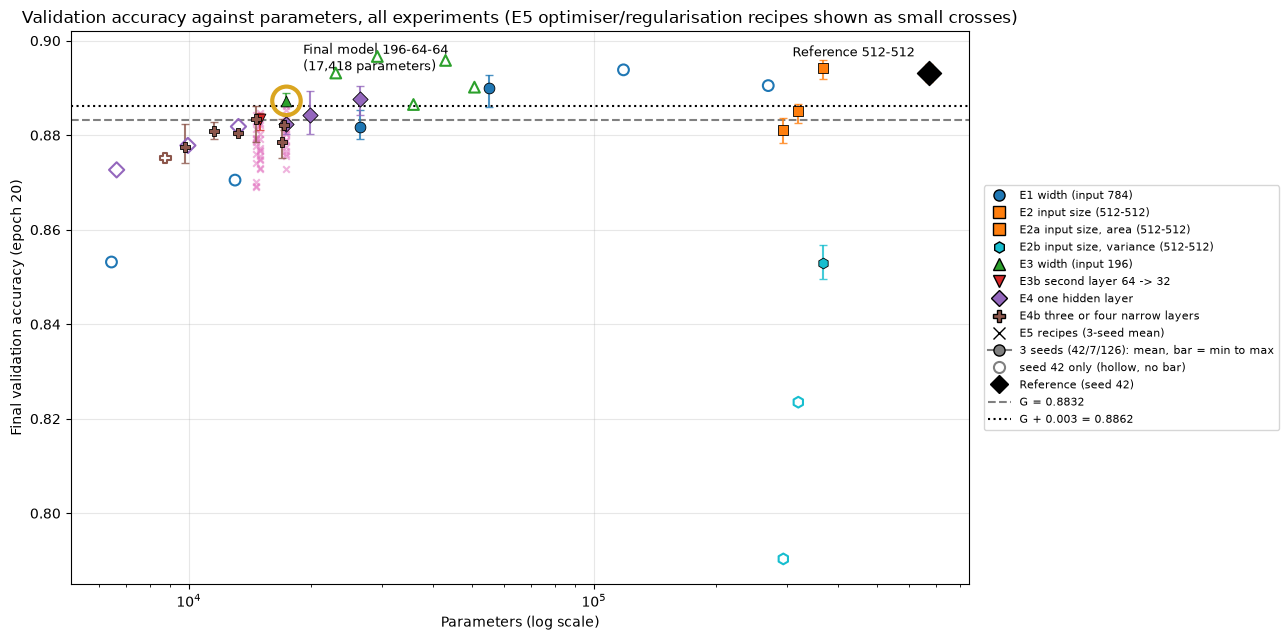

195 models recorded; 60 configurations have three or more seeds.


,model,experiment,parameters,seed,final val acc,final train acc,mean val (3 seeds)
0,Reference,Reference,669706,42,0.893167,0.950000,0.893111
1,E1-784-8x2-s42,E1,6442,42,0.853167,0.861796,NaN
2,E1-784-16x2-s42,E1,13002,42,0.870500,0.883204,NaN
3,E1-784-32x2-s126,E1,26506,126,0.880833,0.904519,0.881778
4,E1-784-32x2-s42,E1,26506,42,0.885333,0.902630,0.881778
5,E1-784-32x2-s7,E1,26506,7,0.879167,0.902870,0.881778
6,E1-784-64x2-s126,E1,55050,126,0.891167,0.923352,0.889945
7,E1-784-64x2-s42,E1,55050,42,0.892667,0.920759,0.889945
8,E1-784-64x2-s7,E1,55050,7,0.886000,0.925148,0.889945
9,E1-784-128x2-s42,E1,118282,42,0.893833,0.935111,NaN


In [49]:
# Section 7: results table and accuracy-against-parameters plot. Validation only: the test column of `results` is
# deliberately left out here.
from matplotlib.lines import Line2D   # proxy artists for the legend
EXP_ORDER = ['Reference', 'E1', 'E2', 'E2a', 'E2b', 'E3', 'E3b', 'E4', 'E4b', 'E5', 'E5c', 'E5d', 'Lean']

def models_table(res):
    """One row per recorded model, with experiment, seed and the 3-seed mean of its configuration (if any)."""
    df = pd.DataFrame(res)
    df['experiment'] = df['model'].str.split('-').str[0]            # 'Reference', 'E1', 'E3b', 'E5c', ...
    df['seed'] = pd.to_numeric(df['model'].str.extract(r'-s(\d+)$')[0])
    df.loc[df['model'] == 'Reference', 'seed'] = 42                  # the reference is the seed-42 run of 784-512-512
    # `config` = the model name without its seed. The reference IS the seed-42 run of the 784-512-512 network;
    # seeds 7 and 126 of that network are recorded as 'E2-full784-512x2-s7/s126', so the reference joins that
    # configuration to get its 3-seed mean.
    df['config'] = df['model'].str.replace(r'-s\d+$', '', regex=True)
    df.loc[df['model'] == 'Reference', 'config'] = 'E2-full784-512x2'
    df['seed'] = df['seed'].astype('Int64')
    assert not df.duplicated(['config', 'seed']).any(), 'duplicate (configuration, seed): a cell was re-run?'
    n_seeds = df.groupby('config')['seed'].transform('nunique')
    mean3 = df.groupby('config')['final_val_accuracy'].transform('mean')
    df['mean val (3 seeds)'] = mean3.where(n_seeds >= 3)
    return df

def config_summary(df):
    """One row per configuration: parameters, number of seeds, mean / min / max of the final validation accuracy."""
    cfg = df.groupby('config').agg(parameters=('parameters', 'first'), n_seeds=('seed', 'nunique'),
                                   mean=('final_val_accuracy', 'mean'), lo=('final_val_accuracy', 'min'),
                                   hi=('final_val_accuracy', 'max'))
    # accuracy of the seed-42 run (the one drawn, hollow, for configurations without three seeds)
    cfg['val42'] = df[df['seed'] == 42].groupby('config')['final_val_accuracy'].first()
    cfg['experiment'] = cfg.index.str.split('-').str[0]
    return cfg

EXP_STYLE = {   # experiment -> (marker, colour, legend text)
    'E1': ('o', 'C0', 'E1 width (input 784)'), 'E2': ('s', 'C1', 'E2 input size (512-512)'),
    'E2a': ('s', 'C1', 'E2a input size, area (512-512)'), 'E2b': ('h', 'C9', 'E2b input size, variance (512-512)'),
    'E3': ('^', 'C2', 'E3 width (input 196)'), 'E3b': ('v', 'C3', 'E3b second layer 64 -> 32'),
    'E4': ('D', 'C4', 'E4 one hidden layer'), 'E4b': ('P', 'C5', 'E4b three or four narrow layers'),
    'E5': ('x', 'C6', 'E5 recipes (3-seed mean)'), 'E5c': ('x', 'C6', None), 'E5d': ('x', 'C6', None),
    'Lean': ('*', 'gold', 'Lean (final model, seeds 1/2/3)')}

def plot_frontier(df):
    """Validation accuracy against parameters (log x). Filled + bar: 3 seeds (mean, min-max); hollow: seed 42 only."""
    cfg = config_summary(df)
    fig, ax = plt.subplots(figsize=(13, 6.5))
    for exp, (marker, color, _) in EXP_STYLE.items():
        g = cfg[cfg['experiment'] == exp]
        if g.empty:
            continue
        if exp.startswith('E5'):
            # Recipes of E5: same parameters as their network, so they are small and faint (they stack vertically).
            ax.scatter(g['parameters'], g['mean'], marker=marker, s=22, color=color, alpha=0.55, zorder=2)
            continue
        three, one = g[g['n_seeds'] >= 3], g[g['n_seeds'] < 3]
        ax.errorbar(three['parameters'], three['mean'], yerr=[three['mean'] - three['lo'], three['hi'] - three['mean']],
                    fmt='none', ecolor=color, capsize=3, alpha=0.8, zorder=3)
        ax.scatter(three['parameters'], three['mean'], marker=marker, s=60, color=color,
                   edgecolors='black', linewidths=0.6, zorder=4)
        ax.scatter(one['parameters'], one['val42'], marker=marker, s=60, facecolors='none',
                   edgecolors=color, linewidths=1.5, zorder=4)
    # Reference (seed 42) and final model (its 3-seed validation mean, search seeds), highlighted
    ref = df[df['model'] == 'Reference'].iloc[0]
    ax.scatter([ref['parameters']], [ref['final_val_accuracy']], marker='D', s=150, color='black', zorder=6)
    ax.annotate('Reference 512-512', (ref['parameters'], ref['final_val_accuracy']),
                textcoords='offset points', xytext=(-10, 12), ha='right', fontsize=9)
    fin = cfg.loc['E3-area196-64x2']
    ax.scatter([fin['parameters']], [fin['mean']], marker='o', s=420, facecolors='none', edgecolors='goldenrod',
               linewidths=3, zorder=5)
    ax.annotate('Final model 196-64-64\n(17,418 parameters)', (fin['parameters'], fin['mean']),
                textcoords='offset points', xytext=(12, 22), fontsize=9)
    ax.axhline(G, linestyle='--', color='gray', label=f'G = {G:.4f}')
    ax.axhline(threshold, linestyle=':', color='black', label=f'G + 0.003 = {threshold:.4f}')
    # Legend: one entry per experiment present, then the meaning of filled / hollow markers
    handles = [Line2D([], [], marker=m, color=c, ls='', markersize=8, markeredgecolor='black', label=t)
               for e, (m, c, t) in EXP_STYLE.items() if t and (cfg['experiment'] == e).any()]
    handles += [Line2D([], [], marker='o', color='gray', ls='-', markersize=8, markeredgecolor='black',
                       label='3 seeds (42/7/126): mean, bar = min to max'),
                Line2D([], [], marker='o', mfc='none', mec='gray', ls='', markersize=8, mew=1.5,
                       label='seed 42 only (hollow, no bar)'),
                Line2D([], [], marker='D', color='black', ls='', markersize=9, label='Reference (seed 42)'),
                Line2D([], [], color='gray', ls='--', label=f'G = {G:.4f}'),
                Line2D([], [], color='black', ls=':', label=f'G + 0.003 = {threshold:.4f}')]
    ax.legend(handles=handles, fontsize=8, loc='center left', bbox_to_anchor=(1.01, 0.5))
    ax.set_xscale('log')
    ax.set_xlabel('Parameters (log scale)')
    ax.set_ylabel('Final validation accuracy (epoch 20)')
    ax.set_title('Validation accuracy against parameters, all experiments '
                 '(E5 optimiser/regularisation recipes shown as small crosses)')
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# E5 recipes are included (small crosses, 3-seed means): they show that no recipe moves a network across the threshold.
models_df = models_table(results)
plot_frontier(models_df)

# Table of every model, grouped by experiment, then by parameters
table = models_df.assign(order=models_df['experiment'].map({e: i for i, e in enumerate(EXP_ORDER)}))
table = table.sort_values(['order', 'parameters', 'model'])[['model', 'experiment', 'parameters', 'seed',
                                                            'final_val_accuracy', 'final_train_accuracy',
                                                            'mean val (3 seeds)']]
table = table.rename(columns={'final_val_accuracy': 'final val acc', 'final_train_accuracy': 'final train acc'})
print(f"{len(table)} models recorded; {models_df.loc[models_df['mean val (3 seeds)'].notna(), 'config'].nunique()} "
      f"configurations have three or more seeds.")
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.width', 200,
                       'display.float_format', '{:.6f}'.format):
    display(table.reset_index(drop=True))

## 8. Your Lean Model

Write your final architecture in `build_lean_model`, train it with three different seeds and check it against your target. Use the same training settings in the three runs. If your lean model uses a smaller input, change this cell so that it builds, trains and evaluates the model on the resized arrays (for example `x_train_small.shape[1:]`, `x_train_small` and `x_test_small`).

### Pre-commitment for the final model

The final configuration was fixed on validation data, and the test set is used only for the reference model and for this pre-committed final model. It is hard-coded as `PRECOMMITTED` in the next cell, and the final model is built from it, not from the search output.

- **Configuration:** 196-64-64, input 14x14 obtained by area averaging (the same `area` pipeline as E3 and E5, d = 196), ReLU, Adam with learning rate 1e-3, no regularisation, 20 epochs, batch size 128, **17,418 parameters**. The decision comes from Experiment 5 (cell `e5-analysis`): no optimiser or regularisation recipe rescued either candidate network, so the winner of E3 stays as the final model. Its mean validation accuracy over the three search seeds (42, 7 and 126) was 0.8873.
- **Seeds:** the final model is trained with seeds **1, 2 and 3**. They were never used during the search (which used 42, 7 and 126), so the test result is not biased by selecting configurations on the same seeds.
- **Data:** a common practice is to merge the training and validation sets before the final test evaluation. To keep the comparison with the reference fair, we train the final model on exactly the same 54,000 training images as the reference (validation split kept aside).
- **Test set:** it is used only for the pre-committed final model, with these three seeds. If the target (`ref_test_acc - 0.01`) is not met, it is reported as it is, with no further tuning.

PRECOMMITTED matches the E5 decision of this run: 196-64-64, 17,418 parameters, no rescue.


Seed 1: final val accuracy 0.8870, test accuracy 0.8728, 11 s


Seed 2: final val accuracy 0.8838, test accuracy 0.8743, 11 s


Seed 3: final val accuracy 0.8858, test accuracy 0.8739, 11 s
Lean model: 196-64-64, parameters: 17,418
Mean test accuracy over three seeds: 0.8737 (sample standard deviation, ddof=1: 0.0008)
Mean final validation accuracy over seeds 1/2/3: 0.8856
Reference test accuracy: 0.8833. Target: 0.8733. Target met: True
PASS
Compression ratio: 38.4x


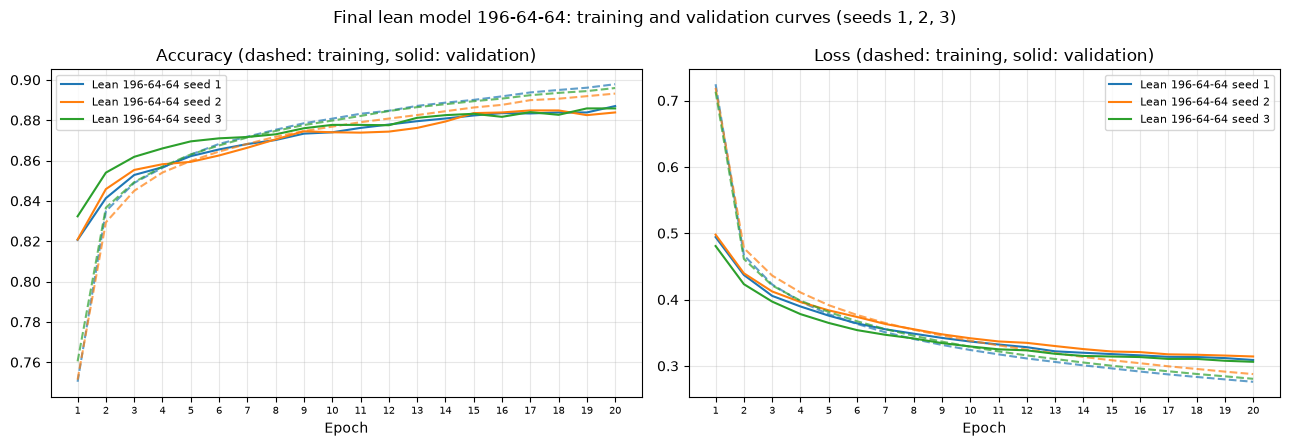

In [50]:
# Final lean model. The configuration was fixed on validation data (decision of Experiment 5) and is written here
# BEFORE any test evaluation of a candidate. It lives outside the LEAN_READY switch so that it is checked on every run.
PRECOMMITTED = {'d': 196, 'method': 'area', 'hidden_units': [64, 64], 'activation': 'relu', 'dropout': 0.0,
                'l1': 0.0, 'l2': 0.0, 'batchnorm': False, 'optimizer': 'adam', 'lr': 0.001, 'params': 17418}

def build_lean_model(input_dim, num_classes):
    """Same constructor and compile settings (incl. steps_per_execution) as every experiment."""
    return build_mlp(input_dim, PRECOMMITTED['hidden_units'], PRECOMMITTED['activation'], num_classes,
                     dropout=PRECOMMITTED['dropout'], l1=PRECOMMITTED['l1'], l2=PRECOMMITTED['l2'],
                     batchnorm=PRECOMMITTED['batchnorm'], optimizer=PRECOMMITTED['optimizer'],
                     lr=PRECOMMITTED['lr'])

# Consistency checks (environment independent): the committed parameters are the formula's and the real model's.
_check_model = build_lean_model(PRECOMMITTED['d'], num_classes)      # built only to count parameters, never trained
assert _check_model.count_params() == PRECOMMITTED['params'] == mlp_params(PRECOMMITTED['d'], PRECOMMITTED['hidden_units']) == 17418
assert (PRECOMMITTED['d'], PRECOMMITTED['hidden_units'], PRECOMMITTED['method']) == (196, [64, 64], 'area')
del _check_model
# Consistency with the E5 decision of THIS run (winner = E3 choice, no rescue in E5). Search results can differ on
# another machine, so a mismatch only warns: the final model is built from PRECOMMITTED either way.
e5_winner_hidden = [e3_choice] * 2
e5_no_rescue = (e5_rescue is None and globals().get('e5_rescue2') is None and globals().get('d13_rescue') is None)
if (E3_D, e5_winner_hidden) == (PRECOMMITTED['d'], PRECOMMITTED['hidden_units']) and e5_no_rescue \
        and mlp_params(E3_D, e5_winner_hidden) == PRECOMMITTED['params']:
    print('PRECOMMITTED matches the E5 decision of this run: 196-64-64, 17,418 parameters, no rescue.')
else:
    print('WARNING: the E5 decision of this run differs from PRECOMMITTED (floating point is hardware-dependent).')
    print('  E5 winner here:', (E3_D, e5_winner_hidden), ' PRECOMMITTED (used for the final model):', PRECOMMITTED)

# Guard: False until the student explicitly approved the single test evaluation (given; see Section 10).
LEAN_READY = True
if not LEAN_READY:
    print('LEAN_READY is False: Section 8 skipped (the test set is not used).')
else:
    # Same input pipeline as E3 and E5: `area` (tf.image.resize with method='area') to 14x14 = 196 values.
    assert PRECOMMITTED['method'] == 'area'
    s_lean = int(round(PRECOMMITTED['d'] ** 0.5))                     # 196 values -> 14 x 14
    assert s_lean * s_lean == PRECOMMITTED['d']
    x_tr, x_va, x_te = (flat(area(a, s_lean)) for a in (x_train, x_val, x_test))
    assert x_tr.shape[1] == x_va.shape[1] == x_te.shape[1] == PRECOMMITTED['d']
    assert len(x_tr) == 54000                                          # the same training images as the reference
    arch = f"{PRECOMMITTED['d']}-" + '-'.join(str(u) for u in PRECOMMITTED['hidden_units'])

    lean_test_accs, lean_val_accs, lean_histories = [], [], []
    for seed in [1, 2, 3]:                  # never used during the search (42, 7 and 126)
        keras.utils.set_random_seed(seed)   # right before building the model
        lean = build_lean_model(x_tr.shape[1], num_classes)
        assert lean.count_params() == PRECOMMITTED['params'], (lean.count_params(), PRECOMMITTED['params'])
        # Same protocol as the reference: 54,000 training images, validation split aside, 20 epochs, batch 128
        start = time.time()
        history = lean.fit(x_tr, y_train, validation_data=(x_va, y_val),
                           epochs=20, batch_size=128, verbose=0)
        seconds = time.time() - start
        _, acc = lean.evaluate(x_te, y_test, verbose=0)               # the only test evaluation of the final model
        lean_val_accs.append(history.history['val_accuracy'][-1])
        lean_test_accs.append(acc)
        lean_histories.append(history)
        record(f"Lean-{arch}-s{seed}", lean, history, acc)
        print(f"Seed {seed}: final val accuracy {lean_val_accs[-1]:.4f}, test accuracy {acc:.4f}, {seconds:.0f} s")

    lean_params = lean.count_params()
    mean_acc = float(np.mean(lean_test_accs))
    print(f"Lean model: {arch}, parameters: {lean_params:,}")
    print(f"Mean test accuracy over three seeds: {mean_acc:.4f} (sample standard deviation, ddof=1: {np.std(lean_test_accs, ddof=1):.4f})")
    print(f"Mean final validation accuracy over seeds 1/2/3: {np.mean(lean_val_accs):.4f}")
    print(f"Reference test accuracy: {ref_test_acc:.4f}. Target: {target_acc:.4f}. Target met: {at_least(mean_acc, target_acc)}")
    print('PASS' if at_least(mean_acc, target_acc) else 'DOES NOT PASS')
    print(f"Compression ratio: {ref_params / lean_params:.1f}x")

    # Training (dashed) and validation (solid) curves of the three final seeds
    plot_train_val(lean_histories, [f'Lean {arch} seed {s}' for s in [1, 2, 3]],
                   f'Final lean model {arch}: training and validation curves (seeds 1, 2, 3)')

## Reproducibility: local CPU vs Colab GPU

| Quantity | Local CPU (main run) | Colab GPU T4 |
|---|---|---|
| Reference test accuracy | 0.8833 | 0.8773 |
| Test target (reference − 0.01) | 0.8733 | 0.8673 |
| Reference final validation accuracy | 0.8932 | 0.8920 |
| G / decision threshold G + 0.003 | 0.8832 / 0.8862 | 0.8820 / 0.8850 |
| E1 choice | 784-64-64 (mean 0.8899) | 784-64-64 (mean 0.8903) |
| E2a choice (area input) | d = 196 (d = 100 mean 0.8851, fails) | d = 100 (mean 0.8871, passes) |
| E3 choice (d = 196) | 196-64-64, mean 0.8873 | 196-64-64, mean 0.8867 |
| E3b 196-64-32 | 0.8834, fails | 0.8825, fails |
| E4 choice (one layer) | 196-128, mean 0.8876 | 196-128, mean 0.8881 |
| E4b (3–4 layers) | none passes | none passes |
| E5 rescue of a failing candidate | none | none |
| Final model | 196-64-64, 17,418 parameters | 196-64-64, 17,418 parameters |
| Test accuracy, seeds 1 / 2 / 3 | 0.8728 / 0.8743 / 0.8739 | 0.8726 / 0.8752 / 0.8780 |
| Mean test accuracy (sd) | 0.8737 (0.0008) | 0.8753 (0.0027) |
| Margin over target | +0.0004 | +0.0080 |
| Result | PASS | PASS |

Both runs use the same code and seeds, but they do not produce identical numbers. We believe this is a floating-point precision effect: the CPU (oneDNN) and GPU (cuDNN/cuBLAS) kernels add numbers in a different order and the two environments use different hardware and library versions, so the same seed does not give bit-identical weights, and these tiny differences accumulate over 20 epochs. The reference itself moves (test 0.8833 vs 0.8773), which shifts G and the test target. Most decisions are the same; the only selection that changes is E2a, where d = 100 is just below the threshold locally and just above it on Colab — a difference smaller than the seed-to-seed spread. Some secondary comparisons inside E5 on the winner also change sign (for example Adam 3e-3 and L2 reach the threshold on Colab), but they do not affect the selection, because E5 only rescues failing candidates. E3 onwards uses the 14×14 input in both runs. The final model, 196-64-64 with 17,418 parameters, and its PASS are the same in both runs. This shows that decisions taken with margins of a few tenths of a percentage point are sensitive to the execution environment, and that averaging over seeds is necessary.

The analyses were carried out on the local run. We were surprised by this discrepancy and decided to show it rather than hide it. The main ideas and conclusions remain valid: the same final model, 196-64-64 with 17,418 parameters, is selected and passes the target in both runs; the only selection that changes is E2a, which does not affect the rest of the study because E3 onwards uses the 14×14 input in both runs.

### Lean Network Card

| Item | Value |
| --- | --- |
| Dataset | Fashion-MNIST: 54,000 train / 6,000 validation (seed 42) / 10,000 test |
| Reference model | 512-512 ReLU, 669,706 parameters, test accuracy 0.8833 |
| Target (reference test accuracy - 0.01) | 0.8733 |
| Lean architecture | Input: `area` resize to 14x14 (d = 196) -> Dense 64 ReLU -> Dense 64 ReLU -> Dense 10 softmax |
| Parameters (`count_params()`) | 17,418 |
| Training | Adam 1e-3, 20 epochs, batch 128, no regularisation, no early stopping |
| Test accuracy, seed 1 / 2 / 3 | 0.8728 / 0.8743 / 0.8739 |
| Mean test accuracy (3 seeds) | 0.8737 (sample sd, ddof=1: 0.0008) |
| Mean final validation accuracy, seeds 1/2/3 | 0.8856 (search seeds 42/7/126: 0.8873) |
| Target met | PASS (0.8737 >= 0.8733) |
| Compression ratio (reference / lean parameters) | 38.4x |

The architecture was selected using validation data only; the final configuration was fixed before using the test set. The test set was used only for the reference and for the pre-committed final model (seeds 1, 2 and 3, never used during the search).


## 9. Final Conclusion

Summarize your key findings from all experiments. What did you learn about designing small neural networks for your chosen problem?

**Key Findings:**

The final model (input `area` 14x14 = 196 values, Dense 64-64, 17,418 parameters) reaches a mean test accuracy of 0.8737 over seeds 1, 2 and 3 (sample sd 0.0008), against the target of 0.8733 (reference 0.8833 with 669,706 parameters): PASS, with a compression ratio of 38.4x. The margin over the target is only 0.0004, smaller than the sd between seeds, so the result passes narrowly and a different set of seeds could land on either side of the target.

**What allowed the network to shrink.** (1) Reducing the input from 784 to 196 values by averaging neighbouring pixels (`area`, E2): most parameters of the 512-512 reference sit in the first layer (784 x 512 weights), and neighbouring pixels are strongly correlated, so averaging them removes parameters at little cost in information. Selecting the highest-variance pixels (E2b) did worse than area averaging in the Section 7 plot, because it discards whole regions of the image instead of summarising them. (2) Narrowing the hidden layers (E1 at input 784, E3 at input 196): the reference is larger than the task needs, so its width can be reduced a long way before the validation accuracy drops below the threshold (see the E1 and E3 tables above). The combination of both gives 196-64-64.

**What did not help, and why.** A single wide hidden layer (E4) did not beat two layers of 64 units at a similar parameter count, and deeper but narrower networks (E4b, 3-4 layers of 32-54 units) did not either: more and narrower layers reach equal or higher training accuracy but generalise worse (the gap grows from 0.0085 to 0.0148-0.0185), so depth does not compensate for width at this size. Optimiser and regularisation recipes (E5) did not move any network across the validation threshold: these small networks underfit or fit about as well as they generalise, so regularisation (which reduces overfitting) has little to fix, and the capacity limit is the binding constraint. Regularisation helps when a model overfits, as the 512-512 reference does (training accuracy 0.9500 against validation 0.8932), not when capacity is the limit.

**Stability and the validation-test gap.** Validation is a noisy guide at this scale: the 6,000 validation images and the seed-to-seed spread are of the same order as the margin we were trying to resolve, which is why the decisions used a 3-seed mean and a threshold G + 0.003. The mean validation accuracy of the final model on seeds 1/2/3 (0.8856) is 0.0119 above its mean test accuracy (0.8737); validation was also used to select the model, so some optimism in the validation figures is expected. The reference shows a similar gap (validation 0.8932, test 0.8833). The test result is reported as obtained: no change was made after seeing it.

**Next steps.** Repeat the final evaluation with more seeds to narrow the uncertainty on the 0.0004 margin; explore intermediate input sizes between 100 and 196 together with widths around 64; test combinations of E5 recipes on the very narrow networks only under a pre-registered rule; and consider cross-validation instead of a single 10% split to make the model selection less noisy.


## 10. AI Assistant Usage Documentation

**AI Assistants Used:** Claude Code (Anthropic's command-line agentic coding tool), running on my laptop. All models used (Claude Opus, Sonnet, Haiku and Fable) were accessed through my personal **Claude Pro subscription**; no other AI assistant or separately paid API was used.

**AI system architecture:**

I set up Claude Code as a small multi-agent system. A main `orchestrator` agent (Opus, medium effort) is the default agent of the session and the one I talk to. It does not write code or analysis itself: it splits the work, passes context to specialised subagents, checks what they return and decides the next step. Each subagent has its own instruction file in `.claude/agents/`.

| Agent | Model | Role |
| --- | --- | --- |
| `orchestrator` | Opus | Coordinates the workflow, verifies outputs, talks to me |
| `experiment-designer` | Opus | Experimental plan, hypotheses, parameter budgets, next experiment from results |
| `notebook-engineer` | Sonnet | Writes and executes the code cells |
| `results-analyst` | Opus | Drafts the markdown analyses from the real executed outputs |
| `rigor-reviewer` | Opus | Audits against the challenge rules and rubric (test leakage, one factor at a time, seeds, reproducibility, consistency of numbers) |
| `report-writer` | Sonnet | PDF report |
| `lab-tutor` | Opus | Explains code and concepts to me and simulates defence questions |
| `researcher` | Haiku | Cheap searches in project files and TensorFlow/Keras documentation |
| `fable-wildcard` | Fable | Configured as an escalation fallback for blocked problems; in practice used once, for an independent review of the completed work |

Workflow:

    design -> implementation -> analysis -> review --(issues)--> back to responsible agent
                                              |
                                           (passes)
                                              v
                                      next experiment
    after >= 3 experiments: final lean model (3 seeds) -> PDF report -> defence preparation

The project-level instructions (`.claude/CLAUDE.md`) imposed rules on every agent: never invent numbers (every figure must come from a real cell output); take all design decisions on the validation split and use the test set only for the reference and the final lean model; never modify the reference cell; keep code simple and commented so that I can explain it.

**Authorship and responsibility:**

The code of the notebook was generated by AI agents (Claude Code, Anthropic; Claude Pro subscription) under my direction, and I reviewed it. I made the experimental decisions (dataset, hypotheses, protocol, choice of the final model). The hypotheses, analyses and conclusions were written jointly with AI assistants: I wrote the initial versions or gave the key ideas in Spanish, the assistants drafted, reviewed and corrected them against the real cell outputs, and I approved every final text. The assistants translated them into English. The report was drafted by AI from the notebook and reviewed by me. An AI reviewer agent audited the work against the rules of the challenge. Every number comes from an executed cell.

A Fable-model agent was used once for an independent review.

The test set was used only for the reference and for the pre-committed final model (seeds 1/2/3). The final configuration was fixed on validation before using the test set.

The main run was executed locally; Sections 7–8 of the main run were executed in a separate session from the saved state of the full run (without retraining), which is why their execution counters are not consecutive. The Colab notebook is a complete, uninterrupted Restart-and-run-all.

---

### Full results table (all recorded models)

Every model recorded with `record(...)` during the whole notebook, in training order, shown in full.

In [52]:
# Every row of `results` (all rows, 6 decimals): nothing is hidden or sorted away
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.width', 250,
                       'display.float_format', '{:.6f}'.format):
    display(pd.DataFrame(results))

,model,parameters,final_train_accuracy,best_val_accuracy,final_val_accuracy,test_accuracy
0,Reference,669706,0.950000,0.895167,0.893167,0.883300
1,E1-784-256x2-s42,269322,0.946352,0.893833,0.890500,NaN
2,E1-784-128x2-s42,118282,0.935111,0.895333,0.893833,NaN
3,E1-784-64x2-s42,55050,0.920759,0.897667,0.892667,NaN
4,E1-784-32x2-s42,26506,0.902630,0.885333,0.885333,NaN
5,E1-784-16x2-s42,13002,0.883204,0.871167,0.870500,NaN
6,E1-784-8x2-s42,6442,0.861796,0.853167,0.853167,NaN
7,E1-784-32x2-s7,26506,0.902870,0.881333,0.879167,NaN
8,E1-784-32x2-s126,26506,0.904519,0.881000,0.880833,NaN
9,E1-784-64x2-s7,55050,0.925148,0.888667,0.886000,NaN


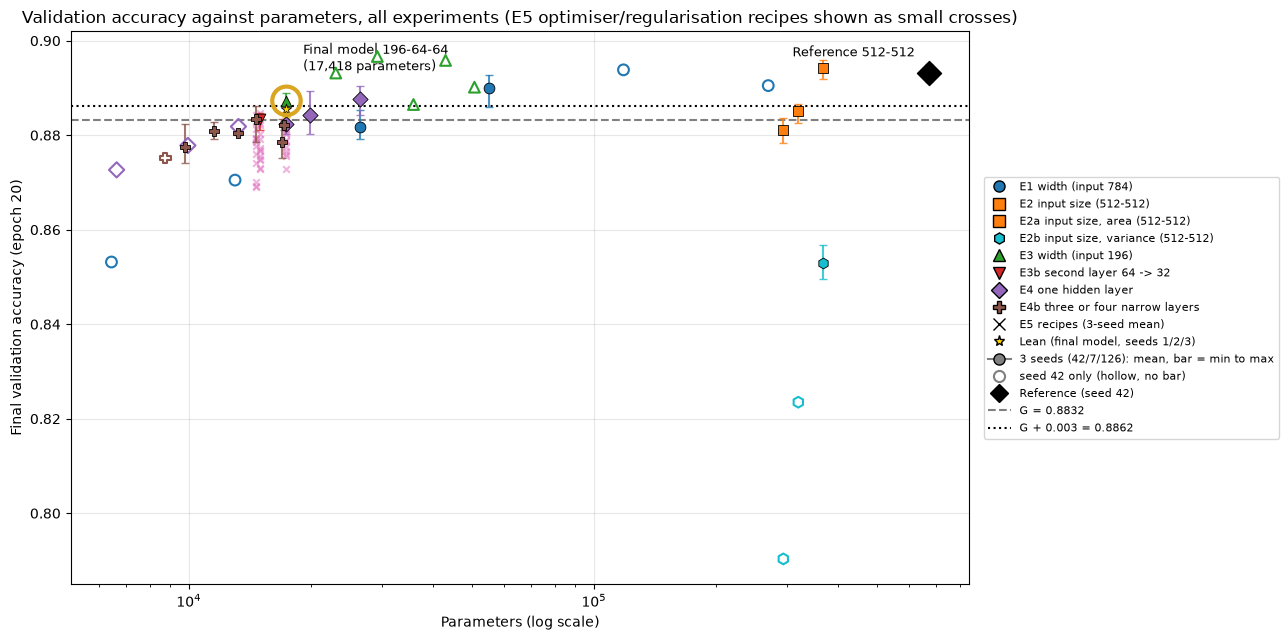

In [51]:
# Final version of the accuracy-against-parameters plot, including the final model once it has been evaluated.
# Validation accuracy only: no test accuracy is drawn. It needs the Lean-* rows that Section 8 records.
if not LEAN_READY:
    print('Pending test evaluation: the final model has not been trained yet (LEAN_READY is False), so this plot is the one of Section 7.')
else:
    plot_frontier(models_table(results))

---

## Submission Checklist

Before submitting, ensure you have:

- [ ] Filled in your name and date at the top of this notebook
- [ ] Trained the reference model without changing it
- [ ] Completed at least three experiments and recorded every model in the results table
- [ ] Plotted accuracy against parameters
- [ ] Trained your lean model with three seeds and filled in the Lean Network Card
- [ ] Run the entire notebook from top to bottom without errors (`Runtime > Restart and run all`)
- [ ] Documented your analysis in all markdown cells
- [ ] Documented your AI assistant usage
- [ ] Shared this notebook with "Anyone with the link can view"
- [ ] Included the link to this notebook in your PDF report
- [ ] Prepared your PDF report with all required sections

**Good luck!**